# ETTm1 End-to-End Forecasting Notebook

This notebook implements a full ETTm1 forecasting workflow with standardized splits, metrics, and reporting conventions for reproducible comparison.
It covers data quality checks, feature preparation, baseline and conventional machine models, deep models, interpretability, ablations, robustness tests, and deployment-oriented conclusions.

## Table of Contents
1. Data Loading and Setup
2. Exploratory Data Analysis
3. Preprocessing and Feature Engineering
4. Baseline and Conventional Machine Models (with Optuna Tuning)
5. Deep Learning Models (with Optuna Tuning)
6. Model Comparison and Visualization
7. Interpretability and Error Diagnostics
8. Ablation Studies
9. Robustness and Stress Testing
10. Final Conclusions and Deployment Recommendations

## Environment Setup

Before running this cell, ensure `requirements.txt` is placed in the **same directory** as this notebook.

If using Azure or JupyterHub, upload `requirements.txt` to the working directory first.

After installation completes, **restart the kernel** before proceeding to the next cell.

In [1]:
import subprocess
import sys
import importlib
import importlib.metadata
import os

# Fallback dependency list if requirements.txt is not found
REQUIREMENTS = [
    # Core
    'numpy',
    'pandas',
    'scikit-learn',
    'scipy',
    # Visualization
    'matplotlib',
    'seaborn',
    # Time-series
    'statsmodels',
    # Deep learning
    'torch',
    'torchvision',
    'pytorch-tcn',
    'reformer-pytorch',
    # ML baseline
    'catboost',
    'optuna',
    # Explainability
    'shap',
    'lime',
    # Notebook runtime
    'ipywidgets',
]

# Package name mapping: display_name -> (import_name, pip_name)
PACKAGES_TO_CHECK = {
    'numpy':       ('numpy',       'numpy'),
    'pandas':      ('pandas',      'pandas'),
    'sklearn':     ('sklearn',     'scikit-learn'),
    'scipy':       ('scipy',       'scipy'),
    'matplotlib':  ('matplotlib',  'matplotlib'),
    'seaborn':     ('seaborn',     'seaborn'),
    'statsmodels': ('statsmodels', 'statsmodels'),
    'torch':       ('torch',       'torch'),
    'optuna':      ('optuna',      'optuna'),
    'shap':        ('shap',        'shap'),
    'lime':        ('lime',        'lime'),
}

def install_from_file(req_path):
    """Install dependencies from requirements.txt."""
    return subprocess.run(
        [sys.executable, '-m', 'pip', 'install', '-r', req_path, '--quiet'],
        capture_output=True, text=True
    )

def install_from_list(req_list):
    """Install dependencies from inline list."""
    return subprocess.run(
        [sys.executable, '-m', 'pip', 'install'] + req_list + ['--quiet'],
        capture_output=True, text=True
    )

def verify_packages(packages):
    """Verify installed packages and return (installed_lines, missing_list)."""
    missing = []
    installed = []
    for display_name, (import_name, pip_name) in packages.items():
        try:
            importlib.import_module(import_name)
            try:
                version = importlib.metadata.version(pip_name)
            except importlib.metadata.PackageNotFoundError:
                mod = importlib.import_module(import_name)
                version = getattr(mod, '__version__', 'installed')
            installed.append(f'  {display_name:<14}: {version}')
        except ImportError:
            missing.append(display_name)
    return installed, missing

# Determine installation source
req_path = 'requirements.txt'
used_fallback = False

if os.path.exists(req_path):
    print(f'requirements.txt found at: {os.path.abspath(req_path)}')
    print('Installing dependencies from requirements.txt ...')
    result = install_from_file(req_path)
else:
    print('[WARNING] requirements.txt not found in the current directory.')
    print(f'          Current directory: {os.getcwd()}')
    print('          Falling back to inline dependency list ...')
    used_fallback = True
    result = install_from_list(REQUIREMENTS)

# Check installation result
if result.returncode != 0:
    print('\n[ERROR] pip install failed:')
    print(result.stderr)
    print('\nPlease check the error above and resolve manually.')
    raise RuntimeError('Dependency installation failed.')
else:
    if used_fallback:
        print('Fallback installation completed successfully.')
        print('[NOTE] For full reproducibility, please place requirements.txt')
        print(f'       in the same directory as this notebook: {os.getcwd()}')
    else:
        print('Installation from requirements.txt completed successfully.')

# Verify packages and print summary
print('\nPackage verification:')
installed_lines, missing = verify_packages(PACKAGES_TO_CHECK)

for line in installed_lines:
    print(line)

if missing:
    print(f'\n[WARNING] The following packages could not be imported: {missing}')
    print('          Please re-run this cell or manually install the missing packages.')
else:
    print('\nAll required packages are available.')

print('\n[REMINDER] If any package was freshly installed or upgraded,')
print('           please restart the kernel before running further cells.')

requirements.txt found at: e:\Desktop\WM9B7-ETTm-Forecasting\requirements.txt
Installing dependencies from requirements.txt ...
Installation from requirements.txt completed successfully.

Package verification:
  numpy         : 2.4.4
  pandas        : 3.0.2
  sklearn       : 1.8.0
  scipy         : 1.17.1
  matplotlib    : 3.10.8
  seaborn       : 0.13.2
  statsmodels   : 0.14.6
  torch         : 2.11.0+cu128
  optuna        : 4.8.0
  shap          : 0.51.0
  lime          : 0.2.0.1

All required packages are available.

[REMINDER] If any package was freshly installed or upgraded,
           please restart the kernel before running further cells.


# 1. Data Loading and Setup

This section configures reproducibility controls, runtime settings, and data paths, then loads the ETTm1 source data.
It establishes a deterministic and validated starting point for all downstream experiments.

In [2]:
# Data Loading and Setup
import os
import sys
import json
import time
import math
import hashlib
import random
import subprocess
import importlib
from pathlib import Path
from types import SimpleNamespace

# Data science and visualization stack
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ML baseline models and preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor

# Deep Learning framework
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# Time-series diagnostics and decomposition
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Optional dependencies for tuning and interpretability
try:
    import optuna
    OPTUNA_AVAILABLE = True
except Exception:
    OPTUNA_AVAILABLE = False

try:
    import shap
    SHAP_AVAILABLE = True
except Exception:
    SHAP_AVAILABLE = False

# Compute device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Global seed configuration for strict reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Environment logging for audit trails
print(f'Python: {sys.version.split()[0]}')
print(f'PyTorch: {torch.__version__}')
print(f'Pandas: {pd.__version__}')
print(f'NumPy: {np.__version__}')
print(f'Device: {device}')
if torch.cuda.is_available():
    print(f'CUDA: {torch.version.cuda}')
    print(f'GPU: {torch.cuda.get_device_name(0)}')
print(f'Optuna available: {OPTUNA_AVAILABLE}')
print(f'SHAP available: {SHAP_AVAILABLE}')

Python: 3.13.12
PyTorch: 2.11.0+cu128
Pandas: 3.0.2
NumPy: 2.4.4
Device: cuda
CUDA: 12.8
GPU: NVIDIA GeForce GTX 1650 Ti
Optuna available: True
SHAP available: True


In [3]:
# Global experiment hyperparameters and model configurations
CONFIG = {
    'seed': SEED,
    'dataset_name': 'ETTm1',
    'paper_split': 'informer_ettm1_12_4_4',
    'task_mode': 'M',  # M: multivariate forecasting

    # Forecasting horizons (Windowing logic)
    'seq_len': 96,
    'label_len': 48,
    'pred_len': 96,

    'batch_size': 512,
    'epochs': 12,
    'patience': 3,
    'learning_rate': 1.0e-3,
    'weight_decay': 3e-3,
    'dropout': 0.30,
    'grad_clip_max_norm': 1.0,
    'use_amp': True,
    'dl_num_workers': 2,
    'dl_pin_memory': True,
    'max_train_seconds_per_model': 720,
    'global_max_epochs_cap': 12,
    'global_patience_cap': 3,
    'aggressive_regularization': True,
    'dl_full_epochs': 20,
    'dl_disable_early_stopping': True,
    'loss_plot_smoothing_window': 3,
    'loss_plot_ymin': 0.2,
    'loss_plot_ymax': 0.6,

    'dl_models': ['LSTM', 'GRU', 'Informer', 'DLinear', 'TCN', 'MLP', 'iTransformer'],

    # dl_tune_mode: 'auto' | 'on' | 'off'
    # - auto: if env supports tuning then tune; otherwise fallback to defaults
    # - on: force attempt tuning; if unavailable still fallback to defaults
    # - off: always skip tuning and use defaults
    'dl_tune_mode': 'auto',
    'dl_tune_enabled': True,
    'dl_tune_trials': 8,
    'dl_tune_timeout_sec': 240,
    'dl_tune_subsample_frac': 0.35,
    'dl_tune_max_samples': 8000,
    'dl_tune_batch_size': 512,
    'dl_tune_num_workers': 2,
    'dl_tune_max_train_seconds_per_trial': 120,
    'dl_tune_pruner': 'hyperband',
    'dl_tune_hb_min_resource': 4,
    'dl_tune_hb_reduction_factor': 2,
    'dl_use_revin_all_models': True,
    'dl_input_noise_std': 0.03,
    'dl_input_noise_scan': [0.03, 0.05, 0.08],
    'dl_early_stop_min_delta': 5e-4,
    'dl_loss': 'mse',
    'dl_scheduler': 'cosine',
    'dl_scheduler_tmax': 12,

    'lstm_hidden': 96,
    'lstm_layers': 1,
    'gru_hidden': 96,
    'gru_layers': 1,
    'lstm_gru_input_dropout': 0.33,
    'lstm_gru_head_dropout': 0.35,

    'informer_d_model': 96,
    'informer_nhead': 4,
    'informer_layers': 1,
    'informer_ffn': 128,
    'informer_dropout': 0.45,
    'informer_droppath': 0.15,
    'informer_pool_last_k': 16,

    'dlinear_ma_window': 37,

    'tcn_channels': 96,
    'tcn_levels': 3,
    'tcn_kernel_size': 3,

    'mlp_hidden': 192,
    'mlp_layers': 1,

    'itransformer_d_model': 96,
    'itransformer_nhead': 4,
    'itransformer_layers': 2,
    'itransformer_ffn': 192,
    'itransformer_dropout': 0.31,
    'itransformer_droppath': 0.06,
    'itransformer_learning_rate': 3.0e-4,

    'ridge_alpha': 1.0,
    'ridge_fit_intercept': True,
    'knn_n_neighbors': 12,
    'knn_weights': 'distance',
    'knn_leaf_size': 30,
    'knn_try_gpu': True,

    'tune_trials': 6,
    'tune_timeout_sec': 180,
    'tune_subsample_frac': 0.25,
    'max_tune_samples': 12000,

    'latency_warmup': 10,
    'latency_runs': 80,
    'xai_kernel_background': 20,
    'xai_kernel_explain': 4,
    'xai_kernel_nsamples': 40
}

# Directory management for experiment artifacts
OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_SUBDIRS = {
    'configs': OUTPUT_DIR / 'configs',
    'figures': OUTPUT_DIR / 'figures',
    'models': OUTPUT_DIR / 'models',
    'tables': OUTPUT_DIR / 'tables',
    'xai': OUTPUT_DIR / 'xai'
}

# Initialize subdirectories
for _p in OUTPUT_SUBDIRS.values():
    _p.mkdir(parents=True, exist_ok=True)

def out_path(kind, filename):
    """Returns the full path for a specific output category."""
    return OUTPUT_SUBDIRS[str(kind)] / str(filename)

# Persistence of configuration for auditability
with open(out_path('configs', 'config.json'), 'w', encoding='utf-8') as f:
    json.dump(CONFIG, f, indent=2)

print('Configuration file written: outputs/configs/config.json')

Configuration file written: outputs/configs/config.json


In [4]:
# Dataset source and local persistence for reproducibility
dataset_name = 'ETTm1'
dataset_key = 'ettm1'
DATA_URL = 'https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTm1.csv'
DATA_PATH = Path('ETTm1.csv')

print(f'Data source: {DATA_URL}')
df = pd.read_csv(DATA_URL)

# Optional local cache write for reproducibility metadata
if DATA_PATH.exists():
    print(f'Local cache exists, skip write: {DATA_PATH}')
else:
    df.to_csv(DATA_PATH, index=False)
    print(f'Local cache created: {DATA_PATH}')

# Standardize temporal index and enforce chronological order
if 'date' not in df.columns:
    raise ValueError('Expected a date column named "date" in the dataset.')
df['date'] = pd.to_datetime(df['date'])
duplicate_count = df.duplicated(subset='date').sum()
if duplicate_count > 0:
    print(f'Removed duplicate timestamps: {duplicate_count}')
    df = df.drop_duplicates(subset='date')
df = df.sort_values('date').reset_index(drop=True)

# Data integrity fingerprinting
sha256 = hashlib.sha256(df.to_csv(index=False).encode('utf-8')).hexdigest()
print(f'Dataset: {dataset_name}')
print(f'Data shape: {df.shape}')
print(f'Date range: {df.date.min()} -> {df.date.max()}')
print(f'SHA256 (current dataframe): {sha256[:16]}...')
print('Null counts:')
print(df.isnull().sum())

# Validate 15-min frequency and perform gap alignment
expected_freq = '15min'
actual_ts = pd.DatetimeIndex(df['date'])
expected_ts = pd.date_range(start=actual_ts.min(), end=actual_ts.max(), freq=expected_freq)
missing_ts = expected_ts.difference(actual_ts)
extra_ts = actual_ts.difference(expected_ts)

print(f'Expected freq: {expected_freq}')
print(f'Expected timestamps: {len(expected_ts)}, actual: {len(actual_ts)}')
print(f'Missing timestamps: {len(missing_ts)} | Extra timestamps: {len(extra_ts)}')

if len(missing_ts) > 0:
    print('First missing timestamps:', list(missing_ts[:5]))
if len(extra_ts) > 0:
    print('First extra timestamps:', list(extra_ts[:5]))
if len(missing_ts) > 0 or len(extra_ts) > 0:
    print(f'Data discontinuity detected. Expected: {len(expected_ts)}, Actual: {len(actual_ts)}')
    expected_ts.name = 'date'
    df = df.set_index('date').reindex(expected_ts)
    df = df.ffill().bfill().reset_index()
    print(f'Alignment complete. New shape: {df.shape}')
else:
    print('Timestamp continuity check: passed.')

# Define multivariate features and compute descriptive statistics
base_cols = ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
if all(c in df.columns for c in base_cols):
    numeric_cols = base_cols.copy()
else:
    numeric_cols = [c for c in df.columns if c != 'date' and pd.api.types.is_numeric_dtype(df[c])]

print(f'Numeric feature columns ({len(numeric_cols)}): {numeric_cols}')
print(df[numeric_cols].describe().T)

df.head()

Data source: https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTm1.csv
Local cache exists, skip write: ETTm1.csv
Dataset: ETTm1
Data shape: (69680, 8)
Date range: 2016-07-01 00:00:00 -> 2018-06-26 19:45:00
SHA256 (current dataframe): b80f6e35ba995b87...
Null counts:
date    0
HUFL    0
HULL    0
MUFL    0
MULL    0
LUFL    0
LULL    0
OT      0
dtype: int64
Expected freq: 15min
Expected timestamps: 69680, actual: 69680
Missing timestamps: 0 | Extra timestamps: 0
Timestamp continuity check: passed.
Numeric feature columns (7): ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
        count       mean       std        min    25%     50%     75%     max
HUFL  69680.0   7.413993  7.082928 -23.242001  5.827   8.841  11.788  24.180
HULL  69680.0   2.261418  2.041293  -5.693000  0.804   2.210   3.684  10.315
MUFL  69680.0   4.322226  6.829189 -26.367001  3.305   6.005   8.635  18.087
MULL  69680.0   0.896509  1.807239  -6.041000 -0.284   0.959   2.203   7.853
LUFL  6

,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,2016-07-01 00:15:00,5.760,2.076,1.492,0.426,4.264,1.401,30.459999
2,2016-07-01 00:30:00,5.760,1.942,1.492,0.391,4.234,1.310,30.038000
3,2016-07-01 00:45:00,5.760,1.942,1.492,0.426,4.234,1.310,27.013000
4,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001


Key Finding: The ETTm1 dataset (69,680 x 8) is temporally complete at a 15-minute frequency, with zero missing values and full timestamp continuity, while the seven numeric variables exhibit substantial cross-feature scale and dispersion heterogeneity.

# 2. Exploratory Data Analysis (EDA)

This section examines temporal behavior, scale characteristics, and cross-variable structure using summary statistics and visual diagnostics.
Its purpose is to validate data quality and inform subsequent feature and model design choices.

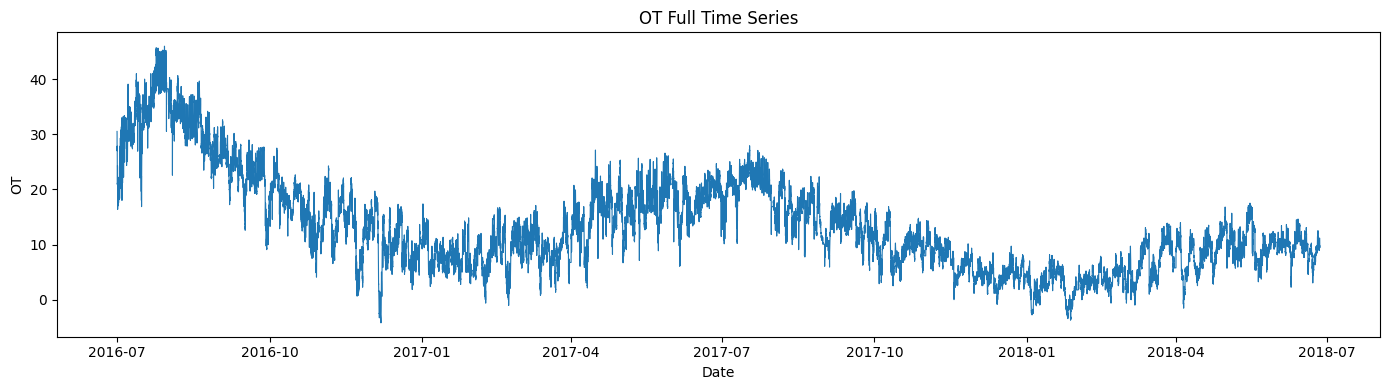

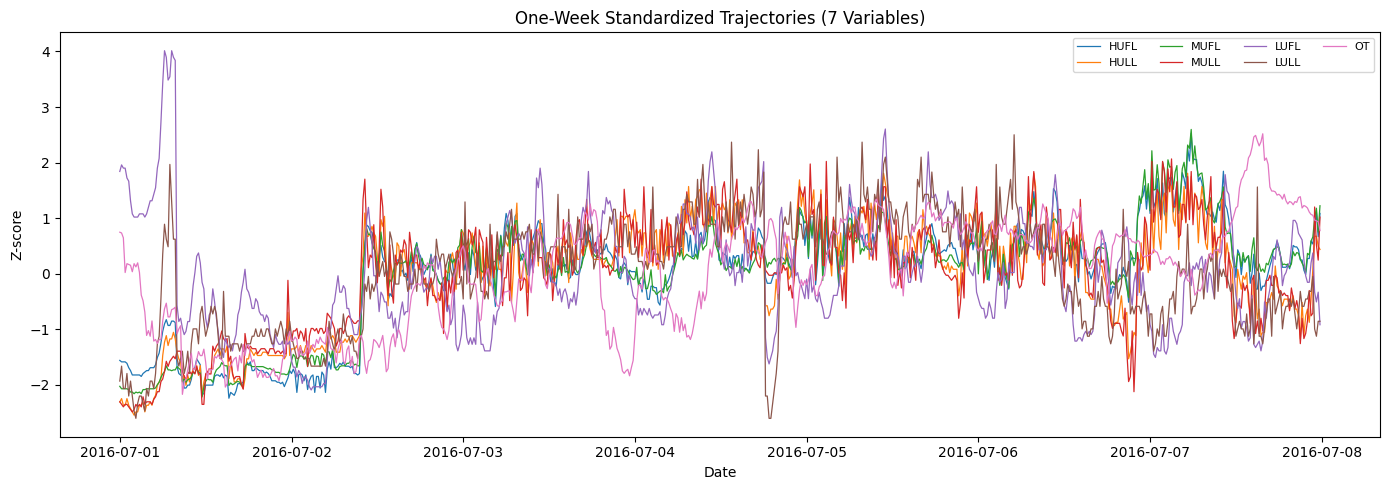

In [5]:
# EDA for multivariate M setting
base_cols = ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']

# Visualise long-term temporal trends and seasonal variations for the target (OT)
plt.figure(figsize=(14, 4))
plt.plot(df['date'], df['OT'], linewidth=0.8)
plt.title('OT Full Time Series')
plt.xlabel('Date')
plt.ylabel('OT')
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_ot_full_series.png'), dpi=150)
plt.show()

# Isolate a high-resolution one-week window for granular periodicity analysis
week_points = 7 * 24 * 4
subset = df.iloc[:week_points].copy()

# Standardise via Z-score to compare cross-variable trajectories and synchronization
z = subset[base_cols].copy()
z = (z - z.mean()) / (z.std() + 1e-8)
plt.figure(figsize=(14, 5))
for c in base_cols:
    plt.plot(subset['date'], z[c], linewidth=0.9, label=c)
plt.title('One-Week Standardized Trajectories (7 Variables)')
plt.xlabel('Date')
plt.ylabel('Z-score')
plt.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_week_multivariate_standardized.png'), dpi=150)
plt.show()

Key Finding: The OT series shows clear long-horizon regime shifts with recurring seasonal-like oscillations, while one-week standardized trajectories reveal synchronized short-term co-movement across variables alongside distinct feature-specific volatility and amplitude profiles.

ADF stationarity test across all target variables
Variable  ADF Statistic  p-value     Status
    HUFL       -43.0398 0.00e+00 Stationary
    HULL       -19.6061 0.00e+00 Stationary
    MUFL       -44.1093 0.00e+00 Stationary
    MULL       -19.0080 0.00e+00 Stationary
    LUFL       -25.1735 0.00e+00 Stationary
    LULL       -11.8879 5.96e-22 Stationary
      OT        -6.8655 1.56e-09 Stationary


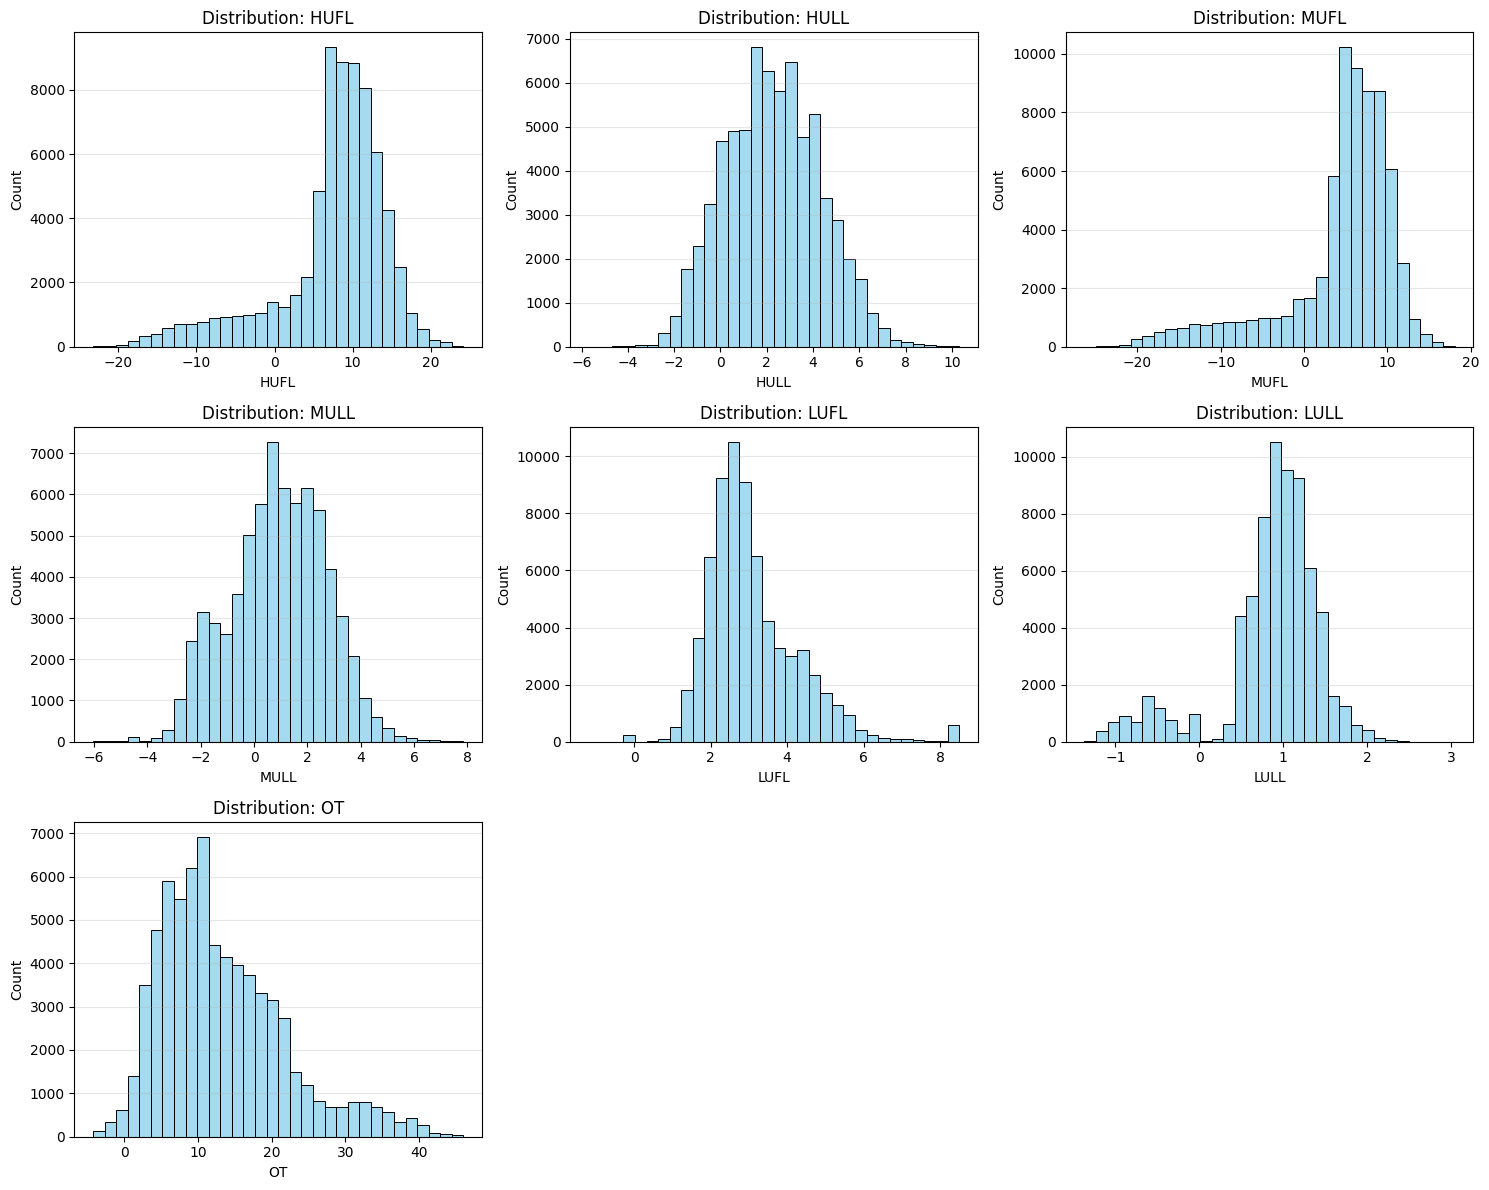

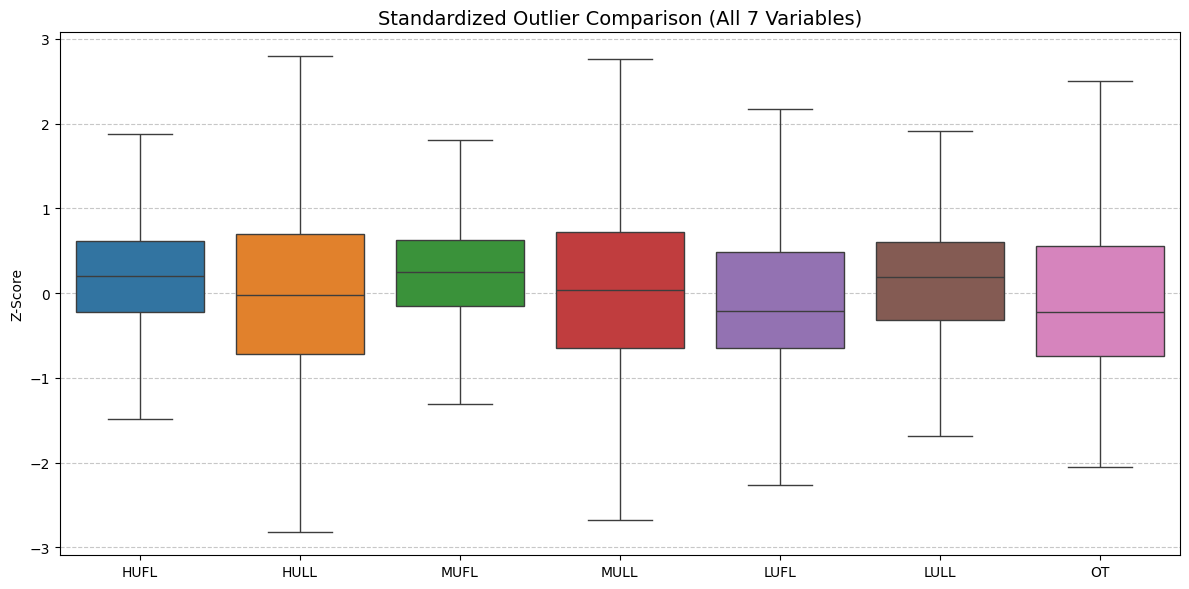

STL variables: ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT'], window: 2688 points


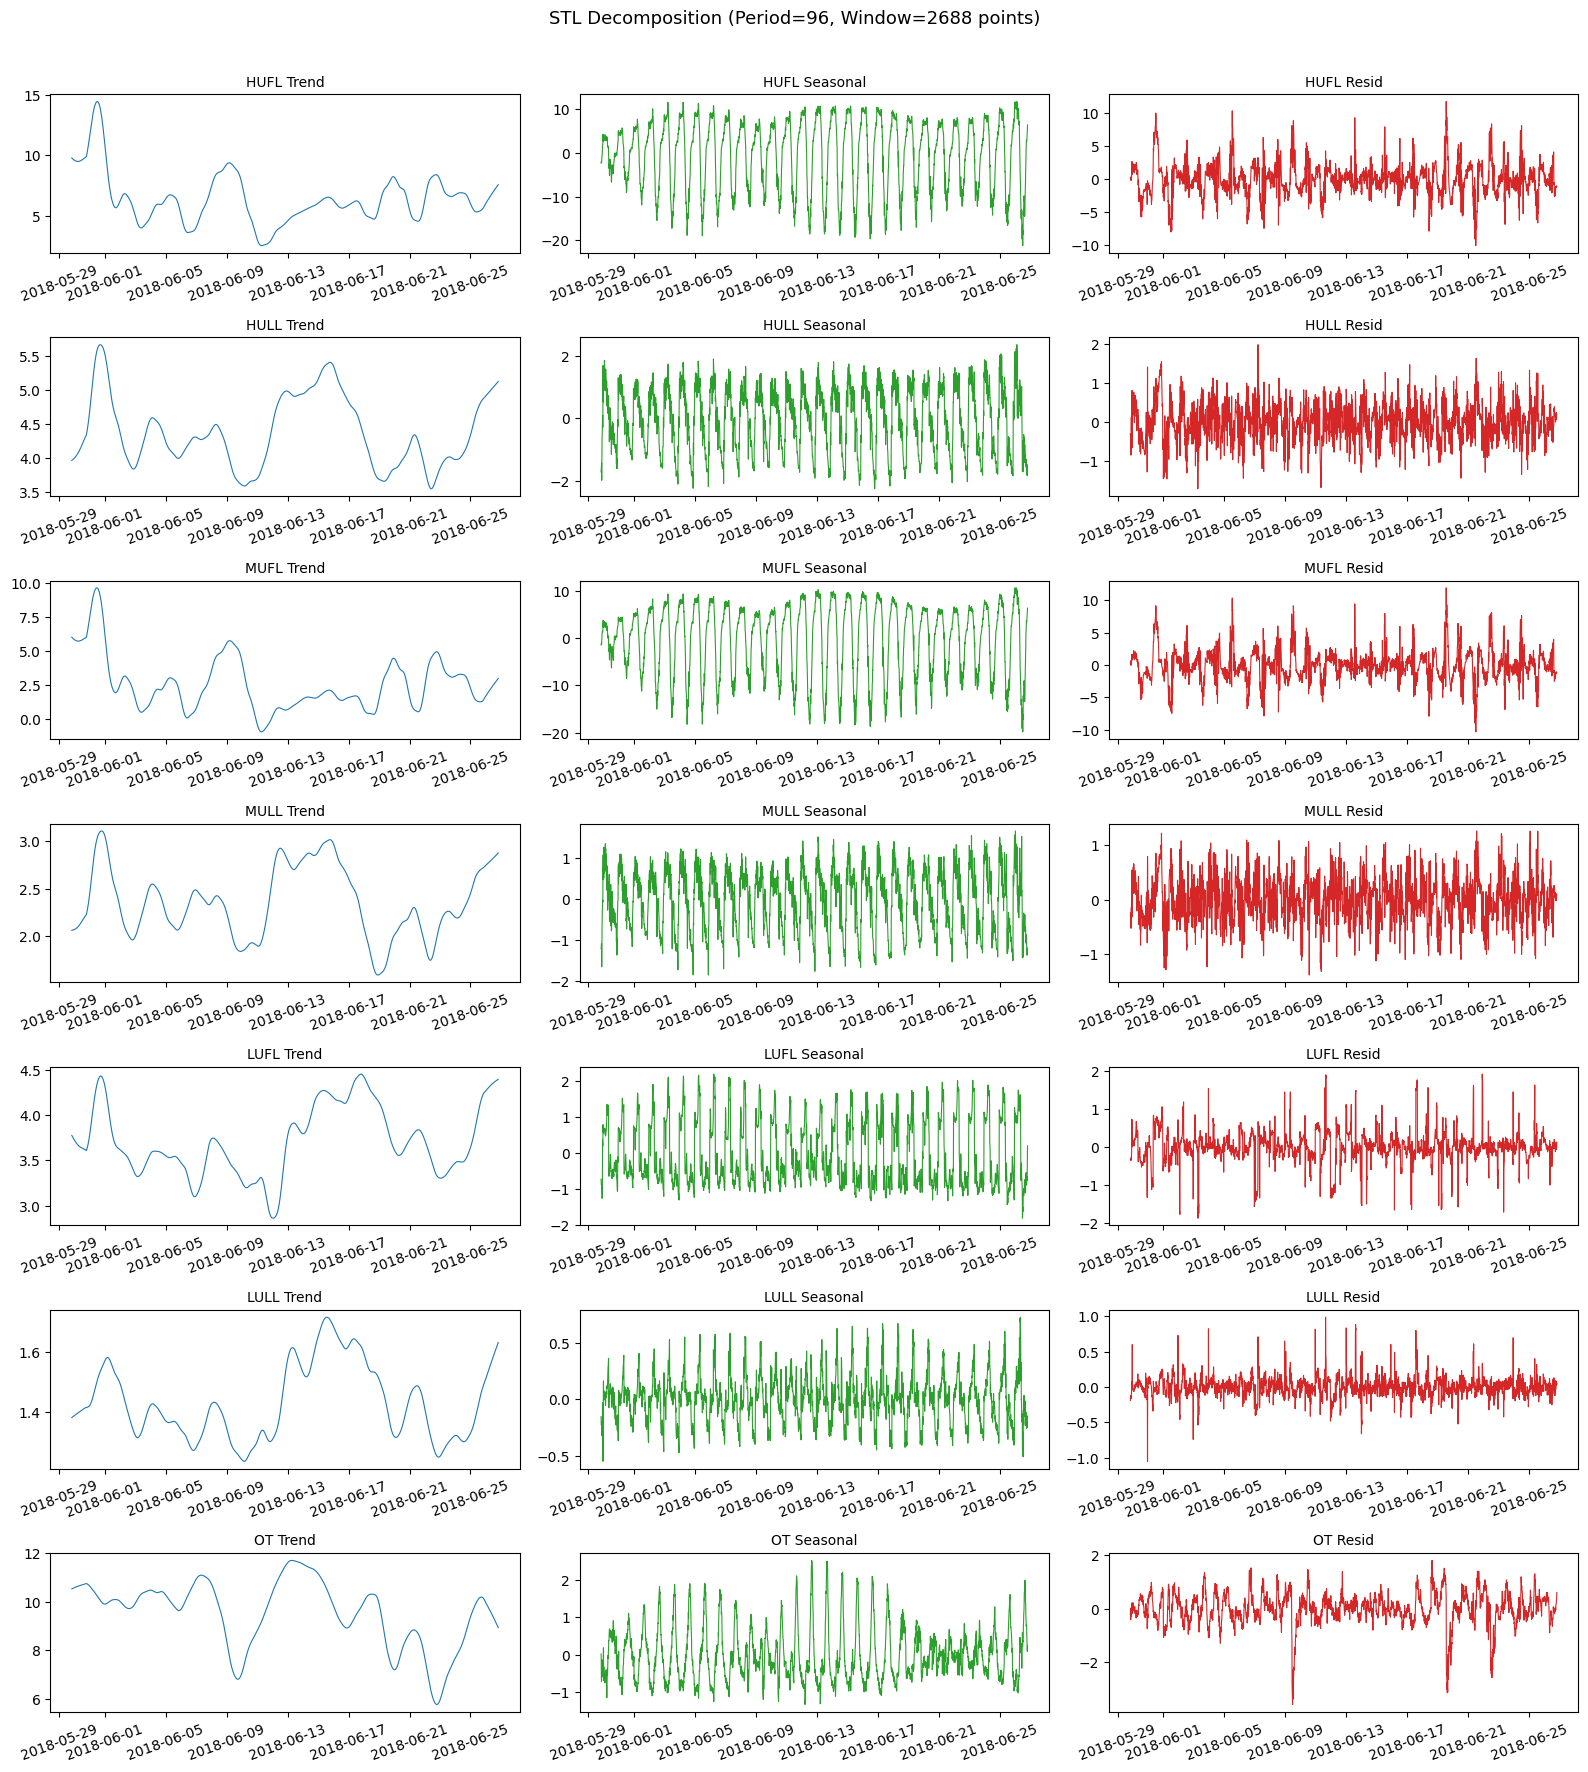

Seasonal strength summary (higher means stronger seasonality):
Variable  Seasonal Strength
    HUFL           0.913425
    MUFL           0.904844
    HULL           0.825719
    LUFL           0.809708
    MULL           0.776075
    LULL           0.694603
      OT           0.586192


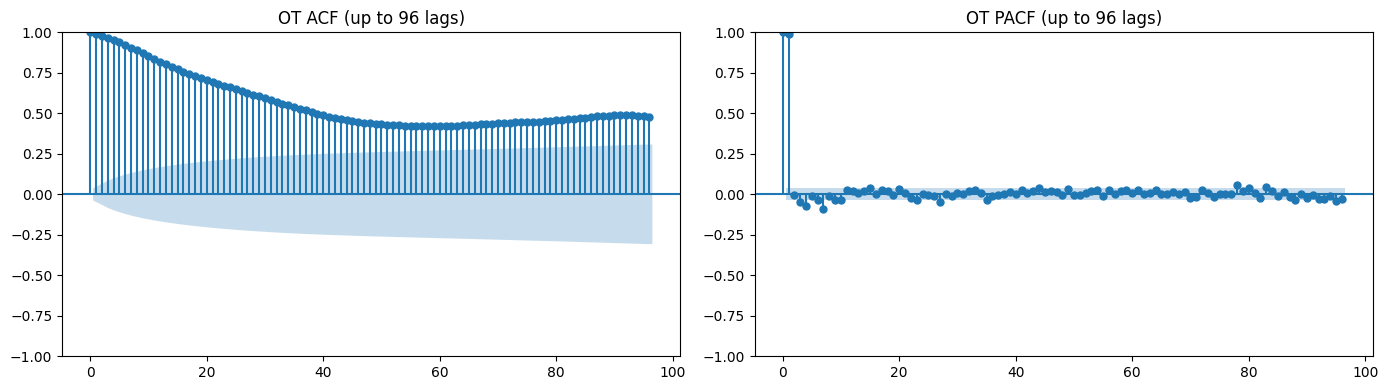

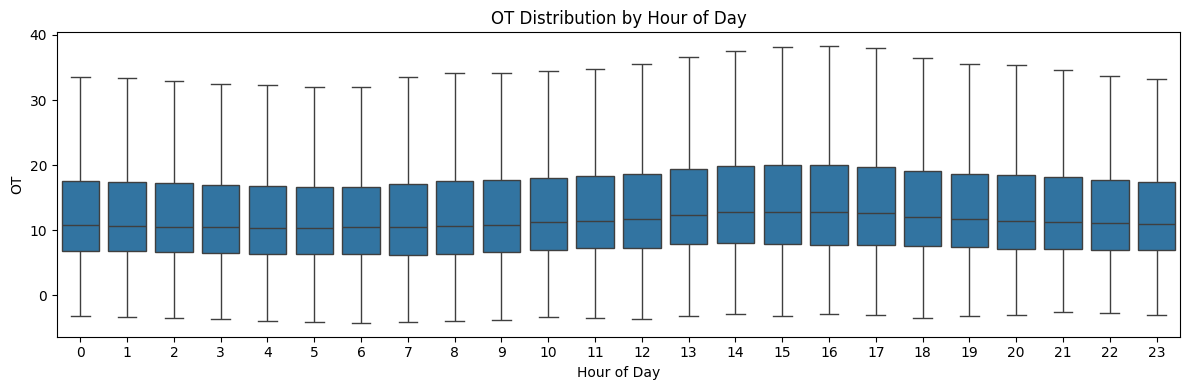

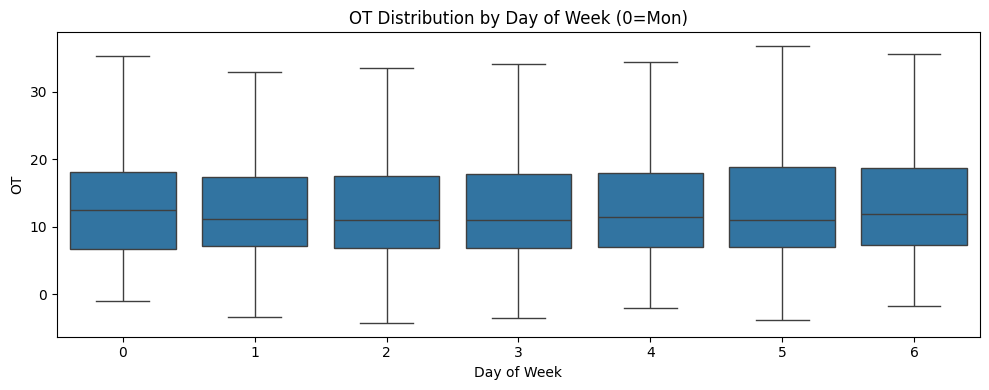

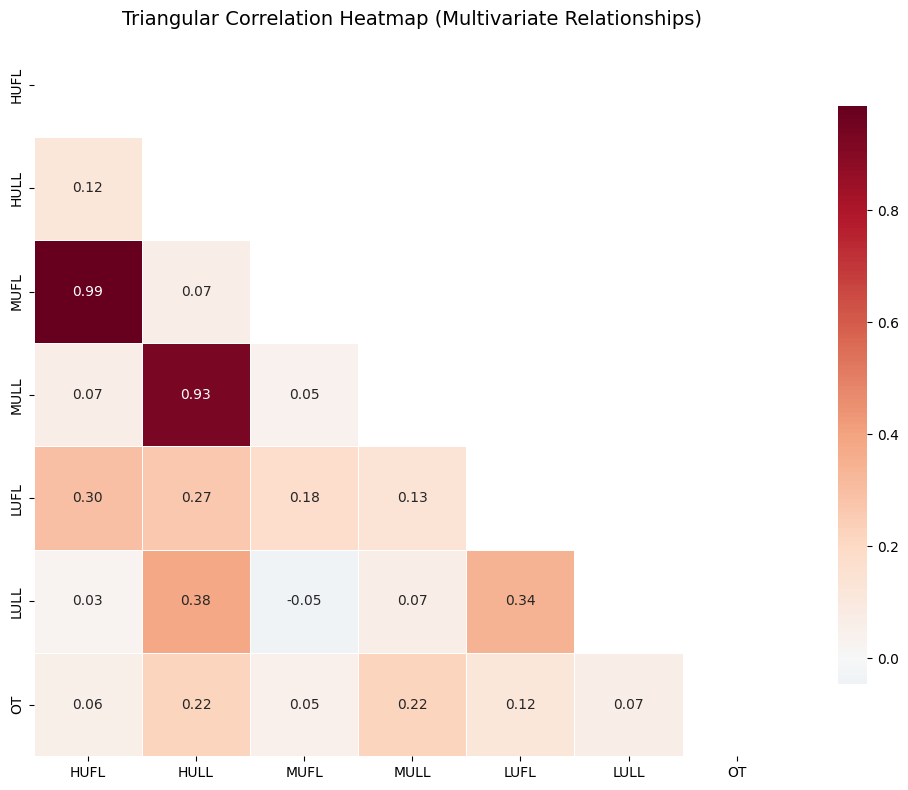

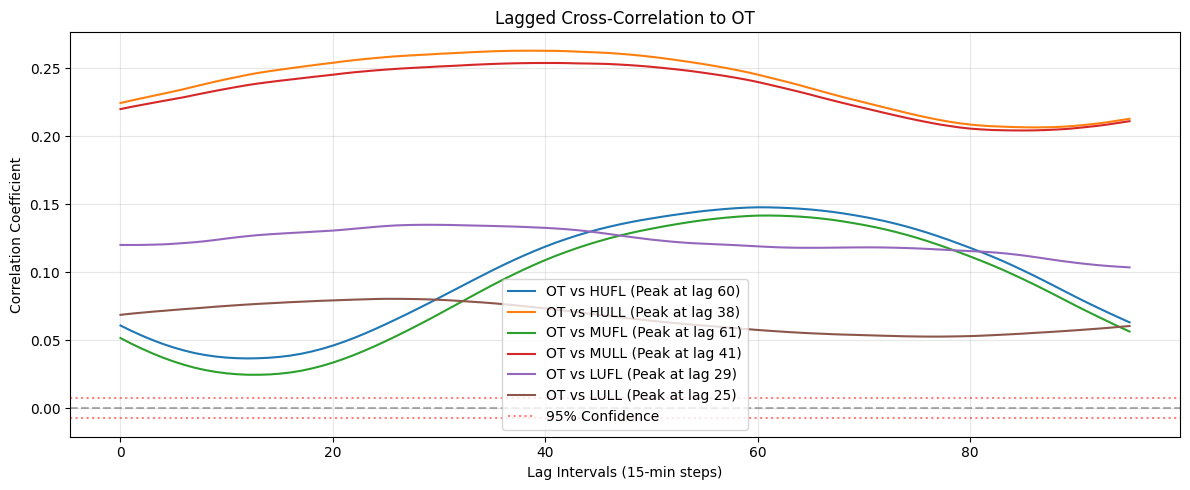

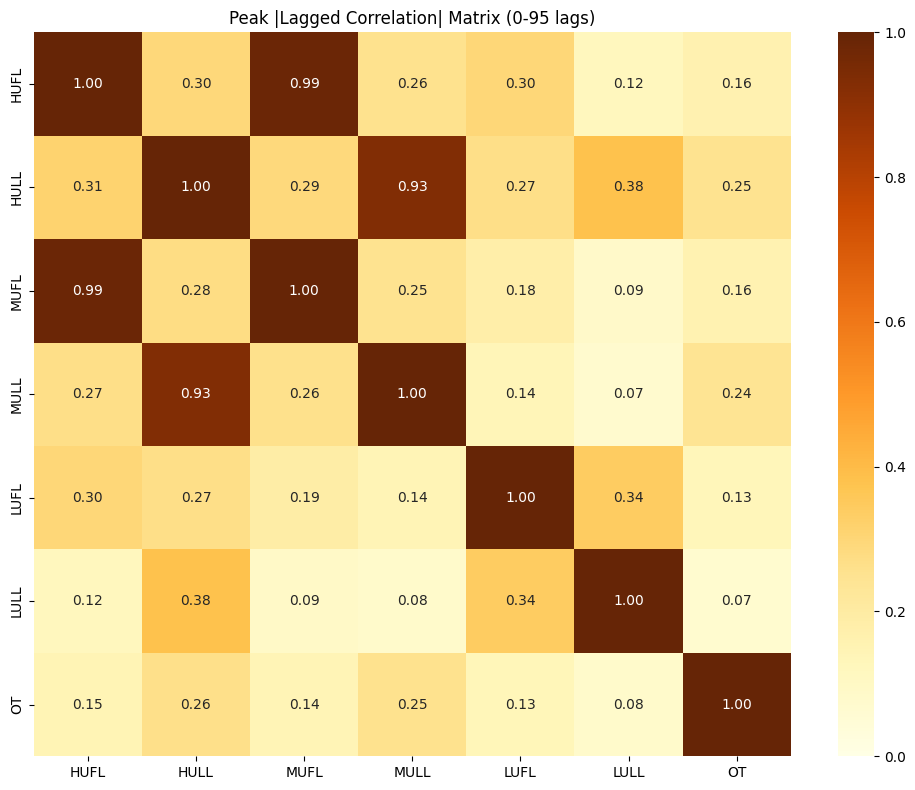

Strongest pair by peak lagged correlation: HUFL vs MUFL (0.987)
HUFL-HULL peak lagged correlation: 0.296. This may indicate feature redundancy.
EDA diagnostics completed in 24.20s


In [6]:
# Perform Augmented Dickey-Fuller (ADF) tests to verify feature stationarity and unit root presence
print('ADF stationarity test across all target variables')

if 'base_cols' not in globals():
    base_cols = ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
if 'numeric_cols' not in globals():
    numeric_cols = [c for c in base_cols if c in df.columns]
if 'date' not in df.columns:
    raise ValueError('Expected date column in dataframe.')

missing_required = [c for c in base_cols if c not in df.columns]
if len(missing_required) > 0:
    raise ValueError(f'Missing expected base columns: {missing_required}')

numeric_cols = [c for c in numeric_cols if pd.api.types.is_numeric_dtype(df[c])]
if len(numeric_cols) == 0:
    raise ValueError('No numeric columns available for EDA.')

# Maintain consistent feature ordering for all subsequent diagnostic visualisations
ordered_cols = [c for c in base_cols if c in numeric_cols]
extra_cols = [c for c in numeric_cols if c not in ordered_cols]
numeric_cols = ordered_cols + extra_cols

t0 = time.perf_counter()

adf_results = []
for col in base_cols:
    res = adfuller(df[col].values, maxlag=24, autolag='AIC')
    is_stationary = res[1] < 0.05
    adf_results.append({
        'Variable': col,
        'ADF Statistic': float(f'{res[0]:.4f}'),
        'p-value': f'{res[1]:.2e}' if res[1] < 0.001 else f'{res[1]:.6f}',
        'Status': 'Stationary' if is_stationary else 'Non-Stationary'
    })

adf_df = pd.DataFrame(adf_results)
print(adf_df.to_string(index=False))

# Visualize marginal distributions to assess skewness and multi-modality
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes_flat = axes.flatten()
for i, col in enumerate(numeric_cols):
    sns.histplot(data=df, x=col, bins=32, kde=False, ax=axes_flat[i], color='skyblue')
    axes_flat[i].set_title(f'Distribution: {col}', fontsize=12)
    axes_flat[i].grid(axis='y', alpha=0.3)
for j in range(len(numeric_cols), len(axes_flat)):
    axes_flat[j].axis('off')
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_distributions.png'), dpi=150)
plt.show()

# Compare feature variances and outlier profiles via standardized boxplots
plt.figure(figsize=(12, 6))
df_std = (df[numeric_cols] - df[numeric_cols].mean()) / (df[numeric_cols].std() + 1e-8)
sns.boxplot(data=df_std, showfliers=False)
plt.title('Standardized Outlier Comparison (All 7 Variables)', fontsize=14)
plt.ylabel('Z-Score')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_boxplot_standardized.png'), dpi=150)
plt.show()

# Execute STL decomposition to quantify trend, seasonality, and residual (noise) components
stl_period = 24 * 4
stl_cols = [c for c in base_cols if c in df.columns]
stl_points = min(len(df), stl_period * 7 * 4)  # last 4 weeks
stl_df = df[['date'] + stl_cols].iloc[-stl_points:].copy()
print(f'STL variables: {stl_cols}, window: {stl_points} points')

n_rows = len(stl_cols)
fig, axes = plt.subplots(n_rows, 3, figsize=(16, 2.5 * n_rows), sharex=False)
if n_rows == 1:
    axes = np.array([axes])

seasonal_strength_rows = []
for i, col in enumerate(stl_cols):
    y = stl_df[col].astype(float).values
    if np.isnan(y).any():
        y = pd.Series(y).ffill().bfill().values
    stl_res = STL(y, period=stl_period, robust=False).fit()

    # Calculate seasonal strength metric: 1 - Var(resid) / Var(seasonal + resid)
    seasonal_var = np.var(stl_res.seasonal)
    resid_var = np.var(stl_res.resid)
    denom_var = seasonal_var + resid_var + 1e-8
    seasonal_strength = max(0.0, 1.0 - (resid_var / denom_var))
    seasonal_strength_rows.append({'Variable': col, 'Seasonal Strength': seasonal_strength})

    axes[i, 0].plot(stl_df['date'], stl_res.trend, linewidth=0.8, color='#1f77b4')
    axes[i, 0].set_title(f'{col} Trend', fontsize=10)
    axes[i, 1].plot(stl_df['date'], stl_res.seasonal, linewidth=0.8, color='#2ca02c')
    axes[i, 1].set_title(f'{col} Seasonal', fontsize=10)
    axes[i, 2].plot(stl_df['date'], stl_res.resid, linewidth=0.8, color='#d62728')
    axes[i, 2].set_title(f'{col} Resid', fontsize=10)
for ax in axes.flatten():
    ax.tick_params(axis='x', labelrotation=20)
plt.suptitle(f'STL Decomposition (Period=96, Window={stl_points} points)', y=1.01, fontsize=13)
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_stl_decomposition_all_variables.png'), dpi=150)
plt.show()

seasonal_strength_df = pd.DataFrame(seasonal_strength_rows).sort_values('Seasonal Strength', ascending=False)
print('Seasonal strength summary (higher means stronger seasonality):')
print(seasonal_strength_df.to_string(index=False))

# Analyze ACF/PACF to identify autoregressive structures and justify the 96-step look-back window
acf_lags = min(96, max(8, len(df) // 2 - 1))
ot_points = min(len(df), stl_period * 7 * 4)
ot_series = df['OT'].iloc[-ot_points:].astype(float).values

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(ot_series, lags=acf_lags, ax=axes[0], alpha=0.05, title='OT ACF (up to 96 lags)')
plot_pacf(ot_series, lags=acf_lags, ax=axes[1], alpha=0.05, method='ywm', title='OT PACF (up to 96 lags)')
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_acf_pacf_ot.png'), dpi=150)
plt.show()

# Examine intraday and weekly periodicities to confirm seasonal cyclic patterns for OT
plt.figure(figsize=(12, 4))
sns.boxplot(x=df['date'].dt.hour, y=df['OT'], showfliers=False)
plt.title('OT Distribution by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('OT')
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_ot_by_hour_of_day.png'), dpi=150)
plt.show()

plt.figure(figsize=(10, 4))
sns.boxplot(x=df['date'].dt.dayofweek, y=df['OT'], showfliers=False)
plt.title('OT Distribution by Day of Week (0=Mon)')
plt.xlabel('Day of Week')
plt.ylabel('OT')
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_ot_by_day_of_week.png'), dpi=150)
plt.show()

# Compute contemporaneous Pearson correlations to identify feature redundancy and multi-collinearity
corr = df[numeric_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, cmap='RdBu_r', center=0,
            fmt='.2f', linewidths=.5, cbar_kws={"shrink": .8})
plt.title('Triangular Correlation Heatmap (Multivariate Relationships)', fontsize=14)
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_correlation_heatmap.png'), dpi=150)
plt.show()

# Compute lagged cross-correlations to identify leading indicators for the target (OT)
arr = df[numeric_cols].astype(np.float32).values
arr_z = (arr - arr.mean(axis=0, keepdims=True)) / (arr.std(axis=0, keepdims=True) + 1e-8)
lags = min(96, len(arr_z) - 2)
if lags < 2:
    raise ValueError('Not enough samples for lagged correlation diagnostics.')

p = arr_z.shape[1]
lag_peak = np.full((p, p), -np.inf, dtype=np.float32)
other_idx = []
ot_curve_mat = None
if 'OT' in numeric_cols:
    ot_idx = numeric_cols.index('OT')
    other_idx = [i for i, c in enumerate(numeric_cols) if c != 'OT']
    ot_curve_mat = np.zeros((lags, len(other_idx)), dtype=np.float32)

for k in range(lags):
    x = arr_z[k:, :]
    y = arr_z[:len(arr_z) - k, :]
    corr_k = (x.T @ y) / max(1, x.shape[0])
    lag_peak = np.maximum(lag_peak, np.abs(corr_k))
    if ot_curve_mat is not None:
        ot_curve_mat[k, :] = corr_k[ot_idx, other_idx]

if ot_curve_mat is not None:
    plt.figure(figsize=(12, 5))
    for j, idx in enumerate(other_idx):
        curve = ot_curve_mat[:, j]
        max_lag = int(np.argmax(np.abs(curve)))
        col = numeric_cols[idx]
        plt.plot(range(lags), curve, label=f'OT vs {col} (Peak at lag {max_lag})')
    conf_level = 2.0 / np.sqrt(len(df))
    plt.axhline(conf_level, color='red', linestyle=':', alpha=0.5, label='95% Confidence')
    plt.axhline(-conf_level, color='red', linestyle=':', alpha=0.5)
    plt.axhline(0, color='black', linestyle='--', alpha=0.3)
    plt.title('Lagged Cross-Correlation to OT')
    plt.xlabel('Lag Intervals (15-min steps)')
    plt.ylabel('Correlation Coefficient')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(out_path('figures', 'Eda_lagged_cross_correlation_to_ot.png'), dpi=150)
    plt.show()

# Generate peak absolute lagged correlation matrix to summarize the global dependency structure
lag_peak_df = pd.DataFrame(lag_peak, index=numeric_cols, columns=numeric_cols)
plt.figure(figsize=(10, 8))
sns.heatmap(lag_peak_df, annot=True, cmap='YlOrBr', vmin=0, vmax=1, fmt='.2f')
plt.title('Peak |Lagged Correlation| Matrix (0-95 lags)')
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_peak_lagged_correlation_matrix.png'), dpi=150)
plt.show()

pair_series = lag_peak_df.where(~np.eye(len(lag_peak_df), dtype=bool)).stack().sort_values(ascending=False)
if len(pair_series) > 0:
    top_pair = pair_series.index[0]
    top_val = pair_series.iloc[0]
    print(f'Strongest pair by peak lagged correlation: {top_pair[0]} vs {top_pair[1]} ({top_val:.3f})')

if 'HUFL' in lag_peak_df.index and 'HULL' in lag_peak_df.columns:
    hufl_hull = float(lag_peak_df.loc['HUFL', 'HULL'])
    print(f'HUFL-HULL peak lagged correlation: {hufl_hull:.3f}. This may indicate feature redundancy.')

print(f'EDA diagnostics completed in {time.perf_counter() - t0:.2f}s')

Key Finding: All seven variables are ADF-stationary, the series exhibits strong multi-scale seasonality with the highest seasonal strength in HUFL and MUFL and a comparatively weaker but still present seasonal component in OT, OT also shows persistent autocorrelation with distinct intraday structure (higher midday levels) and mild weekday variation, and the dependency structure is dominated by very strong coupled pairs (HUFL-MUFL and HULL-MULL) while OT maintains moderate lagged associations mainly with HULL and MULL.

Front vs Back drift summary:


,HUFL_front,HULL_front,MUFL_front,MULL_front,LUFL_front,LULL_front,OT_front,HUFL_back,HULL_back,MUFL_back,MULL_back,LUFL_back,LULL_back,OT_back
mean,7.971978,2.041194,5.086975,0.768985,2.809531,0.782098,17.152580,6.856009,2.481643,3.557478,1.024033,3.356246,0.933717,9.488703
std,5.841680,2.084099,5.533875,1.924083,1.039453,0.638211,9.142191,8.098718,1.973172,7.841141,1.672633,1.235707,0.549781,5.810876


Potential Data Drift Detected
Mean shift ratio (>10%):
OT      0.446806
MULL    0.331668
MUFL    0.300669
HULL    0.215780
LUFL    0.194593
LULL    0.193862
HUFL    0.139986


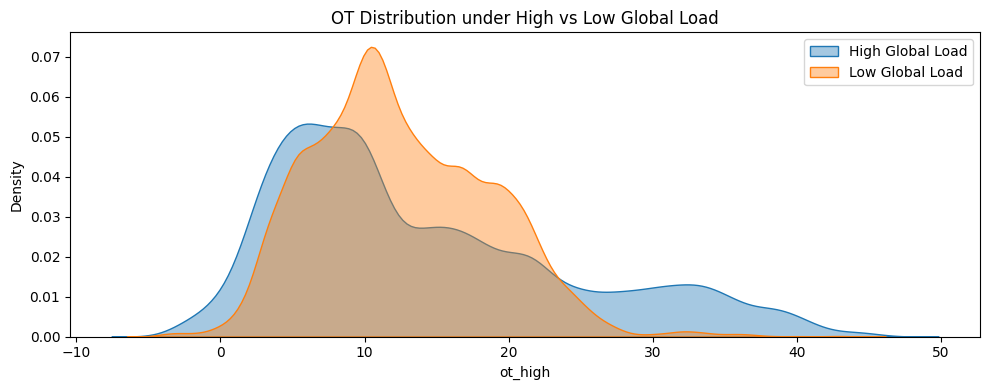

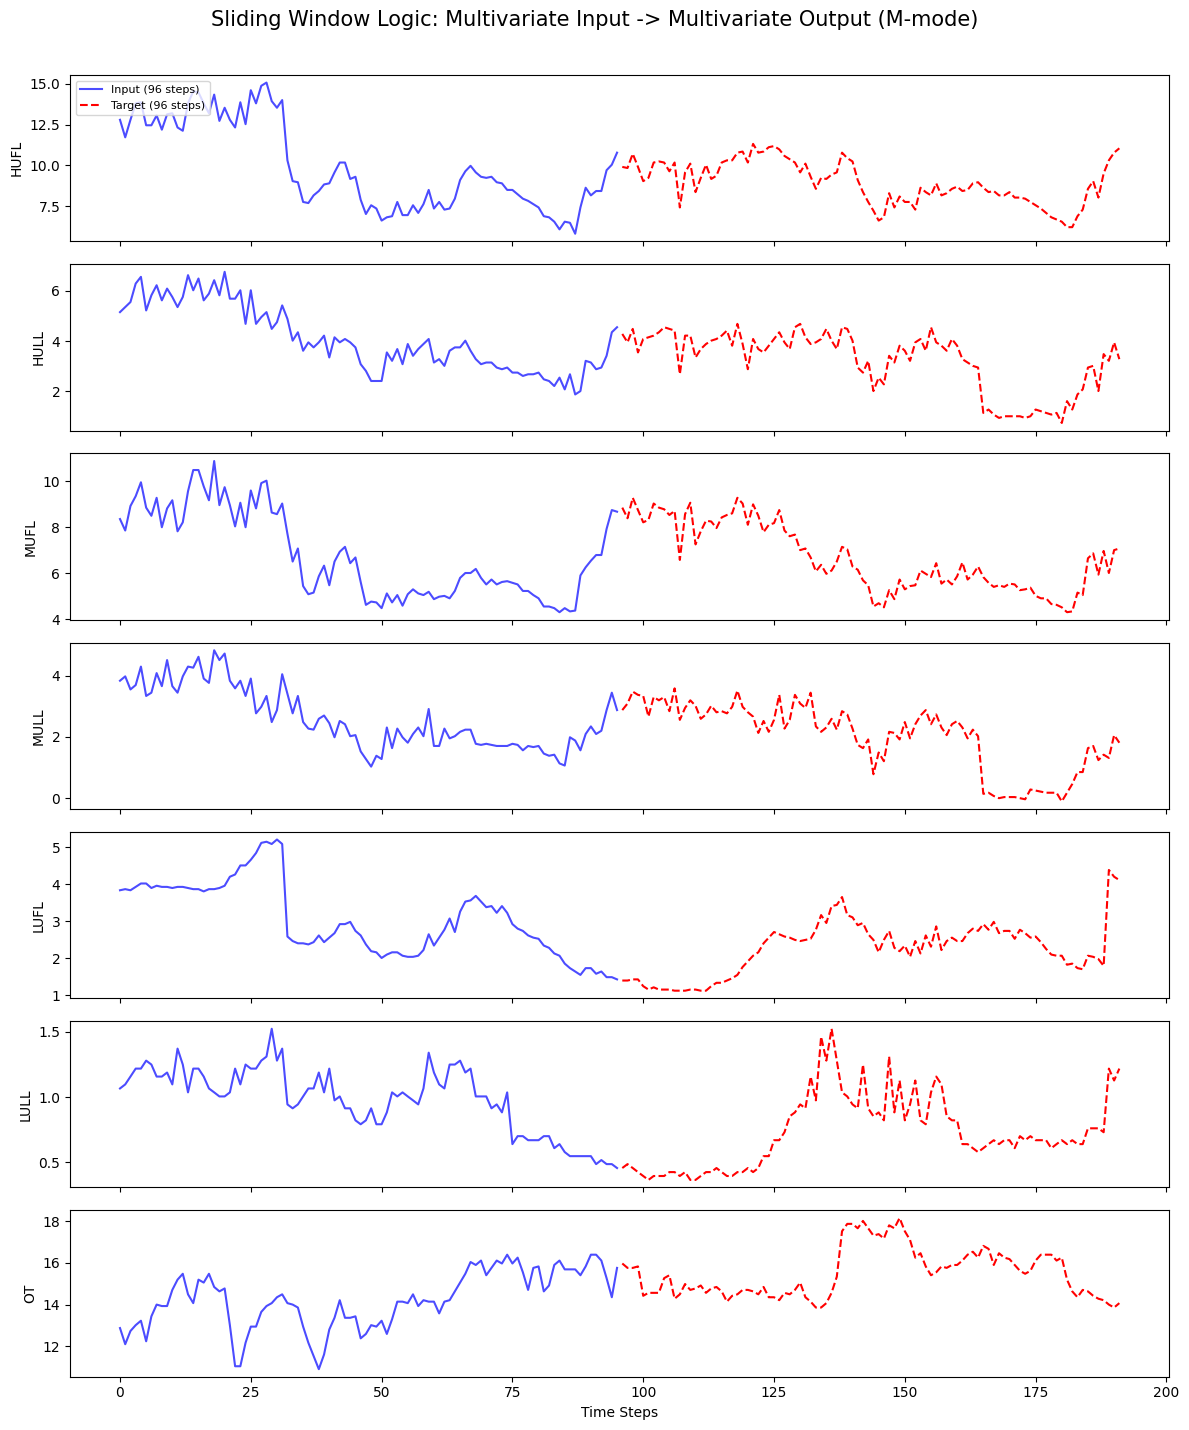

In [7]:
# Assess non-stationarity via statistical drift between temporal partitions
mid = len(df) // 2
front = df.iloc[:mid][numeric_cols].describe().loc[['mean', 'std']]
back = df.iloc[mid:][numeric_cols].describe().loc[['mean', 'std']]
drift_stats = pd.concat([front.add_suffix('_front'), back.add_suffix('_back')], axis=1)
print('Front vs Back drift summary:')
display(drift_stats)

# Detect significant covariate shift using a 10% mean-shift tolerance
mean_front = front.loc['mean']
mean_back = back.loc['mean']
mean_base = np.maximum(np.abs(mean_front.values), 1e-8)
mean_shift_ratio = np.abs(mean_back.values - mean_front.values) / mean_base
mean_shift_series = pd.Series(mean_shift_ratio, index=mean_front.index)
if (mean_shift_series > 0.10).any():
    flagged = mean_shift_series[mean_shift_series > 0.10].sort_values(ascending=False)
    print('Potential Data Drift Detected')
    print('Mean shift ratio (>10%):')
    print(flagged.to_string())
else:
    print('No significant mean drift detected (>10% threshold).')

# Evaluate target (OT) conditional distribution relative to system load intensity
load_cols = ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL']
global_load = df[load_cols].mean(axis=1)
high_load_flag = global_load > global_load.median()
high_df = df.loc[high_load_flag, ['OT']].rename(columns={'OT': 'ot_high'})
low_df = df.loc[~high_load_flag, ['OT']].rename(columns={'OT': 'ot_low'})

plt.figure(figsize=(10, 4))
sns.kdeplot(data=high_df, x='ot_high', label='High Global Load', fill=True, alpha=0.4)
sns.kdeplot(data=low_df, x='ot_low', label='Low Global Load', fill=True, alpha=0.4)
plt.title('OT Distribution under High vs Low Global Load')
plt.legend()
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_ot_by_global_load_level.png'), dpi=150)
plt.show()

# Validate sliding window logic and multivariate synchronization (M-mode)
def visualize_input_output_window(df, config):
    """
    Validates multivariate input-target temporal alignment.
    """
    seq_len = config['seq_len']
    pred_len = config['pred_len']
    
    start_idx = random.randint(0, len(df) - seq_len - pred_len)
    window_data = df.iloc[start_idx : start_idx + seq_len + pred_len]
    
    fig, axes = plt.subplots(7, 1, figsize=(12, 15), sharex=True)
    cols = base_cols
    
    x_input = range(0, seq_len)
    x_output = range(seq_len, seq_len + pred_len)
    
    for i, col in enumerate(cols):
        axes[i].plot(x_input, window_data[col].iloc[:seq_len], 
                     color='blue', label='Input (96 steps)', alpha=0.7)
        axes[i].plot(x_output, window_data[col].iloc[seq_len:], 
                     color='red', label='Target (96 steps)', linestyle='--')
        axes[i].set_ylabel(col)
        if i == 0:
            axes[i].legend(loc='upper left', fontsize=8)
            
    plt.xlabel('Time Steps')
    plt.suptitle(f'Sliding Window Logic: Multivariate Input -> Multivariate Output (M-mode)', fontsize=15)
    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.savefig(out_path('figures', 'Eda_input_output_window.png'), dpi=150)
    plt.show()

visualize_input_output_window(df, CONFIG)

Key Finding: The dataset shows clear front-to-back drift, dominated by OT (44.7% mean shift), with higher global load linked to a heavier OT upper tail and greater spread, and the 96-to-96 sliding-window plot confirms a coherent multivariate input-output mapping.

# 3. Preprocessing and Feature Engineering

This section constructs model-ready inputs by applying chronological splits, cyclical time encoding, train-only scaling, and leakage-safe window generation.
The resulting M-96 tensors provide a consistent input/output interface for all later models.

In [8]:
df_feat = df.copy()

def encode_cyclical(df, col, max_val):
    """
    Encodes periodic temporal features into 2D circular space 
    to preserve cyclical continuity.
    """
    df[col + '_sin'] = np.sin(2 * np.pi * df[col] / max_val)
    df[col + '_cos'] = np.cos(2 * np.pi * df[col] / max_val)
    return df

# Temporal feature engineering: quarter-hour resolution
df_feat['month'] = df_feat.date.dt.month
df_feat['day'] = df_feat.date.dt.day
df_feat['weekday'] = df_feat.date.dt.weekday
df_feat['hour'] = df_feat.date.dt.hour
df_feat['minute'] = df_feat.date.dt.minute // 15 # quarter-hour index in {0,1,2,3}

df_feat = encode_cyclical(df_feat, 'month', 12)
df_feat = encode_cyclical(df_feat, 'day', 31)
df_feat = encode_cyclical(df_feat, 'weekday', 7)
df_feat = encode_cyclical(df_feat, 'hour', 24)
df_feat = encode_cyclical(df_feat, 'minute', 4)

time_cols = [
    'month_sin', 'month_cos', 'day_sin', 'day_cos', 
    'weekday_sin', 'weekday_cos', 'hour_sin', 'hour_cos',
    'minute_sin', 'minute_cos'
]

# Multivariate-to-Multivariate (M) task configuration
base_cols = ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
feature_cols = base_cols + time_cols
target_cols = base_cols.copy()

N = len(df_feat)
seq_len = CONFIG['seq_len']
pred_len = CONFIG['pred_len']
target_dim = len(target_cols)

assert len(feature_cols) == 17, "Input should have 7 physical + 10 cyclical time features"
assert len(target_cols) == 7, "M setting requires 7 target variables"

# Data partitioning based on ETT-standard protocol (12:4:4 months)
month_points = 30 * 24 * 4
paper_train_end = 12 * month_points
paper_val_end = 16 * month_points
paper_test_end = 20 * month_points

if N >= paper_test_end:
    train_end, val_end, test_end = paper_train_end, paper_val_end, paper_test_end
    split_mode = 'standard_12_4_4'
else:
    split_mode = 'adaptive_60_20_20'
    train_end = max(seq_len + pred_len + 1, int(N * 0.6))
    val_end = max(train_end + pred_len + 1, int(N * 0.8))
    test_end = N
    val_end = min(val_end, test_end - pred_len - 1)
    train_end = min(train_end, val_end - pred_len - 1)
    if train_end <= seq_len or val_end <= train_end or (test_end - val_end) <= pred_len:
        raise ValueError(f'Dataset too short for seq_len={seq_len}, pred_len={pred_len}: N={N}')
    print(f'Dataset length {N} is shorter than standard requirement {paper_test_end}; adaptive split is applied.')

date_diff = df_feat['date'].diff().dropna()
is_fixed_15min = bool((date_diff == pd.Timedelta(minutes=15)).all())
print(f'Fixed 15-minute intervals: {is_fixed_15min}')

# Inclusion of historical context (look-back window) for validation/test sets
border1_train, border2_train = 0, train_end
border1_val, border2_val = train_end - seq_len, val_end
border1_test, border2_test = val_end - seq_len, test_end

X_phys = df_feat[base_cols].values.astype(np.float32)
X_time = df_feat[time_cols].values.astype(np.float32)
y_raw = df_feat[target_cols].values.astype(np.float32)

x_scaler = StandardScaler()
y_scaler = StandardScaler()

# Prevent data leakage: Fit scalers strictly on training distribution
x_scaler.fit(X_phys[border1_train:border2_train])
y_scaler.fit(y_raw[border1_train:border2_train])

X_phys_scaled = x_scaler.transform(X_phys)
X_scaled = np.concatenate([X_phys_scaled, X_time], axis=1).astype(np.float32)
y_scaled = y_scaler.transform(y_raw).astype(np.float32)

assert np.isfinite(X_scaled).all() and np.isfinite(y_scaled).all(), 'Found NaN/Inf after scaling'
print(f'Feature dim: {X_scaled.shape[1]} | Target dim: {target_dim}')
print('Task mode check: M(7->7), pred_len=96')

print(f'Split mode: {split_mode}')
print('Split boundaries (label space):')
print(f'train: [0, {train_end}) | val: [{train_end}, {val_end}) | test: [{val_end}, {test_end})')
print('Boundary timestamps:')
print(f'train end: {df_feat["date"].iloc[train_end - 1]}')
print(f'val start:  {df_feat["date"].iloc[train_end]}')
print(f'val end:    {df_feat["date"].iloc[val_end - 1]}')
print(f'test start: {df_feat["date"].iloc[val_end]}')

print('Context ranges (input space):')
print(f'train input: [{border1_train}, {border2_train})')
print(f'val input:   [{border1_val}, {border2_val})')
print(f'test input:  [{border1_test}, {border2_test})')
print(f'Forecast length (pred_len): {pred_len}')

Fixed 15-minute intervals: True
Feature dim: 17 | Target dim: 7
Task mode check: M(7->7), pred_len=96
Split mode: standard_12_4_4
Split boundaries (label space):
train: [0, 34560) | val: [34560, 46080) | test: [46080, 57600)
Boundary timestamps:
train end: 2017-06-25 23:45:00
val start:  2017-06-26 00:00:00
val end:    2017-10-23 23:45:00
test start: 2017-10-24 00:00:00
Context ranges (input space):
train input: [0, 34560)
val input:   [34464, 46080)
test input:  [45984, 57600)
Forecast length (pred_len): 96


In [9]:
def make_windows(features, target, start, end, seq_len=96, pred_len=96):
    """
    Generate sliding windows for time-series forecasting.
    Input (X): [t, t + seq_len)
    Target (Y): [t + seq_len, t + seq_len + pred_len)
    """
    xs, ys, t_idx = [], [], []
    max_i = end - seq_len - pred_len + 1
    for i in range(start, max_i):
        x = features[i:i + seq_len]
        y = target[i + seq_len:i + seq_len + pred_len] 
        xs.append(x)
        ys.append(y.reshape(-1))  
        t_idx.append(i + seq_len)
    return np.array(xs, dtype=np.float32), np.array(ys, dtype=np.float32), np.array(t_idx, dtype=np.int64)

# Multi-step windowing configuration
seq_len = CONFIG['seq_len']
pred_len = CONFIG['pred_len']

# Dataset instantiation with context-aware boundaries
X_train, y_train, idx_train = make_windows(X_scaled, y_scaled, border1_train, border2_train, seq_len, pred_len)
X_val, y_val, idx_val = make_windows(X_scaled, y_scaled, border1_val, border2_val, seq_len, pred_len)
X_test, y_test, idx_test = make_windows(X_scaled, y_scaled, border1_test, border2_test, seq_len, pred_len)

# Verification of non-overlapping splits and label-space integrity
assert idx_train.min() >= 0 and (idx_train.max() + pred_len - 1) < train_end
assert idx_val.min() >= train_end and (idx_val.max() + pred_len - 1) < val_end
assert idx_test.min() >= val_end and (idx_test.max() + pred_len - 1) < test_end
assert (idx_train.max() + pred_len - 1) < idx_val.min() < idx_test.min()

# Final data consistency check
assert np.isfinite(X_train).all() and np.isfinite(X_val).all() and np.isfinite(X_test).all(), 'NaN/Inf in windowed features'
assert y_train.shape[1] == pred_len * target_dim, 'Target flatten dim mismatch'

print('Window shapes (M->M, 96-step):')
print('Train:', X_train.shape, y_train.shape)
print('Val:  ', X_val.shape, y_val.shape)
print('Test: ', X_test.shape, y_test.shape)
print(f'Flattened target dim: {pred_len} x {target_dim} = {y_train.shape[1]}')

Window shapes (M->M, 96-step):
Train: (34369, 96, 17) (34369, 672)
Val:   (11425, 96, 17) (11425, 672)
Test:  (11425, 96, 17) (11425, 672)
Flattened target dim: 96 x 7 = 672


# 4. Baseline and Conventional Machine Models

This section trains and tunes conventional regressors (including Naive, Ridge and KNN) on flattened sequence windows under the shared M-96 protocol.
It reports comparable metrics, per-variable diagnostics, and efficiency indicators to establish non-DL reference performance.

In [10]:
def regression_metrics(y_true_scaled, y_pred_scaled):
    """Compute standard regression metrics in the normalized feature space."""
    y_true = np.asarray(y_true_scaled, dtype=np.float32)
    y_pred = np.asarray(y_pred_scaled, dtype=np.float32)
    mae = mean_absolute_error(y_true.reshape(-1), y_pred.reshape(-1))
    mse = mean_squared_error(y_true.reshape(-1), y_pred.reshape(-1))
    rmse = np.sqrt(mse)
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse}, y_true, y_pred


def inverse_scale_flat_targets(y_flat_scaled, scaler, target_dim):
    """Map flattened predictions back to the original physical scale."""
    y_flat_scaled = np.asarray(y_flat_scaled, dtype=np.float32)
    assert y_flat_scaled.ndim == 2 and y_flat_scaled.shape[1] % target_dim == 0, f"Expected 2D array with cols divisible by target_dim={target_dim}, got shape {y_flat_scaled.shape}"
    
    # Reshape to 2D for batch inverse transformation
    n = y_flat_scaled.shape[0]
    y_2d = y_flat_scaled.reshape(-1, target_dim)
    y_inv_2d = scaler.inverse_transform(y_2d)
    return y_inv_2d.reshape(n, -1).astype(np.float32)


def per_variable_metrics(y_true_flat, y_pred_flat, var_names, pred_len, target_dim):
    """Decompose global error into variable-specific performance reports."""
    y_true_3d = np.asarray(y_true_flat, dtype=np.float32).reshape(-1, pred_len, target_dim)
    y_pred_3d = np.asarray(y_pred_flat, dtype=np.float32).reshape(-1, pred_len, target_dim)

    rows = []
    for i, var in enumerate(var_names):
        yt = y_true_3d[:, :, i].reshape(-1)
        yp = y_pred_3d[:, :, i].reshape(-1)
        mae = mean_absolute_error(yt, yp)
        mse = mean_squared_error(yt, yp)
        rmse = np.sqrt(mse)
        rows.append({'Variable': var, 'MAE': mae, 'MSE': mse, 'RMSE': rmse})

    return pd.DataFrame(rows).sort_values('MAE').reset_index(drop=True)


def _subsample_xy(X, y, frac, seed, max_samples):
    """Execute stochastic subsampling for accelerated hyperparameter optimization."""
    frac = float(frac)
    if frac <= 0.0 or frac >= 1.0:
        idx = np.arange(len(X))
    else:
        rng = np.random.RandomState(int(seed))
        k = max(256, int(len(X) * frac))
        k = min(k, len(X))
        idx = rng.choice(len(X), size=k, replace=False)
    if max_samples is not None:
        idx = idx[:min(int(max_samples), len(idx))]
    return X[idx], y[idx]


def measure_ml_latency(model, x_single, warmup=30, runs=200):
    """Quantify inference latency via statistical profiling (warmup + Monte Carlo trials)."""
    for _ in range(int(warmup)):
        _ = model.predict(x_single)
    times = []
    for _ in range(int(runs)):
        t1 = time.perf_counter()
        _ = model.predict(x_single)
        t2 = time.perf_counter()
        times.append((t2 - t1) * 1000.0)
    return float(np.mean(times)), float(np.median(times)), float(np.percentile(times, 95))


X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_val_flat = X_val.reshape(X_val.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

results = []
latency_records = {}
per_variable_reports = {}

BEST_CONFIG = {
    'M-96': {
        'Ridge': {'alpha': float(CONFIG['ridge_alpha'])},
        'KNN': {
            'n_neighbors': int(CONFIG['knn_n_neighbors']),
            'weights': CONFIG['knn_weights'],
            'leaf_size': int(CONFIG['knn_leaf_size'])
        }
    }
}

# Hyperparameter Optimization via Bayesian TPE Sampler
X_tune, y_tune = _subsample_xy(
    X_train_flat, y_train,
    CONFIG.get('tune_subsample_frac', 0.25),
    CONFIG.get('seed', 42),
    CONFIG.get('max_tune_samples', 12000)
)
print(f'Tuning subset size: {len(X_tune)} / {len(X_train_flat)}')

if OPTUNA_AVAILABLE:
    sampler = optuna.samplers.TPESampler(seed=int(CONFIG['seed']))

    def tune_ridge(trial):
        """Objective function for L2-regularized linear regression."""
        alpha = trial.suggest_float('alpha', 1.0, 1e2, log=True)
        model = Ridge(alpha=alpha, fit_intercept=bool(CONFIG['ridge_fit_intercept']), random_state=int(CONFIG['seed']))
        model.fit(X_tune, y_tune)
        pred = model.predict(X_val_flat)
        return mean_squared_error(y_val.reshape(-1), pred.reshape(-1))

    def tune_knn(trial):
        """Objective function for K-Nearest Neighbors regression."""
        n_neighbors = trial.suggest_int('n_neighbors', 2, 50)
        weights = trial.suggest_categorical('weights', ['uniform', 'distance'])
        leaf_size = trial.suggest_int('leaf_size', 20, 60)
        model = KNeighborsRegressor(
            n_neighbors=n_neighbors,
            weights=weights,
            leaf_size=leaf_size,
            n_jobs=-1
        )
        model.fit(X_tune, y_tune)
        pred = model.predict(X_val_flat)
        return mean_squared_error(y_val.reshape(-1), pred.reshape(-1))
    
    # Initialize and execute Bayesian optimization studies
    study_ridge = optuna.create_study(direction='minimize', sampler=sampler)
    study_ridge.optimize(tune_ridge, n_trials=int(CONFIG['tune_trials']), timeout=int(CONFIG['tune_timeout_sec']))
    BEST_CONFIG['M-96']['Ridge']['alpha'] = float(study_ridge.best_params['alpha'])

    study_knn = optuna.create_study(direction='minimize', sampler=sampler)
    study_knn.optimize(tune_knn, n_trials=int(CONFIG['tune_trials']), timeout=int(CONFIG['tune_timeout_sec']))
    BEST_CONFIG['M-96']['KNN'] = {
        'n_neighbors': int(study_knn.best_params['n_neighbors']),
        'weights': study_knn.best_params['weights'],
        'leaf_size': int(study_knn.best_params['leaf_size'])
    }

[I 2026-04-17 23:26:19,899] A new study created in memory with name: no-name-cd241356-f529-4692-9b25-cfaa7f519ea1


Tuning subset size: 8592 / 34369


[I 2026-04-17 23:26:20,959] Trial 0 finished with value: 1.0184459686279297 and parameters: {'alpha': 5.6115164153345045}. Best is trial 0 with value: 1.0184459686279297.
[I 2026-04-17 23:26:21,942] Trial 1 finished with value: 0.6536080241203308 and parameters: {'alpha': 79.69454818643933}. Best is trial 1 with value: 0.6536080241203308.
[I 2026-04-17 23:26:22,869] Trial 2 finished with value: 0.7491687536239624 and parameters: {'alpha': 29.10635913133069}. Best is trial 1 with value: 0.6536080241203308.
[I 2026-04-17 23:26:23,459] Trial 3 finished with value: 0.8463088870048523 and parameters: {'alpha': 15.75132049977973}. Best is trial 1 with value: 0.6536080241203308.
[I 2026-04-17 23:26:24,255] Trial 4 finished with value: 1.1340374946594238 and parameters: {'alpha': 2.05133826308745}. Best is trial 1 with value: 0.6536080241203308.
[I 2026-04-17 23:26:24,633] Trial 5 finished with value: 1.13412344455719 and parameters: {'alpha': 2.0511104188433973}. Best is trial 1 with value: 0

In [11]:
print('\n=== Naive final training (M setting) ===')

t0 = time.perf_counter()

# Naive forecast: repeat the last time step of the input sequence pred_len times
# X_test_flat shape: (n_samples, seq_len * target_dim)
# y_test shape: (n_samples, pred_len * target_dim)
last_step = X_test[:, -1, :target_dim]
naive_pred_scaled = np.tile(last_step, (1, pred_len))


naive_train_time = time.perf_counter() - t0

# Performance evaluation in normalized feature space
naive_metrics_norm, naive_true_scaled, naive_pred_scaled_norm = regression_metrics(y_test, naive_pred_scaled)

# Map predictions back to physical scale and re-calculate metrics
naive_true_inv = inverse_scale_flat_targets(naive_true_scaled, y_scaler, target_dim)
naive_pred_inv = inverse_scale_flat_targets(naive_pred_scaled_norm, y_scaler, target_dim) 
naive_metrics_inv, _, _ = regression_metrics(naive_true_inv, naive_pred_inv)

# Decompose forecasting error by individual target variables
naive_pv_norm = per_variable_metrics(naive_true_scaled, naive_pred_scaled_norm, target_cols, pred_len, target_dim) 
naive_pv_inv = per_variable_metrics(naive_true_inv, naive_pred_inv, target_cols, pred_len, target_dim)
per_variable_reports['Naive_M96'] = {'normalized': naive_pv_norm, 'inverse': naive_pv_inv}

# Empirical latency profiling via Monte Carlo execution trials
x_single_3d = X_test[:1]
_times = []
for _ in range(CONFIG['latency_warmup']):
    np.tile(x_single_3d[:, -1, :target_dim], (1, pred_len))
for _ in range(CONFIG['latency_runs']):
    t1 = time.perf_counter()
    np.tile(x_single_3d[:, -1, :target_dim], (1, pred_len))
    t2 = time.perf_counter()
    _times.append((t2 - t1) * 1000.0)

# Record statistical latency metrics and global results
naive_lat_mean = float(np.mean(_times))
naive_lat_med = float(np.median(_times))
naive_lat_p95 = float(np.percentile(_times, 95))
latency_records['Naive_M96'] = {'mean_ms': naive_lat_mean, 'median_ms': naive_lat_med, 'p95_ms': naive_lat_p95}

print(f'Naive Train Time: {naive_train_time:.2f}s')
print('Naive metrics [normalized]:', naive_metrics_norm)
print('Naive metrics [inverse-scaled]:', naive_metrics_inv)
print('Naive per-variable metrics [normalized]:')
display(naive_pv_norm)
print('Naive per-variable metrics [inverse-scaled]:')
display(naive_pv_inv)

results.append({
    'Task': 'M-96',
    'Model': 'Naive',
    **naive_metrics_norm,
    'TrainTimeSec': naive_train_time,
    'LatencyMeanMs': naive_lat_mean,
    'LatencyP95Ms': naive_lat_p95,
    'Explainability': 'High (Last-step repeat)'
})



=== Naive final training (M setting) ===
Naive Train Time: 0.02s
Naive metrics [normalized]: {'MAE': 0.6647846102714539, 'MSE': 1.213896632194519, 'RMSE': np.float64(1.1017697727722062)}
Naive metrics [inverse-scaled]: {'MAE': 2.524484634399414, 'MSE': 29.652725219726562, 'RMSE': np.float64(5.445431591685508)}
Naive per-variable metrics [normalized]:


,Variable,MAE,MSE,RMSE
0,OT,0.136473,0.033262,0.182377
1,LULL,0.332093,0.200423,0.447687
2,MULL,0.505289,0.451775,0.672142
3,HULL,0.553510,0.527162,0.726059
4,LUFL,0.789235,1.082785,1.040569
5,HUFL,1.152506,2.983129,1.727174
6,MUFL,1.184387,3.218741,1.794085


Naive per-variable metrics [inverse-scaled]:


,Variable,MAE,MSE,RMSE
0,LULL,0.210030,0.080166,0.283136
1,LUFL,0.821241,1.172388,1.082769
2,MULL,0.972257,1.672651,1.293310
3,HULL,1.156639,2.301913,1.517206
4,OT,1.251871,2.798778,1.672955
5,MUFL,6.536683,98.042320,9.901632
6,HUFL,6.722673,101.500877,10.074764


In [12]:
print('\n=== Ridge final training (M setting) ===')

# Initialize Ridge regressor with optimal hyperparameter alpha
ridge_alpha = float(BEST_CONFIG['M-96']['Ridge']['alpha'])
ridge_model = Ridge(alpha=ridge_alpha, fit_intercept=bool(CONFIG['ridge_fit_intercept']), random_state=int(CONFIG['seed']))

# Execute training on the flattened multivariate feature space
t0 = time.perf_counter()
ridge_model.fit(X_train_flat, y_train)
ridge_train_time = time.perf_counter() - t0

# Predict and evaluate performance in the normalized latent space
ridge_pred_scaled = ridge_model.predict(X_test_flat)
ridge_metrics_norm, ridge_true_scaled, ridge_pred_scaled = regression_metrics(y_test, ridge_pred_scaled)

# Project predictions back to the original physical scale for interpretability
ridge_true_inv = inverse_scale_flat_targets(ridge_true_scaled, y_scaler, target_dim)
ridge_pred_inv = inverse_scale_flat_targets(ridge_pred_scaled, y_scaler, target_dim)
ridge_metrics_inv, _, _ = regression_metrics(ridge_true_inv, ridge_pred_inv)

# Compute granular, variable-specific error distributions
ridge_pv_norm = per_variable_metrics(ridge_true_scaled, ridge_pred_scaled, target_cols, pred_len, target_dim)
ridge_pv_inv = per_variable_metrics(ridge_true_inv, ridge_pred_inv, target_cols, pred_len, target_dim)
per_variable_reports['Ridge_M96'] = {
    'normalized': ridge_pv_norm,
    'inverse': ridge_pv_inv
}

# Profile inference computational efficiency (latency)
ridge_lat_mean, ridge_lat_med, ridge_lat_p95 = measure_ml_latency(
    ridge_model, X_test_flat[:1], CONFIG['latency_warmup'], CONFIG['latency_runs']
)
latency_records['Ridge_M96'] = {'mean_ms': ridge_lat_mean, 'median_ms': ridge_lat_med, 'p95_ms': ridge_lat_p95}

# Aggregate global metrics and metadata for model comparison
results.append({
    'Task': 'M-96',
    'Model': 'Ridge',
    **ridge_metrics_norm,
    'TrainTimeSec': ridge_train_time,
    'LatencyMeanMs': ridge_lat_mean,
    'LatencyP95Ms': ridge_lat_p95,
    'Explainability': 'High (linear coefficients)'
})
print(f'Ridge alpha: {ridge_alpha}')
print('Ridge metrics [normalized]:', ridge_metrics_norm)
print('Ridge metrics [inverse-scaled]:', ridge_metrics_inv)
print('Ridge per-variable metrics [normalized]:')
display(ridge_pv_norm)
print('Ridge per-variable metrics [inverse-scaled]:')
display(ridge_pv_inv)
print(f'Ridge train time: {ridge_train_time:.2f}s')


=== Ridge final training (M setting) ===
Ridge alpha: 79.69454818643933
Ridge metrics [normalized]: {'MAE': 0.4476928114891052, 'MSE': 0.4376034438610077, 'RMSE': np.float64(0.661516019353279)}
Ridge metrics [inverse-scaled]: {'MAE': 1.429274559020996, 'MSE': 6.6659393310546875, 'RMSE': np.float64(2.581848045694147)}
Ridge per-variable metrics [normalized]:


,Variable,MAE,MSE,RMSE
0,OT,0.151566,0.039521,0.198800
1,MULL,0.331980,0.191238,0.437307
2,LULL,0.363299,0.219547,0.468559
3,HULL,0.392638,0.265959,0.515712
4,MUFL,0.521251,0.622705,0.789117
5,HUFL,0.546677,0.623651,0.789716
6,LUFL,0.826438,1.100603,1.049096


Ridge per-variable metrics [inverse-scaled]:


,Variable,MAE,MSE,RMSE
0,LULL,0.229766,0.087815,0.296336
1,MULL,0.638783,0.708037,0.841449
2,HULL,0.820474,1.161342,1.077656
3,LUFL,0.859953,1.191681,1.091641
4,OT,1.390320,3.325505,1.823597
5,MUFL,2.876806,18.967493,4.355169
6,HUFL,3.188820,21.219702,4.606485


Ridge train time: 0.94s


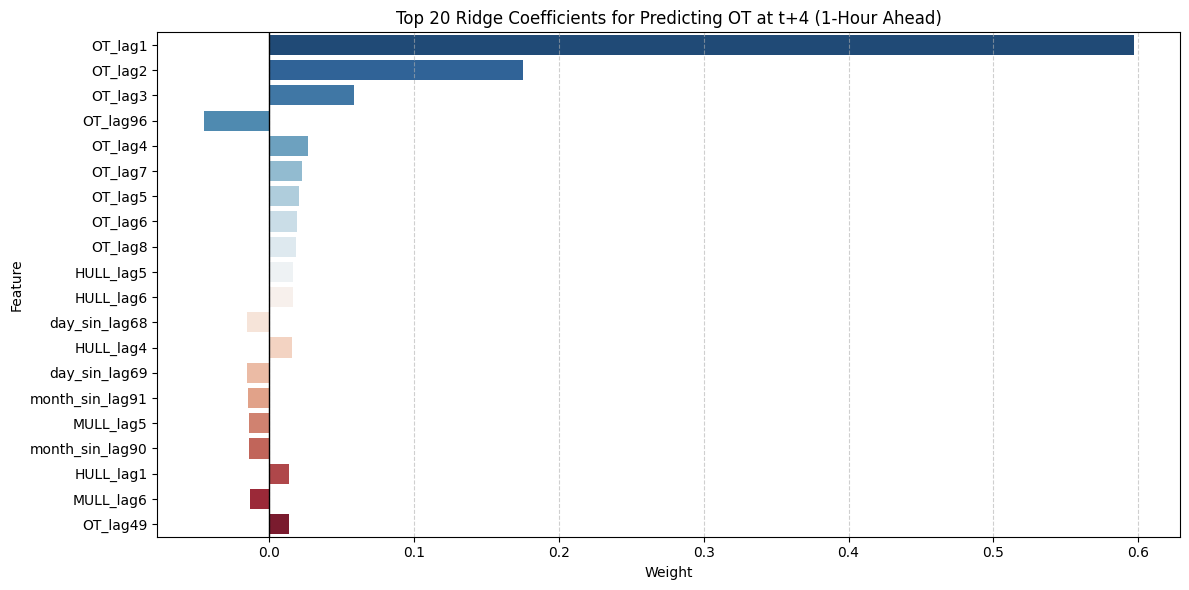

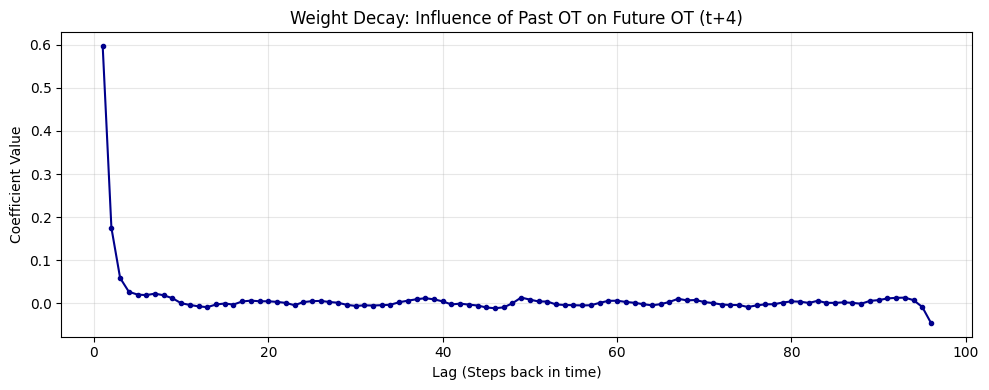

Most influential feature for OT at t+4: OT_lag1 (weight=0.5968)


In [13]:
# Ridge Coefficient-Based Local Interpretability Analysis

# Construct feature labels aligned with the flattened temporal-feature dimension
all_feature_names = base_cols + time_cols
feature_labels = []
for lag in range(CONFIG['seq_len'], 0, -1):
    for col in all_feature_names:
        feature_labels.append(f"{col}_lag{lag}")

# Isolate the specific coefficient vector for 'OT' at prediction horizon t+4
target_step = 4
ot_idx = target_cols.index('OT')
target_flattened_idx = (target_step - 1) * target_dim + ot_idx
weights = ridge_model.coef_[target_flattened_idx]

# Map and rank features by absolute magnitude to identify top predictors
importance_df = pd.DataFrame({'Feature': feature_labels, 'Weight': weights})
importance_df['AbsWeight'] = importance_df['Weight'].abs()
top_features = importance_df.sort_values('AbsWeight', ascending=False).head(20)

# Visualize global feature saliency via coefficient magnitudes
plt.figure(figsize=(12, 6))
sns.barplot(data=top_features, x='Weight', y='Feature', hue='Feature', palette='RdBu_r', dodge=False, legend=False)
plt.title(f'Top 20 Ridge Coefficients for Predicting OT at t+{target_step} (1-Hour Ahead)')
plt.axvline(0, color='black', lw=1)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(out_path('figures', 'ridge_feature_importance_top20.png'), dpi=150)
plt.show()

# Quantify temporal decay: analyze the influence of past OT lags on future predictions
ot_lags = [i for i, label in enumerate(feature_labels) if label.startswith('OT_lag')]
ot_weights = weights[ot_lags]

plt.figure(figsize=(10, 4))
plt.plot(range(len(ot_weights), 0, -1), ot_weights, marker='.', color='darkblue')
plt.title('Weight Decay: Influence of Past OT on Future OT (t+4)')
plt.xlabel('Lag (Steps back in time)')
plt.ylabel('Coefficient Value')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(out_path('figures', 'ridge_ot_weight_decay.png'), dpi=150)
plt.show()

# Extract and report the primary exogenous or endogenous driver
print(
    f"Most influential feature for OT at t+{target_step}: "
    f"{top_features.iloc[0]['Feature']} (weight={top_features.iloc[0]['Weight']:.4f})"
 )

In [14]:
print('\n=== KNN final training (M setting) ===')

# Initialize non-parametric K-Nearest Neighbors regressor with optimized hyperparameters
knn_cfg = BEST_CONFIG['M-96']['KNN']
knn_best = KNeighborsRegressor(
    n_neighbors=int(knn_cfg['n_neighbors']),
    weights=knn_cfg['weights'],
    leaf_size=int(knn_cfg['leaf_size']),
    n_jobs=-1
)

# Indexing training samples
t0 = time.perf_counter()
knn_best.fit(X_train_flat, y_train)
knn_train_time = time.perf_counter() - t0

# Execute inference and quantify performance in normalized feature space
knn_pred_scaled = knn_best.predict(X_test_flat)
knn_metrics_norm, knn_true_scaled, knn_pred_scaled = regression_metrics(y_test, knn_pred_scaled)

# Map predictions back to physical scale for real-world error analysis
knn_true_inv = inverse_scale_flat_targets(knn_true_scaled, y_scaler, target_dim)
knn_pred_inv = inverse_scale_flat_targets(knn_pred_scaled, y_scaler, target_dim)
knn_metrics_inv, _, _ = regression_metrics(knn_true_inv, knn_pred_inv)

# Compute variable-specific metrics and store disaggregated reports
knn_pv_norm = per_variable_metrics(knn_true_scaled, knn_pred_scaled, target_cols, pred_len, target_dim)
knn_pv_inv = per_variable_metrics(knn_true_inv, knn_pred_inv, target_cols, pred_len, target_dim)
per_variable_reports['KNN_M96'] = {'normalized': knn_pv_norm, 'inverse': knn_pv_inv}

# Profile instance-based inference latency (warmup + Monte Carlo trials)
knn_lat_mean, knn_lat_med, knn_lat_p95 = measure_ml_latency(
    knn_best, X_test_flat[:1], CONFIG['latency_warmup'], CONFIG['latency_runs']
)
latency_records['KNN_M96'] = {'mean_ms': knn_lat_mean, 'median_ms': knn_lat_med, 'p95_ms': knn_lat_p95}

print(f'KNN Train Time: {knn_train_time:.2f}s')
print('KNN metrics [normalized]:', knn_metrics_norm)
print('KNN metrics [inverse-scaled]:', knn_metrics_inv)
print('KNN per-variable metrics [normalized]:')
display(knn_pv_norm)
print('KNN per-variable metrics [inverse-scaled]:')
display(knn_pv_inv)

# Aggregate results with metadata for model comparative benchmarking
results.append({
    'Task': 'M-96',
    'Model': 'KNN',
    **knn_metrics_norm,
    'TrainTimeSec': knn_train_time,
    'LatencyMeanMs': knn_lat_mean,
    'LatencyP95Ms': knn_lat_p95,
    'Explainability': 'Low (Instance-based)'
})



=== KNN final training (M setting) ===
KNN Train Time: 0.04s
KNN metrics [normalized]: {'MAE': 0.653378963470459, 'MSE': 0.7606022953987122, 'RMSE': np.float64(0.8721251603976989)}
KNN metrics [inverse-scaled]: {'MAE': 2.516817808151245, 'MSE': 16.819347381591797, 'RMSE': np.float64(4.101139766161572)}
KNN per-variable metrics [normalized]:


,Variable,MAE,MSE,RMSE
0,LULL,0.423007,0.265808,0.515566
1,MUFL,0.649378,1.016156,1.008046
2,HULL,0.650720,0.683504,0.826743
3,MULL,0.651246,0.665621,0.815856
4,OT,0.684726,0.555250,0.745151
5,HUFL,0.687811,0.977228,0.988549
6,LUFL,0.826765,1.160649,1.077334


KNN per-variable metrics [inverse-scaled]:


,Variable,MAE,MSE,RMSE
0,LULL,0.267528,0.106319,0.326065
1,LUFL,0.860293,1.256696,1.121024
2,MULL,1.253101,2.464391,1.569838
3,HULL,1.359774,2.984599,1.727599
4,MUFL,3.583946,30.951944,5.563447
5,HUFL,4.012066,33.250168,5.766296
6,OT,6.281017,46.721313,6.835299


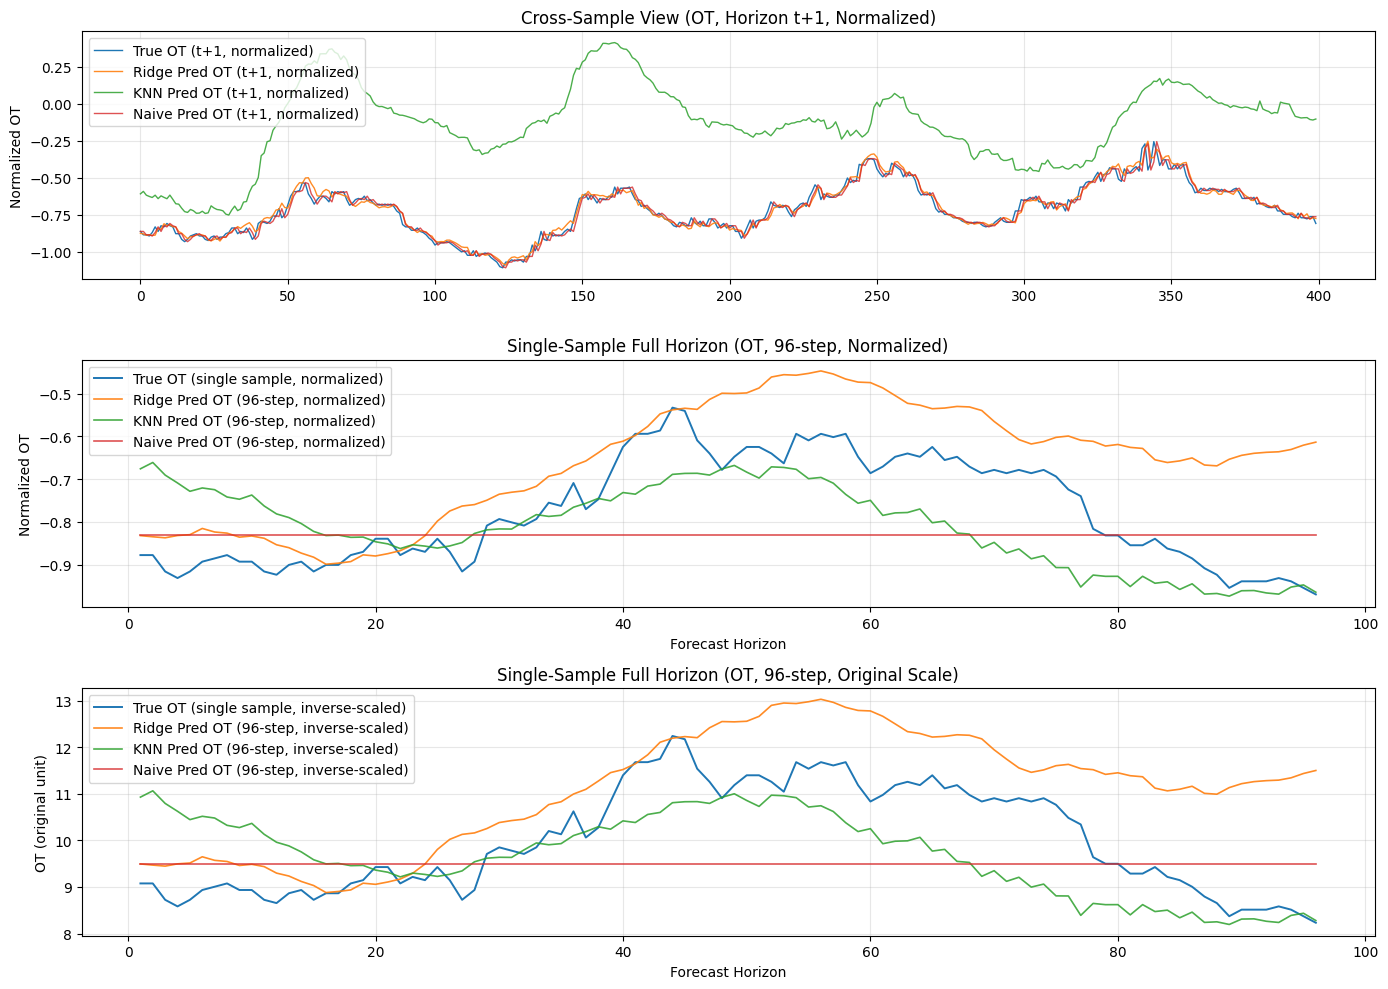

Visual sample index for 96-step plot: 12
Figure written: outputs/figures/ridge_visual_evidence_ot_h1_and_96step.png


In [15]:
# Visual Diagnostics: Multi-Model Baseline Comparison (OT Channel)
if 'ridge_pred_scaled' not in globals():
    print('Ridge outputs are unavailable. Execute the Ridge training cell first.')
else:
    n_show = min(400, len(ridge_true_scaled))
    ot_idx = target_cols.index('OT')
    ot_h1_col = 0 * target_dim + ot_idx  

    fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=False)

    # Cross-sample validation at t+1: Assessing global bias and variance across the test set
    axes[0].plot(ridge_true_scaled[:n_show, ot_h1_col], label='True OT (t+1, normalized)', linewidth=1.0)
    axes[0].plot(ridge_pred_scaled[:n_show, ot_h1_col], label='Ridge Pred OT (t+1, normalized)', linewidth=1.0, alpha=0.9)
    if 'knn_pred_scaled' in globals():
        axes[0].plot(knn_pred_scaled[:n_show, ot_h1_col], label='KNN Pred OT (t+1, normalized)', linewidth=1.0, alpha=0.85)
    axes[0].plot(naive_pred_scaled_norm[:n_show, ot_h1_col], label='Naive Pred OT (t+1, normalized)', linewidth=1.0, alpha=0.8)
    axes[0].set_title('Cross-Sample View (OT, Horizon t+1, Normalized)')
    axes[0].set_ylabel('Normalized OT')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Multi-step error trajectory (Normalized): Analyzing forecast decay over a 96-step horizon
    sample_idx = min(12, len(ridge_true_scaled) - 1)
    
    # Extract temporal sequences for a representative sample
    true_seq_norm = ridge_true_scaled[sample_idx].reshape(pred_len, target_dim)[:, ot_idx]
    ridge_seq_norm = ridge_pred_scaled[sample_idx].reshape(pred_len, target_dim)[:, ot_idx]
    if 'knn_pred_scaled' in globals():
        knn_seq_norm = knn_pred_scaled[sample_idx].reshape(pred_len, target_dim)[:, ot_idx]
    naive_seq_norm = naive_pred_scaled_norm[sample_idx].reshape(pred_len, target_dim)[:, ot_idx]
    h = np.arange(1, pred_len + 1)

    axes[1].plot(h, true_seq_norm, label='True OT (single sample, normalized)', linewidth=1.4)
    axes[1].plot(h, ridge_seq_norm, label='Ridge Pred OT (96-step, normalized)', linewidth=1.2, alpha=0.9)
    if 'knn_pred_scaled' in globals():
        axes[1].plot(h, knn_seq_norm, label='KNN Pred OT (96-step, normalized)', linewidth=1.2, alpha=0.85)
    axes[1].plot(h, naive_seq_norm, label='Naive Pred OT (96-step, normalized)', linewidth=1.2, alpha=0.8)
    axes[1].set_title('Single-Sample Full Horizon (OT, 96-step, Normalized)')
    axes[1].set_xlabel('Forecast Horizon')
    axes[1].set_ylabel('Normalized OT')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    # Physical scale validation: Benchmarking forecasting performance in original units
    true_seq_inv = ridge_true_inv[sample_idx].reshape(pred_len, target_dim)[:, ot_idx]
    ridge_seq_inv = ridge_pred_inv[sample_idx].reshape(pred_len, target_dim)[:, ot_idx]
    if 'knn_pred_inv' in globals():
        knn_seq_inv = knn_pred_inv[sample_idx].reshape(pred_len, target_dim)[:, ot_idx]
    naive_seq_inv = naive_pred_inv[sample_idx].reshape(pred_len, target_dim)[:, ot_idx]

    axes[2].plot(h, true_seq_inv, label='True OT (single sample, inverse-scaled)', linewidth=1.4)
    axes[2].plot(h, ridge_seq_inv, label='Ridge Pred OT (96-step, inverse-scaled)', linewidth=1.2, alpha=0.9)
    if 'knn_pred_inv' in globals():
        axes[2].plot(h, knn_seq_inv, label='KNN Pred OT (96-step, inverse-scaled)', linewidth=1.2, alpha=0.85)
    axes[2].plot(h, naive_seq_inv, label='Naive Pred OT (96-step, inverse-scaled)', linewidth=1.2, alpha=0.8)
    axes[2].set_title('Single-Sample Full Horizon (OT, 96-step, Original Scale)')
    axes[2].set_xlabel('Forecast Horizon')
    axes[2].set_ylabel('OT (original unit)')
    axes[2].legend()
    axes[2].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(out_path('figures', 'ridge_visual_evidence_ot_h1_and_96step.png'), dpi=150)
    plt.show()

    print(f'Visual sample index for 96-step plot: {sample_idx}')
    print('Figure written: outputs/figures/ridge_visual_evidence_ot_h1_and_96step.png')

# 5. Deep Learning Models

This section defines and trains the deep learning candidates used in this notebook, including LSTM, GRU, Informer, DLinear, TCN, MLP, and iTransformer.
It also standardizes DL data loading, optimization, and evaluation logic for fair M-96 comparison.

In [16]:
# Scalar regression performance metrics for point-wise evaluation.

if 'mean_absolute_error' not in globals():
    from sklearn.metrics import mean_absolute_error, mean_squared_error
if 'regression_metrics' not in globals():
    def regression_metrics(y_true_scaled, y_pred_scaled):
        """Computes scalar regression metrics for a flattened target tensor."""
        y_true = np.asarray(y_true_scaled, dtype=np.float32)
        y_pred = np.asarray(y_pred_scaled, dtype=np.float32)
        mae = mean_absolute_error(y_true.reshape(-1), y_pred.reshape(-1))
        mse = mean_squared_error(y_true.reshape(-1), y_pred.reshape(-1))
        rmse = np.sqrt(mse)
        return {'MAE': mae, 'MSE': mse, 'RMSE': rmse}, y_true, y_pred
if 'inverse_scale_flat_targets' not in globals():
    def inverse_scale_flat_targets(y_flat_scaled, scaler, target_dim):
        """Applies inverse scaling to a flattened target array using the provided scaler."""
        y_flat_scaled = np.asarray(y_flat_scaled, dtype=np.float32)
        n = y_flat_scaled.shape[0]
        y_2d = y_flat_scaled.reshape(-1, target_dim)
        y_inv_2d = scaler.inverse_transform(y_2d)
        return y_inv_2d.reshape(n, -1).astype(np.float32)
if 'per_variable_metrics' not in globals():
    def per_variable_metrics(y_true_flat, y_pred_flat, var_names, pred_len, target_dim):
        """Computes per-variable regression metrics by reshaping flattened targets."""
        y_true_3d = np.asarray(y_true_flat, dtype=np.float32).reshape(-1, pred_len, target_dim)
        y_pred_3d = np.asarray(y_pred_flat, dtype=np.float32).reshape(-1, pred_len, target_dim)
        rows = []
        for i, var in enumerate(var_names):
            yt = y_true_3d[:, :, i].reshape(-1)
            yp = y_pred_3d[:, :, i].reshape(-1)
            mae = mean_absolute_error(yt, yp)
            mse = mean_squared_error(yt, yp)
            rmse = np.sqrt(mse)
            rows.append({'Variable': var, 'MAE': mae, 'MSE': mse, 'RMSE': rmse})
        return pd.DataFrame(rows).sort_values('MAE').reset_index(drop=True)

def build_loaders(X_tr, y_tr, X_va, y_va, X_te, y_te, batch_size, run_device):
    """Constructs PyTorch DataLoaders for training, validation, and testing."""
    train_ds = TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(y_tr))
    val_ds = TensorDataset(torch.from_numpy(X_va), torch.from_numpy(y_va))
    test_ds = TensorDataset(torch.from_numpy(X_te), torch.from_numpy(y_te))

    use_workers = CONFIG['dl_num_workers'] if CONFIG['dl_num_workers'] > 0 else 0
    use_pin = bool(CONFIG['dl_pin_memory']) and (run_device.type == 'cuda')
    common = dict(batch_size=batch_size, num_workers=use_workers, pin_memory=use_pin)
    if use_workers > 0:
        common['persistent_workers'] = True

    train_loader = DataLoader(train_ds, shuffle=True, **common)
    val_loader = DataLoader(val_ds, shuffle=False, **common)
    test_loader = DataLoader(test_ds, shuffle=False, **common)
    return train_loader, val_loader, test_loader


class SequenceRegressor(nn.Module):
    """LSTM or GRU baseline with optional input and head dropout."""
    def __init__(self, input_dim, output_dim, hidden_dim=128, num_layers=2, dropout=0.2, input_dropout=0.0, head_dropout=0.0, rnn_type='lstm'):
        super().__init__()
        rnn_cls = nn.LSTM if rnn_type.lower() == 'lstm' else nn.GRU
        self.input_drop = nn.Dropout(float(input_dropout))
        self.rnn = rnn_cls(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.norm = nn.LayerNorm(hidden_dim)
        self.head_drop = nn.Dropout(float(head_dropout))
        self.head = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        out, _ = self.rnn(self.input_drop(x))
        last = self.norm(out[:, -1, :])
        last = self.head_drop(last)
        return self.head(last)


class PositionalEncoding(nn.Module):
    """Positional encoding for transformer models."""
    def __init__(self, d_model, max_len=2048):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]


class InformerRegressor(nn.Module):
    """Informer regressor with optional pooling of last K time steps."""
    def __init__(self, input_dim, output_dim, d_model=128, nhead=8, num_layers=2, dropout=0.1, ff_dim=256, pool_last_k=24):
        super().__init__()
        self.input_proj = nn.Linear(input_dim, d_model)
        self.pos_encoder = PositionalEncoding(d_model)
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=ff_dim, dropout=dropout, batch_first=True
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=num_layers)
        self.pool_last_k = pool_last_k
        self.head = nn.Linear(d_model, output_dim)

    def forward(self, x):
        z = self.input_proj(x)
        z = self.pos_encoder(z)
        z = self.encoder(z)
        k = min(self.pool_last_k, z.size(1))
        return self.head(z[:, -k:, :].mean(dim=1))


class DLinearRegressor(nn.Module):
    """DLinear regressor with moving average seasonal decomposition."""
    def __init__(self, seq_len, pred_len, target_dim, ma_window=25):
        super().__init__()
        self.seq_len = seq_len
        self.pred_len = pred_len
        self.target_dim = target_dim
        self.avg = nn.AvgPool1d(kernel_size=ma_window, stride=1, padding=ma_window // 2)
        self.seasonal_linear = nn.Linear(seq_len, pred_len)
        self.trend_linear = nn.Linear(seq_len, pred_len)

    def forward(self, x):
        x_t = x[:, :, :self.target_dim]
        trend = self.avg(x_t.transpose(1, 2))[:, :, :x_t.size(1)].transpose(1, 2)
        seasonal = x_t - trend
        seasonal_out = self.seasonal_linear(seasonal.transpose(1, 2))
        trend_out = self.trend_linear(trend.transpose(1, 2))
        out = (seasonal_out + trend_out).transpose(1, 2)
        return out.reshape(out.size(0), -1)


class TemporalBlock(nn.Module):
    """Temporal convolution block for TCN."""
    def __init__(self, in_ch, out_ch, kernel_size=3, dilation=1, dropout=0.1):
        super().__init__()
        pad = (kernel_size - 1) * dilation
        self.conv1 = nn.Conv1d(in_ch, out_ch, kernel_size, padding=pad, dilation=dilation)
        self.conv2 = nn.Conv1d(out_ch, out_ch, kernel_size, padding=pad, dilation=dilation)
        self.act = nn.GELU()
        self.drop = nn.Dropout(dropout)
        self.proj = nn.Conv1d(in_ch, out_ch, kernel_size=1) if in_ch != out_ch else None

    def _trim(self, x, ref_len):
        return x[:, :, :ref_len]

    def forward(self, x):
        ref_len = x.size(-1)
        z = self._trim(self.conv1(x), ref_len)
        z = self.drop(self.act(z))
        z = self._trim(self.conv2(z), ref_len)
        z = self.drop(self.act(z))
        res = x if self.proj is None else self.proj(x)
        return z + res


class TCNRegressor(nn.Module):
    """TCN regressor with residual connections and dilated convolutions."""
    def __init__(self, input_dim, output_dim, channels=128, levels=4, kernel_size=3, dropout=0.1):
        super().__init__()
        blocks = []
        in_ch = input_dim
        for i in range(levels):
            blocks.append(TemporalBlock(in_ch, channels, kernel_size=kernel_size, dilation=2 ** i, dropout=dropout))
            in_ch = channels
        self.backbone = nn.Sequential(*blocks)
        self.head = nn.Linear(channels, output_dim)

    def forward(self, x):
        z = self.backbone(x.transpose(1, 2))
        return self.head(z[:, :, -1])


class MLPRegressor(nn.Module):
    """MLP regressor with GELU activations and dropout."""
    def __init__(self, input_dim, seq_len, output_dim, hidden=384, layers=3, dropout=0.1):
        super().__init__()
        in_dim = input_dim * seq_len
        blocks = []
        for _ in range(layers):
            blocks.extend([nn.Linear(in_dim, hidden), nn.GELU(), nn.Dropout(dropout)])
            in_dim = hidden
        blocks.append(nn.Linear(in_dim, output_dim))
        self.net = nn.Sequential(*blocks)

    def forward(self, x):
        return self.net(x.reshape(x.size(0), -1))


class iTransformerRegressor(nn.Module):
    """iTransformer regressor with tokenized input and global averaging."""
    def __init__(self, input_dim, seq_len, output_dim, d_model=128, nhead=8, num_layers=2, ff_dim=256, dropout=0.1):
        super().__init__()
        self.token_proj = nn.Linear(seq_len, d_model)
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=ff_dim, dropout=dropout, batch_first=True
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=num_layers)
        self.head = nn.Linear(d_model, output_dim)

    def forward(self, x):
        tokens = x.transpose(1, 2)
        z = self.token_proj(tokens)
        z = self.encoder(z)
        return self.head(z.mean(dim=1))


def build_dl_model(model_name, params, input_dim, output_dim, seq_len, pred_len, target_dim):
    """Factory function to build a specified deep learning model instance."""
    n = model_name.lower()
    if n == 'lstm':
        return SequenceRegressor(
            input_dim=input_dim, output_dim=output_dim, hidden_dim=int(params['hidden']),
            num_layers=int(params['layers']), dropout=float(params['dropout']),
            input_dropout=float(params.get('input_dropout', CONFIG.get('lstm_gru_input_dropout', 0.0))),
            head_dropout=float(params.get('head_dropout', CONFIG.get('lstm_gru_head_dropout', 0.0))),
            rnn_type='lstm'
        )
    if n == 'gru':
        return SequenceRegressor(
            input_dim=input_dim, output_dim=output_dim, hidden_dim=int(params['hidden']),
            num_layers=int(params['layers']), dropout=float(params['dropout']),
            input_dropout=float(params.get('input_dropout', CONFIG.get('lstm_gru_input_dropout', 0.0))),
            head_dropout=float(params.get('head_dropout', CONFIG.get('lstm_gru_head_dropout', 0.0))),
            rnn_type='gru'
        )
    if n == 'informer':
        return InformerRegressor(
            input_dim=input_dim, output_dim=output_dim, d_model=int(params['d_model']), nhead=int(params['nhead']),
            num_layers=int(params['layers']), dropout=float(params['dropout']), ff_dim=int(params['ffn']),
            pool_last_k=int(params['pool_last_k'])
        )
    if n == 'dlinear':
        return DLinearRegressor(
            seq_len=seq_len, pred_len=pred_len, target_dim=target_dim, ma_window=int(params['ma_window'])
        )
    if n == 'tcn':
        return TCNRegressor(
            input_dim=input_dim, output_dim=output_dim, channels=int(params['channels']),
            levels=int(params['levels']), kernel_size=int(params['kernel_size']), dropout=float(params['dropout'])
        )
    if n == 'mlp':
        return MLPRegressor(
            input_dim=input_dim, seq_len=seq_len, output_dim=output_dim, hidden=int(params['hidden']),
            layers=int(params['layers']), dropout=float(params['dropout'])
        )
    if n == 'itransformer':
        return iTransformerRegressor(
            input_dim=input_dim, seq_len=seq_len, output_dim=output_dim, d_model=int(params['d_model']),
            nhead=int(params['nhead']), num_layers=int(params['layers']), ff_dim=int(params['ffn']),
            dropout=float(params['dropout'])
        )
    raise ValueError(f'Unsupported model: {model_name}')


def get_default_dl_params(model_name):
    """Returns default hyperparameters for a given model name."""
    n = model_name.lower()
    if n == 'lstm':
        return {'hidden': CONFIG['lstm_hidden'], 'layers': CONFIG['lstm_layers'], 'dropout': CONFIG['dropout'], 'input_dropout': CONFIG.get('lstm_gru_input_dropout', 0.0), 'head_dropout': CONFIG.get('lstm_gru_head_dropout', 0.0), 'lr': CONFIG['learning_rate'], 'epochs': CONFIG['epochs'], 'patience': CONFIG['patience']}
    if n == 'gru':
        return {'hidden': CONFIG['gru_hidden'], 'layers': CONFIG['gru_layers'], 'dropout': CONFIG['dropout'], 'input_dropout': CONFIG.get('lstm_gru_input_dropout', 0.0), 'head_dropout': CONFIG.get('lstm_gru_head_dropout', 0.0), 'lr': CONFIG['learning_rate'], 'epochs': CONFIG['epochs'], 'patience': CONFIG['patience']}
    if n == 'informer':
        return {'d_model': CONFIG['informer_d_model'], 'nhead': CONFIG['informer_nhead'], 'layers': CONFIG['informer_layers'], 'ffn': CONFIG['informer_ffn'], 'dropout': CONFIG['informer_dropout'], 'pool_last_k': CONFIG['informer_pool_last_k'], 'lr': CONFIG['learning_rate'], 'epochs': CONFIG['epochs'], 'patience': CONFIG['patience']}
    if n == 'dlinear':
        return {'ma_window': CONFIG['dlinear_ma_window'], 'lr': CONFIG['learning_rate'], 'epochs': CONFIG['epochs'], 'patience': CONFIG['patience']}
    if n == 'tcn':
        return {'channels': CONFIG['tcn_channels'], 'levels': CONFIG['tcn_levels'], 'kernel_size': CONFIG['tcn_kernel_size'], 'dropout': CONFIG['dropout'], 'lr': CONFIG['learning_rate'], 'epochs': CONFIG['epochs'], 'patience': CONFIG['patience']}
    if n == 'mlp':
        return {'hidden': CONFIG['mlp_hidden'], 'layers': CONFIG['mlp_layers'], 'dropout': CONFIG['dropout'], 'lr': CONFIG['learning_rate'], 'epochs': CONFIG['epochs'], 'patience': CONFIG['patience']}
    if n == 'itransformer':
        return {'d_model': CONFIG['itransformer_d_model'], 'nhead': CONFIG['itransformer_nhead'], 'layers': CONFIG['itransformer_layers'], 'ffn': CONFIG['itransformer_ffn'], 'dropout': CONFIG['itransformer_dropout'], 'lr': CONFIG['learning_rate'], 'epochs': CONFIG['epochs'], 'patience': CONFIG['patience']}
    raise ValueError(f'Unsupported model: {model_name}')


def evaluate_loader(model, loader, criterion, run_device):
    """Evaluates a model on a data loader."""
    model.eval()
    losses, preds, trues = [], [], []
    amp_enabled = CONFIG['use_amp'] and (run_device.type == 'cuda')
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(run_device, non_blocking=True)
            yb = yb.to(run_device, non_blocking=True)
            with torch.amp.autocast('cuda', enabled=amp_enabled):
                yhat = model(xb)
                loss = criterion(yhat, yb)
            losses.append(float(loss.item()))
            preds.append(yhat.detach().cpu().numpy())
            trues.append(yb.detach().cpu().numpy())
    return float(np.mean(losses)), np.concatenate(preds, axis=0), np.concatenate(trues, axis=0)


def train_with_early_stopping(model, train_loader_local, val_loader_local, model_name, epochs, patience, lr, run_device, max_train_seconds=None):
    """Trains a model with early stopping based on validation loss, using mixed precision if enabled."""
    criterion = nn.SmoothL1Loss(beta=0.5)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=CONFIG['weight_decay'])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.6, patience=2, min_lr=1e-5)
    amp_enabled = CONFIG['use_amp'] and (run_device.type == 'cuda')
    scaler = torch.amp.GradScaler('cuda', enabled=amp_enabled)

    best_val = float('inf')
    best_state = None
    patience_counter = 0
    train_losses, val_losses = [], []
    cap_seconds = CONFIG['max_train_seconds_per_model'] if max_train_seconds is None else max_train_seconds

    t0 = time.perf_counter()
    for epoch in range(int(epochs)):
        if (time.perf_counter() - t0) > cap_seconds:
            print(f'{model_name}: runtime guard triggered at epoch {epoch + 1}')
            break

        model.train()
        epoch_losses = []
        for xb, yb in train_loader_local:
            xb = xb.to(run_device, non_blocking=True)
            yb = yb.to(run_device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda', enabled=amp_enabled):
                pred = model(xb)
                loss = criterion(pred, yb)
            if not torch.isfinite(loss):
                print(f'{model_name}: non-finite loss, training stopped')
                break
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=CONFIG['grad_clip_max_norm'])
            scaler.step(optimizer)
            scaler.update()
            epoch_losses.append(float(loss.item()))

        if len(epoch_losses) == 0:
            break

        train_loss = float(np.mean(epoch_losses))
        val_loss, _, _ = evaluate_loader(model, val_loader_local, criterion, run_device)
        scheduler.step(val_loss)
        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if val_loss < best_val:
            best_val = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f'{model_name} epoch {epoch + 1:02d}: train={train_loss:.5f}, val={val_loss:.5f}')
        if patience_counter >= int(patience):
            print(f'{model_name}: early stopping at epoch {epoch + 1}')
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    train_time = time.perf_counter() - t0
    return model, train_losses, val_losses, train_time


def measure_dl_latency(model, x_single, run_device, warmup=30, runs=200):
    """Measures the average, median, and 95th percentile latency of a model inference."""
    model.eval()
    with torch.no_grad():
        for _ in range(warmup):
            _ = model(x_single)
        times = []
        for _ in range(runs):
            if run_device.type == 'cuda':
                torch.cuda.synchronize()
            t1 = time.perf_counter()
            _ = model(x_single)
            if run_device.type == 'cuda':
                torch.cuda.synchronize()
            t2 = time.perf_counter()
            times.append((t2 - t1) * 1000.0)
    return float(np.mean(times)), float(np.median(times)), float(np.percentile(times, 95))


def train_with_device_fallback(model_name, params, X_tr, y_tr, X_va, y_va, X_te, y_te, input_dim, output_dim, seq_len, pred_len, target_dim, max_train_seconds=None):
    """Trains a model with a fallback mechanism, and returns the trained model along with training history and test loader."""
    run_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    for try_idx in [0, 1]:
        try:
            train_loader_local, val_loader_local, test_loader_local = build_loaders(
                X_tr, y_tr, X_va, y_va, X_te, y_te, CONFIG['batch_size'], run_device
            )
            model = build_dl_model(model_name, params, input_dim, output_dim, seq_len, pred_len, target_dim).to(run_device)
            model, tr_losses, va_losses, train_time = train_with_early_stopping(
                model=model,
                train_loader_local=train_loader_local,
                val_loader_local=val_loader_local,
                model_name=model_name,
                epochs=params.get('epochs', CONFIG['epochs']),
                patience=params.get('patience', CONFIG['patience']),
                lr=params.get('lr', CONFIG['learning_rate']),
                run_device=run_device,
                max_train_seconds=max_train_seconds
            )
            return model, tr_losses, va_losses, train_time, test_loader_local, run_device
        except RuntimeError as e:
            is_cuda_error = (run_device.type == 'cuda') and ('cuda' in str(e).lower() or 'cudnn' in str(e).lower())
            if (try_idx == 0) and is_cuda_error:
                print(f'{model_name}: CUDA execution failed; fallback to CPU')
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
                run_device = torch.device('cpu')
                continue
            raise

In [17]:
# Minimal corrective overrides for Informer/iTransformer and DL training policy.

class DropPath(nn.Module):
    """DropPath class used in Informer and iTransformer."""
    def __init__(self, drop_prob=0.0):
        super().__init__()
        self.drop_prob = float(drop_prob)

    def forward(self, x):
        if self.drop_prob <= 0.0 or (not self.training):
            return x
        keep_prob = 1.0 - self.drop_prob
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        random_tensor = keep_prob + torch.rand(shape, dtype=x.dtype, device=x.device)
        random_tensor = random_tensor.floor()
        return x * random_tensor / keep_prob


class InformerRegressor(nn.Module):
    """Informer regressor with RevIN and optional DropPath support."""
    def __init__(self, input_dim, seq_len, pred_len, target_dim, d_model=128, nhead=8, num_layers=2, ff_dim=256, dropout=0.1, droppath=0.0):
        super().__init__()
        self.target_dim = int(target_dim)
        self.value_proj = nn.Linear(input_dim, d_model)
        self.pos_emb = nn.Parameter(torch.randn(1, seq_len, d_model) * 0.02)
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=ff_dim, dropout=dropout, batch_first=True
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=num_layers)
        self.droppath = DropPath(droppath)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(d_model, pred_len * self.target_dim)

    def forward(self, x):
        z = self.value_proj(x) + self.pos_emb[:, :x.size(1), :]
        z = self.encoder(z)
        z = self.droppath(z)
        z = self.dropout(z[:, -1, :])
        return self.head(z)


class iTransformerRegressor(nn.Module):
    """iTransformer regressor with RevIN and optional DropPath support."""
    def __init__(self, input_dim, seq_len, pred_len, target_dim, d_model=128, nhead=8, num_layers=2, ff_dim=256, dropout=0.1, droppath=0.0):
        super().__init__()
        self.target_dim = int(target_dim)
        self.pred_len = int(pred_len)
        self.token_proj = nn.Linear(seq_len, d_model)
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=ff_dim, dropout=dropout, batch_first=True
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=num_layers)
        self.droppath = DropPath(droppath)
        self.head = nn.Linear(d_model, pred_len)

    def forward(self, x):
        tokens = x.transpose(1, 2)
        z = self.encoder(self.token_proj(tokens))
        z = self.droppath(z)
        z_target = z[:, :self.target_dim, :]
        pred = self.head(z_target)
        pred = pred.transpose(1, 2).contiguous()
        return pred.reshape(pred.size(0), -1)


class RevINWrapper(nn.Module):
    """Reversible Instance Normalization wrapper for all models."""
    def __init__(self, base_model, target_dim, pred_len, eps=1e-5):
        super().__init__()
        self.base_model = base_model
        self.target_dim = int(target_dim)
        self.pred_len = int(pred_len)
        self.eps = float(eps)

    def forward(self, x):
        x_t = x[:, :, :self.target_dim]
        mean = x_t.mean(dim=1, keepdim=True)
        std = x_t.std(dim=1, keepdim=True, unbiased=False).clamp_min(self.eps)
        x_norm = x.clone()
        x_norm[:, :, :self.target_dim] = (x_t - mean) / std

        pred_norm = self.base_model(x_norm)
        b = pred_norm.size(0)
        pred_3d = pred_norm.reshape(b, self.pred_len, self.target_dim)
        pred = pred_3d * std + mean
        return pred.reshape(b, -1)


def _resolve_base_fn(current_fn, storage_key):
    """Resolves the base function for overrides, preventing infinite recursion."""
    cached = globals().get(storage_key)
    if callable(cached) and not getattr(cached, '_is_dl_override', False):
        return cached
    if callable(current_fn) and not getattr(current_fn, '_is_dl_override', False):
        globals()[storage_key] = current_fn
        return current_fn
    if callable(cached):
        return cached
    raise RuntimeError(f'Missing base function for {storage_key}. Run previous DL definition cells first.')


_BASE_BUILD_DL_MODEL = _resolve_base_fn(globals().get('build_dl_model'), '_BASE_BUILD_DL_MODEL')


def build_dl_model(model_name, params, input_dim, output_dim, seq_len, pred_len, target_dim):
    """Builds a deep learning model with optional RevIN wrapper."""
    n = model_name.lower()
    if n == 'informer':
        model = InformerRegressor(
            input_dim=input_dim,
            seq_len=seq_len,
            pred_len=pred_len,
            target_dim=target_dim,
            d_model=int(params['d_model']),
            nhead=int(params['nhead']),
            num_layers=int(params['layers']),
            ff_dim=int(params['ffn']),
            dropout=float(params['dropout']),
            droppath=float(params.get('droppath', CONFIG.get('informer_droppath', 0.0)))
        )
    elif n == 'itransformer':
        model = iTransformerRegressor(
            input_dim=input_dim,
            seq_len=seq_len,
            pred_len=pred_len,
            target_dim=target_dim,
            d_model=int(params['d_model']),
            nhead=int(params['nhead']),
            num_layers=int(params['layers']),
            ff_dim=int(params['ffn']),
            dropout=float(params['dropout']),
            droppath=float(params.get('droppath', CONFIG.get('itransformer_droppath', 0.0)))
        )
    else:
        model = _BASE_BUILD_DL_MODEL(model_name, params, input_dim, output_dim, seq_len, pred_len, target_dim)

    if bool(CONFIG.get('dl_use_revin_all_models', True)):
        model = RevINWrapper(model, target_dim=target_dim, pred_len=pred_len)
    return model


build_dl_model._is_dl_override = True


_BASE_GET_DEFAULT_DL_PARAMS = _resolve_base_fn(globals().get('get_default_dl_params'), '_BASE_GET_DEFAULT_DL_PARAMS')


def get_default_dl_params(model_name):
    """Returns default hyperparameters for a given model name, including Informer/iTransformer overrides."""
    n = model_name.lower()
    if n == 'informer':
        return {
            'd_model': CONFIG['informer_d_model'],
            'nhead': CONFIG['informer_nhead'],
            'layers': CONFIG['informer_layers'],
            'ffn': CONFIG['informer_ffn'],
            'dropout': CONFIG['informer_dropout'],
            'pool_last_k': CONFIG['informer_pool_last_k'],
            'droppath': float(CONFIG.get('informer_droppath', 0.0)),
            'lr': CONFIG['learning_rate'],
            'epochs': CONFIG['epochs'],
            'patience': CONFIG['patience']
        }
    if n == 'itransformer':
        return {
            'd_model': CONFIG['itransformer_d_model'],
            'nhead': CONFIG['itransformer_nhead'],
            'layers': CONFIG['itransformer_layers'],
            'ffn': CONFIG['itransformer_ffn'],
            'dropout': CONFIG['itransformer_dropout'],
            'droppath': float(CONFIG.get('itransformer_droppath', 0.0)),
            'lr': CONFIG['learning_rate'],
            'epochs': CONFIG['epochs'],
            'patience': CONFIG['patience']
        }
    return _BASE_GET_DEFAULT_DL_PARAMS(model_name)


get_default_dl_params._is_dl_override = True


def train_with_early_stopping(model, train_loader_local, val_loader_local, model_name, epochs, patience, lr, run_device, max_train_seconds=None, trial=None):
    """Trains a model with early stopping based on validation loss, using mixed precision if enabled, and supports Optuna pruning."""
    criterion = nn.SmoothL1Loss(beta=0.5)
    eval_criterion = criterion
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=CONFIG['weight_decay'])

    scheduler_mode = str(CONFIG.get('dl_scheduler_mode', 'plateau')).lower()
    if scheduler_mode == 'cosine':
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=max(1, int(epochs)),
            eta_min=float(CONFIG.get('dl_cosine_min_lr', 1e-5))
        )
    else:
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode='min',
            factor=float(CONFIG.get('dl_plateau_factor', 0.6)),
            patience=int(CONFIG.get('dl_plateau_patience', 2)),
            min_lr=float(CONFIG.get('dl_min_lr', 1e-5))
        )

    amp_enabled = bool(CONFIG['use_amp']) and (run_device.type == 'cuda')
    scaler = torch.amp.GradScaler('cuda', enabled=amp_enabled)

    best_val = float('inf')
    best_state = None
    patience_counter = 0
    train_losses, val_losses = [], []
    cap_seconds = CONFIG['max_train_seconds_per_model'] if max_train_seconds is None else max_train_seconds
    min_delta = float(CONFIG.get('dl_earlystop_min_delta', 0.0))

    t0 = time.perf_counter()
    for epoch in range(int(epochs)):
        if (time.perf_counter() - t0) > cap_seconds:
            print(f'{model_name}: runtime guard triggered at epoch {epoch + 1}')
            break

        model.train()
        epoch_losses = []
        for xb, yb in train_loader_local:
            xb = xb.to(run_device, non_blocking=True)
            yb = yb.to(run_device, non_blocking=True)

            noise_std = float(CONFIG.get('dl_input_noise_std', 0.0))
            if noise_std > 0.0:
                xb = xb + torch.randn_like(xb) * noise_std

            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda', enabled=amp_enabled):
                pred = model(xb)
                loss = criterion(pred, yb)

            if not torch.isfinite(loss):
                print(f'{model_name}: non-finite loss, training stopped')
                break

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=CONFIG['grad_clip_max_norm'])
            scaler.step(optimizer)
            scaler.update()
            epoch_losses.append(float(loss.item()))

        if len(epoch_losses) == 0:
            break

        train_loss = float(np.mean(epoch_losses))
        val_loss, _, _ = evaluate_loader(model, val_loader_local, eval_criterion, run_device)

        if scheduler_mode == 'cosine':
            scheduler.step()
        else:
            scheduler.step(val_loss)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if val_loss < (best_val - min_delta):
            best_val = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f'{model_name} epoch {epoch + 1:02d}: train={train_loss:.5f}, val={val_loss:.5f}')

        if trial is not None:
            trial.report(val_loss, step=epoch)
            if trial.should_prune():
                raise optuna.TrialPruned(f'{model_name} pruned at epoch {epoch + 1}')

        if patience_counter >= int(patience):
            print(f'{model_name}: early stopping at epoch {epoch + 1}')
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    train_time = time.perf_counter() - t0
    return model, train_losses, val_losses, train_time


train_with_early_stopping._is_dl_override = True


def train_with_device_fallback(model_name, params, X_tr, y_tr, X_va, y_va, X_te, y_te, input_dim, output_dim, seq_len, pred_len, target_dim, max_train_seconds=None, trial=None):
    """Trains a model with a fallback mechanism for device selection, and returns the trained model along with training history and test loader. Supports Optuna pruning."""
    run_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    for try_idx in [0, 1]:
        try:
            train_loader_local, val_loader_local, test_loader_local = build_loaders(
                X_tr, y_tr, X_va, y_va, X_te, y_te, CONFIG['batch_size'], run_device
            )
            model = build_dl_model(model_name, params, input_dim, output_dim, seq_len, pred_len, target_dim).to(run_device)
            model, tr_losses, va_losses, train_time = train_with_early_stopping(
                model=model,
                train_loader_local=train_loader_local,
                val_loader_local=val_loader_local,
                model_name=model_name,
                epochs=params.get('epochs', CONFIG['epochs']),
                patience=params.get('patience', CONFIG['patience']),
                lr=params.get('lr', CONFIG['learning_rate']),
                run_device=run_device,
                max_train_seconds=max_train_seconds,
                trial=trial
            )
            return model, tr_losses, va_losses, train_time, test_loader_local, run_device
        except RuntimeError as e:
            is_cuda_error = (run_device.type == 'cuda') and ('cuda' in str(e).lower() or 'cudnn' in str(e).lower())
            if (try_idx == 0) and is_cuda_error:
                print(f'{model_name}: CUDA execution failed; fallback to CPU')
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
                run_device = torch.device('cpu')
                continue
            raise


train_with_device_fallback._is_dl_override = True

In [18]:
# Official model loader and build_dl_model override from THUML Time-Series-Library, with error handling and status tracking.

from pathlib import Path
from types import SimpleNamespace
import importlib
import subprocess
import sys

if 'DL_PIPELINE_STATUS' not in globals():
    DL_PIPELINE_STATUS = {}

if 'DL_PIPELINE_ISSUES' not in globals():
    DL_PIPELINE_ISSUES = []


def _set_stage(stage, ok, message, **extra):
    """Sets the status of a pipeline stage."""
    rec = {'ok': bool(ok), 'message': str(message)}
    rec.update(extra)
    DL_PIPELINE_STATUS[stage] = rec
    tag = 'OK' if ok else 'FAIL'
    print(f'[DL-STAGE][{tag}] {stage}: {message}')


def _warn(msg):
    """Issues a warning message."""
    print(f'[DL-WARN] {msg}')


def _ensure_thuml_tsl_repo():
    """Ensures the THUML Time-Series-Library repository is available."""
    repo_dir = Path('outputs') / '_thuml_tsl'
    repo_root = repo_dir / 'Time-Series-Library'
    repo_dir.mkdir(parents=True, exist_ok=True)

    if repo_root.exists():
        return repo_root

    print('Cloning THUML Time-Series-Library ...')
    try:
        subprocess.run(
            ['git', 'clone', 'https://github.com/thuml/Time-Series-Library.git', str(repo_root)],
            check=True,
            stdout=subprocess.PIPE,
            stderr=subprocess.PIPE,
            text=True
        )
        return repo_root
    except Exception as e:
        _warn(f'THUML repo clone failed: {e}. Official models will fallback to local.')
        return None


THUML_REPO_ROOT = _ensure_thuml_tsl_repo()
THUML_MODEL_MODULES = {
    'informer': 'Informer',
    'itransformer': 'iTransformer',
    'dlinear': 'DLinear'
}
THUML_MODEL_STATUS = {}
THUML_IMPORT_ERRORS = {}
THUMLInformer = None
THUMLiTransformer = None
THUMLDLinear = None
OFFICIAL_MODEL_ERRORS = {}

if THUML_REPO_ROOT is not None:
    if str(THUML_REPO_ROOT) not in sys.path:
        sys.path.insert(0, str(THUML_REPO_ROOT))

    for model_key, module_name in THUML_MODEL_MODULES.items():
        try:
            module = importlib.import_module(f'models.{module_name}')
            THUML_MODEL_STATUS[model_key] = True
            if model_key == 'informer':
                THUMLInformer = module
            elif model_key == 'itransformer':
                THUMLiTransformer = module
            elif model_key == 'dlinear':
                THUMLDLinear = module
            print(f'[DL-INFO] Official {module_name} loaded.')
        except Exception as e:
            THUML_MODEL_STATUS[model_key] = False
            THUML_IMPORT_ERRORS[model_key] = e
            _warn(f'Official {module_name} import failed: {e}')
else:
    for model_key in THUML_MODEL_MODULES:
        THUML_MODEL_STATUS[model_key] = False
        THUML_IMPORT_ERRORS[model_key] = RuntimeError('THUML repo unavailable')

try:
    from torchvision.ops import MLP as OFFICIAL_MLP_CLASS
    THUML_MODEL_STATUS['mlp'] = True
except Exception as e:
    THUML_MODEL_STATUS['mlp'] = False
    OFFICIAL_MODEL_ERRORS['mlp'] = e
    OFFICIAL_MLP_CLASS = None

try:
    from pytorch_tcn import TCN as OFFICIAL_TCN_CLASS
    THUML_MODEL_STATUS['tcn'] = True
except Exception as e1:
    try:
        from tcn import TCN as OFFICIAL_TCN_CLASS
        THUML_MODEL_STATUS['tcn'] = True
    except Exception as e2:
        THUML_MODEL_STATUS['tcn'] = False
        OFFICIAL_MODEL_ERRORS['tcn'] = e1
        OFFICIAL_TCN_CLASS = None
        _warn(f'Official TCN import failed: {e1}; fallback import failed: {e2}')

THUML_AVAILABLE = any(
    THUML_MODEL_STATUS.get(k, False) for k in ['informer', 'itransformer', 'dlinear', 'tcn', 'mlp']
)

if THUML_REPO_ROOT is None:
    _set_stage('model_pull', False, 'THUML repository clone/load failed')
else:
    _set_stage('model_pull', True, f'THUML repository ready at {THUML_REPO_ROOT}')

_official_check_list = ['informer', 'itransformer', 'dlinear', 'tcn', 'mlp']
_ok_cnt = int(sum(1 for _k in _official_check_list if THUML_MODEL_STATUS.get(_k, False)))
_tot_cnt = int(len(_official_check_list))
if _ok_cnt > 0:
    _set_stage('model_check', True, f'Official models available: {_ok_cnt}/{_tot_cnt}', available=_ok_cnt, total=_tot_cnt)
else:
    _set_stage('model_check', False, 'No official model could be imported, all will fallback to local', available=_ok_cnt, total=_tot_cnt)


class RevINWrapper(nn.Module):
    """Reversible Instance Normalization for accurate time-series forecasting."""
    def __init__(self, base_model, target_dim, pred_len, eps=1e-5):
        super().__init__()
        self.base_model = base_model
        self.target_dim = int(target_dim)
        self.pred_len = int(pred_len)
        self.eps = float(eps)

    def forward(self, x):
        x_t = x[:, :, :self.target_dim]
        mean = x_t.mean(dim=1, keepdim=True)
        std = x_t.std(dim=1, keepdim=True, unbiased=False).clamp_min(self.eps)
        x_norm = x.clone()
        x_norm[:, :, :self.target_dim] = (x_t - mean) / std

        pred_norm = self.base_model(x_norm)
        b = pred_norm.size(0)
        pred_3d = pred_norm.reshape(b, self.pred_len, self.target_dim)
        pred = pred_3d * std + mean
        return pred.reshape(b, -1)


class OfficialInformerRegressor(nn.Module):
    """Official Informer model from THUML."""
    def __init__(self, input_dim, seq_len, pred_len, target_dim, d_model=128, nhead=4, num_layers=2, ff_dim=256, dropout=0.1, label_len=48, time_feat_dim=5):
        super().__init__()
        cfg = SimpleNamespace(
            task_name='long_term_forecast',
            seq_len=int(seq_len),
            label_len=int(label_len),
            pred_len=int(pred_len),
            enc_in=int(input_dim),
            dec_in=int(input_dim),
            c_out=int(target_dim),
            d_model=int(d_model),
            n_heads=int(nhead),
            e_layers=int(num_layers),
            d_layers=1,
            d_ff=int(ff_dim),
            factor=3,
            dropout=float(dropout),
            embed='timeF',
            freq='t',
            activation='gelu',
            distil=True,
            num_class=1
        )
        self.model = THUMLInformer.Model(cfg)
        self.seq_len = int(seq_len)
        self.label_len = int(label_len)
        self.pred_len = int(pred_len)
        self.input_dim = int(input_dim)
        self.time_feat_dim = int(time_feat_dim)

    def forward(self, x):
        b = x.size(0)
        if x.size(-1) >= self.time_feat_dim:
            x_mark_enc = x[:, :, -self.time_feat_dim:]
        else:
            x_mark_enc = torch.zeros((b, self.seq_len, self.time_feat_dim), device=x.device, dtype=x.dtype)
            x_mark_enc[:, :, :x.size(-1)] = x

        x_dec = torch.zeros((b, self.label_len + self.pred_len, self.input_dim), device=x.device, dtype=x.dtype)
        x_dec[:, :self.label_len, :] = x[:, -self.label_len:, :]

        x_mark_dec = torch.zeros((b, self.label_len + self.pred_len, self.time_feat_dim), device=x.device, dtype=x.dtype)
        x_mark_dec[:, :self.label_len, :] = x_mark_enc[:, -self.label_len:, :]
        x_mark_dec[:, self.label_len:, :] = x_mark_enc[:, -1:, :].expand(-1, self.pred_len, -1)

        y = self.model(x, x_mark_enc, x_dec, x_mark_dec)
        return y.reshape(b, -1)


class OfficialITransformerRegressor(nn.Module):
    """Official iTransformer model from THUML."""
    def __init__(self, input_dim, seq_len, pred_len, target_dim, d_model=128, nhead=8, num_layers=2, ff_dim=256, dropout=0.1, time_feat_dim=5):
        super().__init__()
        self.target_dim = int(target_dim)
        cfg = SimpleNamespace(
            task_name='long_term_forecast',
            seq_len=int(seq_len),
            label_len=int(seq_len // 2),
            pred_len=int(pred_len),
            enc_in=int(input_dim),
            dec_in=int(input_dim),
            c_out=int(target_dim),
            d_model=int(d_model),
            n_heads=int(nhead),
            e_layers=int(num_layers),
            d_layers=1,
            d_ff=int(ff_dim),
            factor=3,
            dropout=float(dropout),
            embed='timeF',
            freq='t',
            activation='gelu',
            num_class=1
        )
        self.model = THUMLiTransformer.Model(cfg)
        self.seq_len = int(seq_len)
        self.pred_len = int(pred_len)
        self.time_feat_dim = int(time_feat_dim)

    def forward(self, x):
        b = x.size(0)
        if x.size(-1) >= self.time_feat_dim:
            x_mark = x[:, :, -self.time_feat_dim:]
        else:
            x_mark = torch.zeros((b, self.seq_len, self.time_feat_dim), device=x.device, dtype=x.dtype)
            x_mark[:, :, :x.size(-1)] = x

        x_dec = torch.zeros((b, self.pred_len, x.size(-1)), device=x.device, dtype=x.dtype)
        x_mark_dec = x_mark[:, -1:, :].expand(-1, self.pred_len, -1).contiguous()
        y = self.model(x, x_mark, x_dec, x_mark_dec)
        y = y[:, :, :self.target_dim]
        return y.reshape(b, -1)


class OfficialDLinearRegressor(nn.Module):
    """Official DLinear model from THUML."""
    def __init__(self, input_dim, seq_len, pred_len, target_dim, ma_window=25):
        super().__init__()
        self.target_dim = int(target_dim)
        cfg = SimpleNamespace(
            task_name='long_term_forecast',
            seq_len=int(seq_len),
            pred_len=int(pred_len),
            enc_in=int(input_dim),
            moving_avg=int(ma_window),
            num_class=1
        )
        cfg.individual = False
        self.model = THUMLDLinear.Model(cfg)

    def forward(self, x):
        b = x.size(0)
        y = self.model(x, None, None, None)
        y = y[:, :, :self.target_dim]
        return y.reshape(b, -1)


class OfficialTCNRegressor(nn.Module):
    """Official TCN model from pytorch-tcn."""
    def __init__(self, input_dim, output_dim, channels=96, levels=3, kernel_size=3, dropout=0.3):
        super().__init__()
        num_channels = [int(channels)] * int(levels)
        self.tcn = OFFICIAL_TCN_CLASS(num_inputs=int(input_dim), num_channels=num_channels, kernel_size=int(kernel_size), dropout=float(dropout))
        self.head = nn.Linear(int(channels), int(output_dim))

    def forward(self, x):
        z = self.tcn(x.transpose(1, 2))
        feat = z[:, :, -1] if z.ndim == 3 else z
        return self.head(feat)


class OfficialMLPRegressor(nn.Module):
    """MLP regressor using torchvision's MLP class."""
    def __init__(self, input_dim, seq_len, output_dim, hidden=256, layers=2, dropout=0.3):
        super().__init__()
        in_dim = int(input_dim) * int(seq_len)
        hidden = int(hidden)
        depth = max(1, int(layers))
        self.backbone = OFFICIAL_MLP_CLASS(
            in_channels=in_dim,
            hidden_channels=[hidden] * depth,
            norm_layer=None,
            activation_layer=nn.GELU,
            dropout=float(dropout)
        )
        self.head = nn.Linear(hidden, int(output_dim))

    def forward(self, x):
        z = self.backbone(x.reshape(x.size(0), -1))
        return self.head(z)


_BASE_BUILD_DL_MODEL = globals().get('_BASE_BUILD_DL_MODEL', None)
if not callable(_BASE_BUILD_DL_MODEL):
    _BASE_BUILD_DL_MODEL = globals().get('build_dl_model')

_WARNED_MODEL_FALLBACK = set()

def build_dl_model(model_name, params, input_dim, output_dim, seq_len, pred_len, target_dim):
    """Build deep learning model with support for official THUML implementations."""
    n = str(model_name).lower()
    use_official = False

    if n == 'informer' and THUML_MODEL_STATUS.get('informer', False):
        use_official = True
        model = OfficialInformerRegressor(
            input_dim=input_dim,
            seq_len=seq_len,
            pred_len=pred_len,
            target_dim=target_dim,
            d_model=int(params.get('d_model', 128)),
            nhead=int(params.get('nhead', 4)),
            num_layers=int(params.get('layers', 2)),
            ff_dim=int(params.get('ffn', 256)),
            dropout=float(params.get('dropout', 0.1)),
            label_len=int(CONFIG.get('label_len', 48)),
            time_feat_dim=int(CONFIG.get('thuml_time_feat_dim', 5))
        )
    elif n == 'itransformer' and THUML_MODEL_STATUS.get('itransformer', False):
        use_official = True
        model = OfficialITransformerRegressor(
            input_dim=input_dim,
            seq_len=seq_len,
            pred_len=pred_len,
            target_dim=target_dim,
            d_model=int(params.get('d_model', 128)),
            nhead=int(params.get('nhead', 8)),
            num_layers=int(params.get('layers', 2)),
            ff_dim=int(params.get('ffn', 256)),
            dropout=float(params.get('dropout', 0.1)),
            time_feat_dim=int(CONFIG.get('thuml_time_feat_dim', 5))
        )
    elif n == 'dlinear' and THUML_MODEL_STATUS.get('dlinear', False):
        use_official = True
        model = OfficialDLinearRegressor(
            input_dim=input_dim,
            seq_len=seq_len,
            pred_len=pred_len,
            target_dim=target_dim,
            ma_window=int(params.get('ma_window', CONFIG.get('dlinear_ma_window', 25)))
        )
    elif n == 'tcn' and THUML_MODEL_STATUS.get('tcn', False) and (OFFICIAL_TCN_CLASS is not None):
        use_official = True
        model = OfficialTCNRegressor(
            input_dim=input_dim,
            output_dim=output_dim,
            channels=int(params.get('channels', 96)),
            levels=int(params.get('levels', 3)),
            kernel_size=int(params.get('kernel_size', 3)),
            dropout=float(params.get('dropout', 0.30))
        )
    elif n == 'mlp' and THUML_MODEL_STATUS.get('mlp', False) and (OFFICIAL_MLP_CLASS is not None):
        use_official = True
        model = OfficialMLPRegressor(
            input_dim=input_dim,
            seq_len=seq_len,
            output_dim=output_dim,
            hidden=int(params.get('hidden', 256)),
            layers=int(params.get('layers', 2)),
            dropout=float(params.get('dropout', 0.30))
        )
    else:
        official_names = {'informer', 'itransformer', 'dlinear', 'tcn', 'mlp'}
        if n in official_names and n not in _WARNED_MODEL_FALLBACK:
            err = THUML_IMPORT_ERRORS.get(n, OFFICIAL_MODEL_ERRORS.get(n))
            if err is not None:
                _warn(f'{model_name}: official implementation unavailable, fallback to local. Reason: {err}')
            else:
                _warn(f'{model_name}: official implementation unavailable, fallback to local.')
            _WARNED_MODEL_FALLBACK.add(n)
        model = _BASE_BUILD_DL_MODEL(model_name, params, input_dim, output_dim, seq_len, pred_len, target_dim)

    if use_official:
        print(f'[DL-INFO] {model_name}: using official THUML implementation.')

    use_revin = bool(CONFIG.get('dl_use_revin_all_models', True))
    if use_revin:
        model = RevINWrapper(model, target_dim=target_dim, pred_len=pred_len)
    return model


build_dl_model._is_dl_override = True
print('DL official override is active before tuning/training.')
print('Official model status:', {k: ('ok' if v else 'missing') for k, v in THUML_MODEL_STATUS.items()})

Cloning THUML Time-Series-Library ...
[DL-INFO] Official Informer loaded.
[DL-INFO] Official iTransformer loaded.
[DL-INFO] Official DLinear loaded.
[DL-STAGE][OK] model_pull: THUML repository ready at outputs\_thuml_tsl\Time-Series-Library
[DL-STAGE][OK] model_check: Official models available: 5/5
DL official override is active before tuning/training.
Official model status: {'informer': 'ok', 'itransformer': 'ok', 'dlinear': 'ok', 'mlp': 'ok', 'tcn': 'ok'}


In [19]:
# DL tuning phase with checks for prerequisites, runtime setup, and Optuna integration.

print('DL tuning started.')
if 'DL_PIPELINE_STATUS' in globals() and '_set_stage' in globals():
    _set_stage('bayes_opt', False, 'running')

required_vars = [
    'CONFIG', 'OPTUNA_AVAILABLE', 'X_train', 'y_train', 'X_val', 'y_val',
    'target_dim', 'BEST_CONFIG', 'OUTPUT_DIR'
]
required_funcs = ['get_default_dl_params', 'train_with_device_fallback', 'evaluate_loader']

missing_vars = [k for k in required_vars if k not in globals()]
missing_funcs = [k for k in required_funcs if k not in globals()]

if missing_vars or missing_funcs:
    print('Missing prerequisites for DL tuning. Run previous phase cells first.')
    if missing_vars:
        print('Missing variables:', missing_vars)
    if missing_funcs:
        print('Missing functions:', missing_funcs)
    if 'DL_PIPELINE_STATUS' in globals() and '_set_stage' in globals():
        _set_stage('bayes_opt', False, 'Missing prerequisites', missing_vars=missing_vars, missing_funcs=missing_funcs)
else:
    if 'results' not in globals():
        results = []
    if 'latency_records' not in globals():
        latency_records = {}
    if 'per_variable_reports' not in globals():
        per_variable_reports = {}

    active_dl_models = [
        m for m in CONFIG['dl_models']
        if m in ['LSTM', 'GRU', 'Informer', 'DLinear', 'TCN', 'MLP', 'iTransformer']
    ]
    print(f'Active DL models: {active_dl_models}')

    def safe_default_params(model_name):
        """Safely get default parameters for a model, with fallback to empty dict."""
        try:
            p = get_default_dl_params(model_name)
            return p.copy() if isinstance(p, dict) else {}
        except Exception as e:
            print(f'{model_name}: get_default_dl_params failed, fallback to empty defaults: {e}')
            return {}

    DL_BEST_CONFIG = {'DL-M96': {m: safe_default_params(m) for m in active_dl_models}}
    BEST_CONFIG['DL-M96'] = DL_BEST_CONFIG['DL-M96']

    tune_mode = str(CONFIG.get('dl_tune_mode', 'auto')).lower()
    if tune_mode not in ['auto', 'on', 'off']:
        print(f'Unknown dl_tune_mode={tune_mode}, fallback to auto.')
        tune_mode = 'auto'

    if tune_mode == 'off':
        tune_requested = False
    elif tune_mode == 'on':
        tune_requested = True
    else:
        tune_requested = bool(CONFIG.get('dl_tune_enabled', True))

    can_tune = True
    tune_block_reasons = []

    if not tune_requested:
        can_tune = False
        if tune_mode == 'off':
            tune_block_reasons.append('dl_tune_mode=off')
        else:
            tune_block_reasons.append('tuning disabled by config')
    if not bool(OPTUNA_AVAILABLE):
        can_tune = False
        tune_block_reasons.append('Optuna unavailable')
    if len(active_dl_models) == 0:
        can_tune = False
        tune_block_reasons.append('No active DL models')
    if not callable(globals().get('train_with_device_fallback', None)):
        can_tune = False
        tune_block_reasons.append('train_with_device_fallback unavailable')

    if can_tune:
        _orig_batch_size = CONFIG.get('batch_size', 160)
        _orig_dl_workers = CONFIG.get('dl_num_workers', 2)
        _orig_dl_pin = CONFIG.get('dl_pin_memory', True)

        CONFIG['batch_size'] = int(CONFIG.get('dl_tune_batch_size', max(_orig_batch_size, 192)))
        CONFIG['dl_num_workers'] = int(CONFIG.get('dl_tune_num_workers', 0))
        CONFIG['dl_pin_memory'] = bool(CONFIG.get('dl_tune_pin_memory', _orig_dl_pin))
        print(f'Tuning runtime setup: batch_size={CONFIG["batch_size"]}, workers={CONFIG["dl_num_workers"]}')

        pruner_name = str(CONFIG.get('dl_tune_pruner', 'hyperband')).lower()
        if pruner_name == 'hyperband':
            pruner = optuna.pruners.HyperbandPruner(
                min_resource=int(CONFIG.get('dl_tune_hb_min_resource', 3)),
                reduction_factor=int(CONFIG.get('dl_tune_hb_reduction_factor', 3))
            )
        elif pruner_name == 'median':
            pruner = optuna.pruners.MedianPruner(n_warmup_steps=2)
        else:
            pruner = optuna.pruners.NopPruner()

        rng = np.random.RandomState(CONFIG['seed'])
        n_train = len(X_train)
        n_val = len(X_val)
        k_train = min(CONFIG['dl_tune_max_samples'], max(256, int(n_train * CONFIG['dl_tune_subsample_frac'])))
        k_val = min(max(128, int(n_val * CONFIG['dl_tune_subsample_frac'])), n_val)
        tr_idx = rng.choice(n_train, size=k_train, replace=False)
        va_idx = rng.choice(n_val, size=k_val, replace=False)

        X_tr_tune = X_train[tr_idx]
        y_tr_tune = y_train[tr_idx]
        X_va_tune = X_val[va_idx]
        y_va_tune = y_val[va_idx]

        input_dim = X_train.shape[-1]
        output_dim = y_train.shape[1]

        noise_scan = CONFIG.get('dl_input_noise_scan', [0.01, 0.02, 0.05])
        if not isinstance(noise_scan, (list, tuple)) or len(noise_scan) == 0:
            noise_scan = [0.01, 0.02, 0.05]

        def suggest_dl_params(model_name, trial):
            """Suggests hyperparameters for a given model using Optuna trial, with safe defaults and model-specific search spaces."""
            p = safe_default_params(model_name)
            n = model_name.lower()

            if n in ['lstm', 'gru']:
                p['hidden'] = trial.suggest_categorical('hidden', [80, 96])
                p['layers'] = trial.suggest_categorical('layers', [1])
                p['dropout'] = trial.suggest_float('dropout', 0.38, 0.58)
                p['input_dropout'] = trial.suggest_float('input_dropout', 0.20, 0.35)
                p['head_dropout'] = trial.suggest_float('head_dropout', 0.25, 0.42)
                p['lr'] = trial.suggest_float('lr', 7e-5, 3.2e-4, log=True)
                p['epochs'] = trial.suggest_int('epochs', 6, 8)
                p['patience'] = trial.suggest_int('patience', 2, 2)
            elif n == 'informer':
                p['d_model'] = trial.suggest_categorical('d_model', [96])
                p['nhead'] = trial.suggest_categorical('nhead', [4])
                p['layers'] = trial.suggest_categorical('layers', [1])
                p['ffn'] = trial.suggest_categorical('ffn', [128])
                p['dropout'] = trial.suggest_float('dropout', 0.42, 0.56)
                p['droppath'] = trial.suggest_float('droppath', 0.10, 0.20)
                p['pool_last_k'] = trial.suggest_categorical('pool_last_k', [16])
                p['lr'] = trial.suggest_float('lr', 8e-5, 1.6e-4, log=True)
                p['epochs'] = trial.suggest_int('epochs', 6, 8)
                p['patience'] = trial.suggest_int('patience', 2, 2)
            elif n == 'dlinear':
                p['ma_window'] = trial.suggest_categorical('ma_window', [37])
                p['lr'] = trial.suggest_float('lr', 2e-4, 7e-4, log=True)
                p['epochs'] = trial.suggest_int('epochs', 5, 7)
                p['patience'] = trial.suggest_int('patience', 2, 3)
            elif n == 'tcn':
                p['channels'] = trial.suggest_categorical('channels', [64, 80])
                p['levels'] = trial.suggest_categorical('levels', [2])
                p['kernel_size'] = trial.suggest_categorical('kernel_size', [3, 5])
                p['dropout'] = trial.suggest_float('dropout', 0.30, 0.50)
                p['lr'] = trial.suggest_float('lr', 1.5e-4, 6e-4, log=True)
                p['epochs'] = trial.suggest_int('epochs', 8, 10)
                p['patience'] = trial.suggest_int('patience', 2, 3)
            elif n == 'mlp':
                p['hidden'] = trial.suggest_categorical('hidden', [192, 256])
                p['layers'] = trial.suggest_int('layers', 1, 2)
                p['dropout'] = trial.suggest_float('dropout', 0.28, 0.48)
                p['lr'] = trial.suggest_float('lr', 2e-4, 8e-4, log=True)
                p['epochs'] = trial.suggest_int('epochs', 6, 8)
                p['patience'] = trial.suggest_int('patience', 2, 3)
            elif n == 'itransformer':
                p['d_model'] = trial.suggest_categorical('d_model', [96])
                p['nhead'] = trial.suggest_categorical('nhead', [4])
                p['layers'] = trial.suggest_categorical('layers', [1, 2])
                p['ffn'] = trial.suggest_categorical('ffn', [160, 192])
                p['dropout'] = trial.suggest_float('dropout', 0.22, 0.38)
                p['droppath'] = trial.suggest_float('droppath', 0.05, 0.20)
                p['lr'] = trial.suggest_float('lr', 1e-4, 4e-4, log=True)
                p['epochs'] = trial.suggest_int('epochs', 7, 10)
                p['patience'] = trial.suggest_int('patience', 3, 4)
            p['input_noise_std'] = trial.suggest_categorical('input_noise_std', [float(x) for x in noise_scan])
            return p

        def objective_dl(trial, model_name):
            """Objective function for Optuna tuning of a specific model."""
            params = suggest_dl_params(model_name, trial)
            _orig_noise_std = float(CONFIG.get('dl_input_noise_std', 0.0))
            trial_cap = min(int(CONFIG.get('dl_tune_max_train_seconds_per_trial', 120)), int(CONFIG.get('max_train_seconds_per_model', 720)))
            CONFIG['dl_input_noise_std'] = float(params.get('input_noise_std', _orig_noise_std))
            try:
                model, _, _, _, tune_val_loader, run_device = train_with_device_fallback(
                    model_name=model_name,
                    params=params,
                    X_tr=X_tr_tune, y_tr=y_tr_tune,
                    X_va=X_va_tune, y_va=y_va_tune,
                    X_te=X_va_tune, y_te=y_va_tune,
                    input_dim=input_dim, output_dim=output_dim,
                    seq_len=CONFIG['seq_len'], pred_len=CONFIG['pred_len'], target_dim=target_dim,
                    max_train_seconds=trial_cap,
                    trial=trial
                )
                if str(CONFIG.get('dl_loss', 'mse')).lower() == 'mse':
                    criterion = nn.MSELoss()
                else:
                    criterion = nn.SmoothL1Loss(beta=0.5)
                val_loss, _, _ = evaluate_loader(model, tune_val_loader, criterion, run_device)
                return float(val_loss)
            finally:
                CONFIG['dl_input_noise_std'] = _orig_noise_std

        optuna.logging.set_verbosity(optuna.logging.WARNING)
        try:
            for model_name in active_dl_models:
                print(f'Tuning {model_name} ...')
                tuned = safe_default_params(model_name)

                # Create an independent pruner for each model
                if pruner_name == 'hyperband':
                    model_pruner = optuna.pruners.HyperbandPruner(
                        min_resource=int(CONFIG.get('dl_tune_hb_min_resource', 3)),
                        reduction_factor=int(CONFIG.get('dl_tune_hb_reduction_factor', 3))
                    )
                elif pruner_name == 'median':
                    model_pruner = optuna.pruners.MedianPruner(n_warmup_steps=2)
                else:
                    model_pruner = optuna.pruners.NopPruner()
                try:
                    study = optuna.create_study(
                        direction='minimize',
                        sampler=optuna.samplers.TPESampler(seed=CONFIG['seed']),
                        pruner=model_pruner
                    )

                    study.optimize(
                        lambda trial: objective_dl(trial, model_name),
                        n_trials=CONFIG['dl_tune_trials'],
                        timeout=CONFIG['dl_tune_timeout_sec'],
                        gc_after_trial=True
                    )

                    completed_trials = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
                    if len(completed_trials) > 0:
                        tuned.update(study.best_params)
                        print(f'{model_name} best val objective: {study.best_value:.6f}')
                    else:
                        print(f'{model_name}: all trials pruned/failed, fallback to default params.')
                except Exception as e:
                    print(f'{model_name}: tuning failed, keep default params. err={e}')

                DL_BEST_CONFIG['DL-M96'][model_name] = tuned
        finally:
            CONFIG['batch_size'] = _orig_batch_size
            CONFIG['dl_num_workers'] = _orig_dl_workers
            CONFIG['dl_pin_memory'] = _orig_dl_pin
            print('Tuning runtime setup restored to training defaults.')
    else:
        print('DL tuning is unavailable; use default params directly.')
        if len(tune_block_reasons) > 0:
            print('Reasons:', tune_block_reasons)

    BEST_CONFIG['DL-M96'] = DL_BEST_CONFIG['DL-M96']
    with open(out_path('configs', 'best_config_dl.json'), 'w', encoding='utf-8') as f:
        json.dump(DL_BEST_CONFIG, f, indent=2)
    print('DL configuration file written: outputs/configs/best_config_dl.json')
    if 'DL_PIPELINE_STATUS' in globals() and '_set_stage' in globals():
        if can_tune:
            _set_stage('bayes_opt', True, f'Bayesian optimization step finished for {len(active_dl_models)} models')
        else:
            _set_stage('bayes_opt', False, 'Bayesian optimization skipped, defaults used', reasons=tune_block_reasons)

DL tuning started.
[DL-STAGE][FAIL] bayes_opt: running
Active DL models: ['LSTM', 'GRU', 'Informer', 'DLinear', 'TCN', 'MLP', 'iTransformer']
Tuning runtime setup: batch_size=512, workers=2
Tuning LSTM ...
LSTM epoch 01: train=0.36183, val=0.46143
LSTM epoch 05: train=0.32550, val=0.40591
LSTM epoch 01: train=0.36249, val=0.45998
LSTM epoch 05: train=0.32459, val=0.40263
LSTM epoch 01: train=0.36793, val=0.45987
LSTM epoch 05: train=0.30200, val=0.35509
LSTM epoch 01: train=0.37261, val=0.44845
LSTM epoch 05: train=0.31080, val=0.34932
LSTM epoch 01: train=0.36129, val=0.44745
LSTM epoch 05: train=0.29508, val=0.34349
LSTM epoch 01: train=0.36517, val=0.44080
LSTM epoch 05: train=0.29520, val=0.33299
LSTM epoch 01: train=0.36739, val=0.46145
LSTM epoch 05: train=0.31723, val=0.38417
LSTM epoch 01: train=0.37096, val=0.45447
LSTM epoch 05: train=0.31134, val=0.35859
LSTM best val objective: 0.541364
Tuning GRU ...
GRU epoch 01: train=0.36643, val=0.47206
GRU epoch 05: train=0.32954, val

In [20]:
# DL final training phase with checks for prerequisites, model building, training, evaluation, and result recording.

print('DL final training setup.')
if 'DL_PIPELINE_STATUS' in globals() and '_set_stage' in globals():
    _set_stage('train', False, 'running setup')
    _set_stage('evaluate', False, 'pending')

required_vars = [
    'CONFIG', 'X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test',
    'target_dim', 'target_cols', 'pred_len', 'y_scaler', 'BEST_CONFIG',
    'OUTPUT_DIR', 'active_dl_models'
 ]
required_funcs = [
    'get_default_dl_params', 'train_with_device_fallback', 'evaluate_loader',
    'regression_metrics', 'inverse_scale_flat_targets', 'per_variable_metrics',
    'measure_dl_latency'
 ]

missing_vars = [k for k in required_vars if k not in globals()]
missing_funcs = [k for k in required_funcs if k not in globals()]

if missing_vars or missing_funcs:
    print('Missing prerequisites for DL final training. Run previous phase cells first.')
    if missing_vars:
        print('Missing variables:', missing_vars)
    if missing_funcs:
        print('Missing functions:', missing_funcs)
    if 'DL_PIPELINE_STATUS' in globals() and '_set_stage' in globals():
        _set_stage('train', False, 'Missing prerequisites', missing_vars=missing_vars, missing_funcs=missing_funcs)
        _set_stage('evaluate', False, 'Skipped because training prerequisites are missing')
else:
    if 'results' not in globals():
        results = []
    if 'latency_records' not in globals():
        latency_records = {}
    if 'per_variable_reports' not in globals():
        per_variable_reports = {}
    if 'dl_histories' not in globals():
        dl_histories = {}
    if 'dl_outputs' not in globals():
        dl_outputs = {}
    if 'dl_models_trained' not in globals():
        dl_models_trained = {}

    input_dim = X_train.shape[-1]
    output_dim = y_train.shape[1]

    def _posthoc_dl_adjustments(model_name, params):
        """Applies post-hoc adjustments to DL model parameters for improved stability and performance."""
        p = dict(params)
        n = model_name.lower()
        if n in ['lstm', 'gru']:
            p['dropout'] = max(float(p.get('dropout', CONFIG.get('dropout', 0.30))), 0.44)
            p['input_dropout'] = max(float(p.get('input_dropout', CONFIG.get('lstm_gru_input_dropout', 0.25))), float(CONFIG.get('lstm_gru_input_dropout', 0.25)))
            p['head_dropout'] = max(float(p.get('head_dropout', CONFIG.get('lstm_gru_head_dropout', 0.30))), float(CONFIG.get('lstm_gru_head_dropout', 0.30)))
            p['hidden'] = min(int(p.get('hidden', 96)), 96)
            p['layers'] = 1
            p['lr'] = min(float(p.get('lr', CONFIG.get('learning_rate', 1e-3))), 3.2e-4)
            p['epochs'] = max(int(CONFIG.get('dl_full_epochs', 20)), int(p.get('epochs', CONFIG['epochs'])))
            p['patience'] = min(max(int(p.get('patience', CONFIG['patience'])), 2), 3)
        elif n == 'informer':
            p['d_model'] = min(max(int(p.get('d_model', CONFIG.get('informer_d_model', 128))), 96), 128)
            p['nhead'] = 4
            p['layers'] = 1
            p['ffn'] = min(max(int(p.get('ffn', CONFIG.get('informer_ffn', 256))), 128), 160)
            p['dropout'] = min(max(float(p.get('dropout', CONFIG.get('informer_dropout', 0.15))), 0.30), 0.45)
            p['droppath'] = min(max(float(p.get('droppath', CONFIG.get('informer_droppath', 0.03))), 0.10), 0.25)
            p['pool_last_k'] = min(max(int(p.get('pool_last_k', CONFIG.get('informer_pool_last_k', 24))), 16), 24)
            p['lr'] = min(float(p.get('lr', CONFIG.get('learning_rate', 1e-3))), 5.0e-5)
            p['epochs'] = max(int(CONFIG.get('dl_full_epochs', 20)), int(p.get('epochs', CONFIG['epochs'])))
            p['patience'] = min(max(int(p.get('patience', CONFIG['patience'])), 2), 2)
            p['weight_decay'] = max(float(p.get('weight_decay', CONFIG.get('weight_decay', 3e-3))), 8e-3)
        elif n == 'dlinear':
            p['lr'] = min(float(p.get('lr', CONFIG.get('learning_rate', 1e-3))), 3e-4)
            p['epochs'] = max(int(CONFIG.get('dl_full_epochs', 20)), int(p.get('epochs', CONFIG['epochs'])))
            p['patience'] = min(max(int(p.get('patience', CONFIG['patience'])), 2), 3)
        elif n == 'tcn':
            p['dropout'] = max(float(p.get('dropout', CONFIG.get('dropout', 0.30))), 0.30)
            p['levels'] = min(int(p.get('levels', CONFIG.get('tcn_levels', 3))), 2)
            p['channels'] = min(int(p.get('channels', CONFIG.get('tcn_channels', 96))), 80)
            p['lr'] = min(float(p.get('lr', CONFIG.get('learning_rate', 1e-3))), 6e-4)
            p['epochs'] = max(int(CONFIG.get('dl_full_epochs', 20)), int(p.get('epochs', CONFIG['epochs'])))
            p['patience'] = min(max(int(p.get('patience', CONFIG['patience'])), 2), 3)
        elif n == 'mlp':
            p['dropout'] = max(float(p.get('dropout', CONFIG.get('dropout', 0.30))), 0.32)
            p['hidden'] = min(int(p.get('hidden', CONFIG.get('mlp_hidden', 256))), 256)
            p['layers'] = min(int(p.get('layers', CONFIG.get('mlp_layers', 2))), 2)
            p['lr'] = min(float(p.get('lr', CONFIG.get('learning_rate', 1e-3))), 8e-4)
            p['epochs'] = max(int(CONFIG.get('dl_full_epochs', 20)), int(p.get('epochs', CONFIG['epochs'])))
            p['patience'] = min(max(int(p.get('patience', CONFIG['patience'])), 2), 3)
        elif n == 'itransformer':
            p['d_model'] = 96
            p['nhead'] = 4
            p['layers'] = min(int(p.get('layers', 1)), 2)
            p['ffn'] = min(int(p.get('ffn', 192)), 192)
            p['lr'] = min(float(p.get('lr', CONFIG.get('itransformer_learning_rate', 3e-4))), 3.2e-4)
            p['epochs'] = max(int(CONFIG.get('dl_full_epochs', 20)), int(p.get('epochs', CONFIG['epochs'])))
            p['patience'] = min(max(int(p.get('patience', CONFIG['patience'])), 2), 3)
            p['dropout'] = min(max(float(p.get('dropout', CONFIG.get('itransformer_dropout', 0.25))), 0.26), 0.38)
            p['droppath'] = min(max(float(p.get('droppath', CONFIG.get('itransformer_droppath', 0.10))), 0.05), 0.20)
        p['input_noise_std'] = float(p.get('input_noise_std', CONFIG.get('dl_input_noise_std', 0.01)))
        if n == 'informer':
            p['input_noise_std'] = min(max(p['input_noise_std'], 0.07), 0.10)
        else:
            p['input_noise_std'] = min(max(p['input_noise_std'], 0.02), 0.08)
        return p

    def _export_compatibility_aliases(model_name, model, pred_scaled, true_scaled, pred_inv, true_inv):
        """Exports compatibility aliases for trained DL models."""
        key = model_name.lower().replace('-', '_')
        globals()[f'{key}_model'] = model
        globals()[f'{key}_pred_scaled'] = pred_scaled
        globals()[f'{key}_true_scaled'] = true_scaled
        globals()[f'{key}_pred_inv'] = pred_inv
        globals()[f'{key}_true_inv'] = true_inv

        if model_name == 'Informer':
            globals()['inf_pred_scaled'] = pred_scaled
            globals()['inf_true_scaled'] = true_scaled
            globals()['inf_pred_inv'] = pred_inv
            globals()['inf_true_inv'] = true_inv

    def train_single_dl_model(model_name):
        """Trains a single DL model with full configuration, handles errors, and records results."""
        if model_name not in active_dl_models:
            print(f'{model_name} is disabled in CONFIG["dl_models"].')
            return

        base_params = BEST_CONFIG.get('DL-M96', {}).get(model_name, get_default_dl_params(model_name))
        params = _posthoc_dl_adjustments(model_name, base_params)
        print(f'Training {model_name}')
        print(f'Config: {params}')

        _orig_noise_std = float(CONFIG.get('dl_input_noise_std', 0.0))
        _orig_weight_decay = float(CONFIG.get('weight_decay', 3e-3))
        CONFIG['dl_input_noise_std'] = float(params.get('input_noise_std', _orig_noise_std))
        if str(model_name).lower() == 'informer':
            CONFIG['weight_decay'] = float(params.get('weight_decay', max(_orig_weight_decay, 8e-3)))

        try:
            model, tr_losses, va_losses, train_time, test_loader_local, run_device = train_with_device_fallback(
                model_name=model_name,
                params=params,
                X_tr=X_train, y_tr=y_train,
                X_va=X_val, y_va=y_val,
                X_te=X_test, y_te=y_test,
                input_dim=input_dim, output_dim=output_dim,
                seq_len=CONFIG['seq_len'], pred_len=CONFIG['pred_len'], target_dim=target_dim,
                max_train_seconds=CONFIG['max_train_seconds_per_model']
            )

            if str(CONFIG.get('dl_loss', 'mse')).lower() == 'mse':
                criterion = nn.MSELoss()
            else:
                criterion = nn.SmoothL1Loss(beta=0.5)
            _, pred_scaled, true_scaled = evaluate_loader(model, test_loader_local, criterion, run_device)

            metrics_norm, _, _ = regression_metrics(true_scaled, pred_scaled)
            true_inv = inverse_scale_flat_targets(true_scaled, y_scaler, target_dim)
            pred_inv = inverse_scale_flat_targets(pred_scaled, y_scaler, target_dim)
            metrics_inv, _, _ = regression_metrics(true_inv, pred_inv)

            pv_norm = per_variable_metrics(true_scaled, pred_scaled, target_cols, pred_len, target_dim)
            pv_inv = per_variable_metrics(true_inv, pred_inv, target_cols, pred_len, target_dim)
            per_variable_reports[f'{model_name}_M96'] = {'normalized': pv_norm, 'inverse': pv_inv}

            x_single = torch.from_numpy(X_test[:1]).to(run_device)
            lat_mean, lat_med, lat_p95 = measure_dl_latency(
                model, x_single, run_device, CONFIG['latency_warmup'], CONFIG['latency_runs']
            )
            latency_records[f'{model_name}_M96'] = {'mean_ms': lat_mean, 'median_ms': lat_med, 'p95_ms': lat_p95}

            results[:] = [r for r in results if not (r.get('Task') == 'M-96' and r.get('Model') == model_name)]
            results.append({
                'Task': 'M-96',
                'Model': model_name,
                **metrics_norm,
                'TrainTimeSec': train_time,
                'LatencyMeanMs': lat_mean,
                'LatencyP95Ms': lat_p95,
                'Explainability': 'Model-dependent (post-hoc)'
            })

            dl_histories[model_name] = {'train': tr_losses, 'val': va_losses}
            dl_outputs[model_name] = {
                'pred_scaled': pred_scaled,
                'true_scaled': true_scaled,
                'pred_inv': pred_inv,
                'true_inv': true_inv,
                'device': str(run_device),
                'metrics_norm': metrics_norm,
                'metrics_inv': metrics_inv
            }
            dl_models_trained[model_name] = model

            _export_compatibility_aliases(model_name, model, pred_scaled, true_scaled, pred_inv, true_inv)

            torch.save(model.state_dict(), out_path('models', f"{model_name.lower()}_best.pt"))
            if 'DL_PIPELINE_STATUS' in globals() and '_set_stage' in globals():
                _set_stage('train', True, f'{model_name} training finished', model=model_name, device=str(run_device))
                _set_stage('evaluate', True, f'{model_name} evaluation finished', model=model_name, metrics=metrics_norm)
            print('Metrics [normalized]:', metrics_norm)
            print('Metrics [inverse-scaled]:', metrics_inv)
            print('Per-variable [normalized]:')
            display(pv_norm)
            print('Per-variable [inverse-scaled]:')
            display(pv_inv)
            print(f'Train time: {train_time:.2f}s | Device: {run_device}')
        except Exception as e:
            if 'DL_PIPELINE_STATUS' in globals() and '_set_stage' in globals():
                _set_stage('train', False, f'{model_name} failed: {e}', model=model_name)
                _set_stage('evaluate', False, f'{model_name} evaluation failed: {e}', model=model_name)
            raise
        finally:
            CONFIG['dl_input_noise_std'] = _orig_noise_std
            CONFIG['weight_decay'] = _orig_weight_decay

    print(f'Prepared models: {sorted(dl_models_trained.keys())}')
    print('Run per-model training cells below.')

DL final training setup.
[DL-STAGE][FAIL] train: running setup
[DL-STAGE][FAIL] evaluate: pending
Prepared models: []
Run per-model training cells below.


In [21]:
# DL implementation source check (official vs local)

model_candidates = ['LSTM', 'GRU', 'Informer', 'DLinear', 'TCN', 'MLP', 'iTransformer']
active = globals().get('active_dl_models', model_candidates)
status = globals().get('THUML_MODEL_STATUS', {})
has_override = bool(getattr(globals().get('build_dl_model', None), '_is_dl_override', False))

rows = []
for m in model_candidates:
    if m not in active:
        source = 'disabled'
    else:
        key = m.lower()
        if key in ['informer', 'itransformer', 'dlinear', 'tcn', 'mlp']:
            if has_override and bool(status.get(key, False)):
                source = 'official (THUML)'
            elif has_override:
                source = 'local fallback'
            else:
                source = 'local implementation'
        else:
            source = 'local implementation'
    rows.append({'Model': m, 'SourceUsed': source})

impl_df = pd.DataFrame(rows)
print(f'build_dl_model override active: {has_override}')
display(impl_df)

if has_override:
    print('Note: For official-capable models, runtime still falls back to local when official init/import fails.')
else:
    print('Note: Official override is not active in current session. All models are local implementations.')

build_dl_model override active: True


,Model,SourceUsed
0,LSTM,local implementation
1,GRU,local implementation
2,Informer,official (THUML)
3,DLinear,official (THUML)
4,TCN,official (THUML)
5,MLP,official (THUML)
6,iTransformer,official (THUML)


Note: For official-capable models, runtime still falls back to local when official init/import fails.


In [22]:
# Empirical verification of the architecture DNA for all instantiated models.
# Peels back the RevIN normalization layer to inspect the underlying regressor class.

if 'dl_models_trained' not in globals() or len(dl_models_trained) == 0:
    print('No trained DL models found yet. Run training cells first.')
else:
    rows = []
    for name, model in dl_models_trained.items():
        core = getattr(model, 'base_model', model)
        cls = core.__class__.__name__
        src = 'official (THUML/wrapper)' if cls.startswith('Official') else 'local implementation'
        rows.append({'Model': name, 'ActualSourceUsed': src, 'CoreClass': cls})
    src_df = pd.DataFrame(rows).sort_values('Model').reset_index(drop=True)
    display(src_df)

No trained DL models found yet. Run training cells first.


In [23]:
# Train a single DL model (LSTM) 

if 'train_single_dl_model' not in globals():
    print('train_single_dl_model is not available. Run the previous DL final-training setup cell first.')
else:
    train_single_dl_model('LSTM')

Training LSTM
Config: {'hidden': 80, 'layers': 1, 'dropout': 0.5678997883128378, 'input_dropout': 0.3342241025641473, 'head_dropout': 0.35164299639788443, 'lr': 0.00028417306778086434, 'epochs': 20, 'patience': 2, 'input_noise_std': 0.08}
LSTM epoch 01: train=0.33140, val=0.35025
LSTM epoch 05: train=0.23018, val=0.26547
LSTM: early stopping at epoch 9
[DL-STAGE][OK] train: LSTM training finished
[DL-STAGE][OK] evaluate: LSTM evaluation finished
Metrics [normalized]: {'MAE': 0.4014895260334015, 'MSE': 0.3752994239330292, 'RMSE': np.float64(0.6126168655310015)}
Metrics [inverse-scaled]: {'MAE': 1.4549260139465332, 'MSE': 7.860013961791992, 'RMSE': np.float64(2.8035716437772713)}
Per-variable [normalized]:


,Variable,MAE,MSE,RMSE
0,OT,0.134733,0.031523,0.177548
1,LULL,0.251943,0.111475,0.333878
2,MULL,0.315306,0.177915,0.421799
3,HULL,0.357012,0.220354,0.469419
4,LUFL,0.540833,0.530444,0.728316
5,MUFL,0.597991,0.783746,0.885295
6,HUFL,0.612608,0.771638,0.878429


Per-variable [inverse-scaled]:


,Variable,MAE,MSE,RMSE
0,LULL,0.159340,0.044588,0.211159
1,LUFL,0.562766,0.574340,0.757852
2,MULL,0.606700,0.658710,0.811610
3,HULL,0.746028,0.962204,0.980920
4,OT,1.235909,2.652502,1.628650
5,MUFL,3.300338,23.872782,4.885978
6,HUFL,3.573402,26.254969,5.123960


Train time: 30.40s | Device: cuda


In [24]:
# Train a single DL model (GRU)

if 'train_single_dl_model' not in globals():
    print('train_single_dl_model is not available. Run the previous DL final-training setup cell first.')
else:
    train_single_dl_model('GRU')

Training GRU
Config: {'hidden': 80, 'layers': 1, 'dropout': 0.5678997883128378, 'input_dropout': 0.3342241025641473, 'head_dropout': 0.35164299639788443, 'lr': 0.00028417306778086434, 'epochs': 20, 'patience': 2, 'input_noise_std': 0.08}
GRU epoch 01: train=0.33119, val=0.34523
GRU epoch 05: train=0.23641, val=0.26352
GRU epoch 10: train=0.20862, val=0.25214
GRU epoch 15: train=0.19792, val=0.25178
GRU: early stopping at epoch 15
[DL-STAGE][OK] train: GRU training finished
[DL-STAGE][OK] evaluate: GRU evaluation finished
Metrics [normalized]: {'MAE': 0.3874543607234955, 'MSE': 0.35432708263397217, 'RMSE': np.float64(0.5952537968244908)}
Metrics [inverse-scaled]: {'MAE': 1.3936951160430908, 'MSE': 7.329527854919434, 'RMSE': np.float64(2.707310077349736)}
Per-variable [normalized]:


,Variable,MAE,MSE,RMSE
0,OT,0.128861,0.029273,0.171093
1,LULL,0.247248,0.108138,0.328844
2,MULL,0.313664,0.176412,0.420014
3,HULL,0.353946,0.217021,0.465856
4,LUFL,0.517254,0.501573,0.708218
5,MUFL,0.570113,0.731359,0.855195
6,HUFL,0.581094,0.716513,0.846471


Per-variable [inverse-scaled]:


,Variable,MAE,MSE,RMSE
0,LULL,0.156370,0.043253,0.207974
1,LUFL,0.538230,0.543080,0.736939
2,MULL,0.603539,0.653147,0.808175
3,HULL,0.739622,0.947650,0.973473
4,OT,1.182051,2.463157,1.569445
5,MUFL,3.146478,22.277061,4.719858
6,HUFL,3.389575,24.379347,4.937545


Train time: 38.48s | Device: cuda


In [25]:
# Train a single DL model (Informer)

if 'train_single_dl_model' not in globals():
    print('train_single_dl_model is not available. Run the previous DL final-training setup cell first.')
else:
    train_single_dl_model('Informer')

Training Informer
Config: {'d_model': 96, 'nhead': 4, 'layers': 1, 'ffn': 128, 'dropout': 0.45, 'pool_last_k': 16, 'droppath': 0.19507143064099164, 'lr': 5e-05, 'epochs': 20, 'patience': 2, 'input_noise_std': 0.07, 'weight_decay': 0.008}
[DL-INFO] Informer: using official THUML implementation.
Informer epoch 01: train=0.31606, val=0.36534
Informer epoch 05: train=0.25893, val=0.30635
Informer epoch 10: train=0.23222, val=0.28599
Informer epoch 15: train=0.22105, val=0.28071
Informer epoch 20: train=0.21467, val=0.28041
Informer: early stopping at epoch 20
[DL-STAGE][OK] train: Informer training finished
[DL-STAGE][OK] evaluate: Informer evaluation finished
Metrics [normalized]: {'MAE': 0.4328550398349762, 'MSE': 0.4304407835006714, 'RMSE': np.float64(0.6560798606120076)}
Metrics [inverse-scaled]: {'MAE': 1.5676703453063965, 'MSE': 8.959715843200684, 'RMSE': np.float64(2.9932784439808944)}
Per-variable [normalized]:


,Variable,MAE,MSE,RMSE
0,OT,0.147405,0.036542,0.191161
1,LULL,0.277341,0.132614,0.364162
2,MULL,0.327216,0.192460,0.438703
3,HULL,0.377119,0.245129,0.495105
4,LUFL,0.596625,0.634785,0.796734
5,MUFL,0.637883,0.885593,0.941060
6,HUFL,0.666397,0.885962,0.941256


Per-variable [inverse-scaled]:


,Variable,MAE,MSE,RMSE
0,LULL,0.175402,0.053043,0.230311
1,LUFL,0.620820,0.687315,0.829044
2,MULL,0.629616,0.712564,0.844135
3,HULL,0.788045,1.070385,1.034594
4,OT,1.352152,3.074850,1.753525
5,MUFL,3.520502,26.975018,5.193748
6,HUFL,3.887154,30.144833,5.490431


Train time: 608.85s | Device: cuda


In [26]:
# Train a single DL model (DLinear)

if 'train_single_dl_model' not in globals():
    print('train_single_dl_model is not available. Run the previous DL final-training setup cell first.')
else:
    train_single_dl_model('DLinear')

Training DLinear
Config: {'ma_window': 37, 'lr': 0.0003, 'epochs': 20, 'patience': 2, 'input_noise_std': 0.08}
[DL-INFO] DLinear: using official THUML implementation.
DLinear epoch 01: train=0.25507, val=0.26288
DLinear epoch 05: train=0.21680, val=0.23780
DLinear epoch 10: train=0.21565, val=0.23657
DLinear: early stopping at epoch 11
[DL-STAGE][OK] train: DLinear training finished
[DL-STAGE][OK] evaluate: DLinear evaluation finished
Metrics [normalized]: {'MAE': 0.35733070969581604, 'MSE': 0.33791297674179077, 'RMSE': np.float64(0.5813028270547037)}
Metrics [inverse-scaled]: {'MAE': 1.2784422636032104, 'MSE': 6.693764686584473, 'RMSE': np.float64(2.5872310848829243)}
Per-variable [normalized]:


,Variable,MAE,MSE,RMSE
0,OT,0.138826,0.033946,0.184245
1,LULL,0.251911,0.124148,0.352346
2,MULL,0.287627,0.158045,0.397548
3,HULL,0.326086,0.190971,0.437003
4,LUFL,0.477839,0.556094,0.745717
5,MUFL,0.508878,0.666943,0.816666
6,HUFL,0.510147,0.635245,0.797022


Per-variable [inverse-scaled]:


,Variable,MAE,MSE,RMSE
0,LULL,0.159319,0.049657,0.222838
1,LUFL,0.497218,0.602112,0.775959
2,MULL,0.553441,0.585144,0.764947
3,HULL,0.681405,0.833899,0.913180
4,OT,1.273457,2.856403,1.690090
5,MUFL,2.808520,20.314960,4.507212
6,HUFL,2.975737,21.614180,4.649105


Train time: 12.53s | Device: cuda


In [27]:
# Train a single DL model (TCN)

if 'train_single_dl_model' not in globals():
    print('train_single_dl_model is not available. Run the previous DL final-training setup cell first.')
else:
    train_single_dl_model('TCN')

Training TCN
Config: {'channels': 80, 'levels': 2, 'kernel_size': 3, 'dropout': 0.31953442280127675, 'lr': 0.0003872938396247323, 'epochs': 20, 'patience': 2, 'input_noise_std': 0.08}
[DL-INFO] TCN: using official THUML implementation.
TCN epoch 01: train=0.29211, val=0.35082
TCN epoch 05: train=0.20778, val=0.27248
TCN epoch 10: train=0.19042, val=0.27417
TCN: early stopping at epoch 10
[DL-STAGE][OK] train: TCN training finished
[DL-STAGE][OK] evaluate: TCN evaluation finished
Metrics [normalized]: {'MAE': 0.40803277492523193, 'MSE': 0.3928796052932739, 'RMSE': np.float64(0.6268010890970707)}
Metrics [inverse-scaled]: {'MAE': 1.4998717308044434, 'MSE': 8.337321281433105, 'RMSE': np.float64(2.8874419962023663)}
Per-variable [normalized]:


,Variable,MAE,MSE,RMSE
0,OT,0.126169,0.028342,0.168350
1,LULL,0.247041,0.110411,0.332281
2,MULL,0.315608,0.181281,0.425771
3,HULL,0.358528,0.225414,0.474778
4,LUFL,0.526522,0.539222,0.734317
5,MUFL,0.633575,0.834528,0.913525
6,HUFL,0.648787,0.830960,0.911570


Per-variable [inverse-scaled]:


,Variable,MAE,MSE,RMSE
0,LULL,0.156239,0.044162,0.210148
1,LUFL,0.547875,0.583844,0.764097
2,MULL,0.607281,0.671175,0.819253
3,HULL,0.749196,0.984298,0.992118
4,OT,1.157350,2.384814,1.544284
5,MUFL,3.496728,25.419573,5.041783
6,HUFL,3.784434,28.273384,5.317272


Train time: 65.45s | Device: cuda


In [28]:
# Train a single DL model (MLP)

if 'train_single_dl_model' not in globals():
    print('train_single_dl_model is not available. Run the previous DL final-training setup cell first.')
else:
    train_single_dl_model('MLP')

Training MLP
Config: {'hidden': 192, 'layers': 1, 'dropout': 0.35327236865873834, 'lr': 0.0003763669558766286, 'epochs': 20, 'patience': 2, 'input_noise_std': 0.05}
[DL-INFO] MLP: using official THUML implementation.
MLP epoch 01: train=0.25048, val=0.26153
MLP epoch 05: train=0.20053, val=0.23835
MLP: early stopping at epoch 8
[DL-STAGE][OK] train: MLP training finished
[DL-STAGE][OK] evaluate: MLP evaluation finished
Metrics [normalized]: {'MAE': 0.36837852001190186, 'MSE': 0.33784180879592896, 'RMSE': np.float64(0.5812416096563708)}
Metrics [inverse-scaled]: {'MAE': 1.300525188446045, 'MSE': 6.715187072753906, 'RMSE': np.float64(2.5913677995903837)}
Per-variable [normalized]:


,Variable,MAE,MSE,RMSE
0,OT,0.126384,0.028304,0.168239
1,LULL,0.251777,0.114550,0.338452
2,MULL,0.296476,0.160695,0.400867
3,HULL,0.335485,0.197931,0.444894
4,LUFL,0.515699,0.543059,0.736925
5,MUFL,0.523030,0.671336,0.819351
6,HUFL,0.529800,0.649018,0.805616


Per-variable [inverse-scaled]:


,Variable,MAE,MSE,RMSE
0,LULL,0.159234,0.045818,0.214052
1,LUFL,0.536613,0.587998,0.766811
2,MULL,0.570467,0.594955,0.771333
3,HULL,0.701044,0.864289,0.929672
4,OT,1.159321,2.381649,1.543259
5,MUFL,2.886623,20.448788,4.522034
6,HUFL,3.090373,22.082813,4.699235


Train time: 10.73s | Device: cuda


In [29]:
# Train a single DL model (iTransformer)

if 'train_single_dl_model' not in globals():
    print('train_single_dl_model is not available. Run the previous DL final-training setup cell first.')
else:
    train_single_dl_model('iTransformer')

Training iTransformer
Config: {'d_model': 96, 'nhead': 4, 'layers': 2, 'ffn': 192, 'dropout': 0.3147863310179268, 'droppath': 0.05696756190799966, 'lr': 0.00023215521736070897, 'epochs': 20, 'patience': 3, 'input_noise_std': 0.05}
[DL-INFO] iTransformer: using official THUML implementation.
iTransformer epoch 01: train=0.28027, val=0.27564
iTransformer epoch 05: train=0.22166, val=0.23516
iTransformer epoch 10: train=0.20826, val=0.22743
iTransformer epoch 15: train=0.20253, val=0.22593
iTransformer epoch 20: train=0.19809, val=0.22498
[DL-STAGE][OK] train: iTransformer training finished
[DL-STAGE][OK] evaluate: iTransformer evaluation finished
Metrics [normalized]: {'MAE': 0.3500024974346161, 'MSE': 0.31783121824264526, 'RMSE': np.float64(0.5637652155309383)}
Metrics [inverse-scaled]: {'MAE': 1.2438931465148926, 'MSE': 6.457380294799805, 'RMSE': np.float64(2.541137598556954)}
Per-variable [normalized]:


,Variable,MAE,MSE,RMSE
0,OT,0.137062,0.033129,0.182013
1,LULL,0.248843,0.113657,0.337131
2,MULL,0.291657,0.164230,0.405253
3,HULL,0.327874,0.196122,0.442857
4,LUFL,0.464650,0.462966,0.680416
5,MUFL,0.488015,0.641979,0.801236
6,HUFL,0.491916,0.612735,0.782774


Per-variable [inverse-scaled]:


,Variable,MAE,MSE,RMSE
0,LULL,0.157379,0.045461,0.213216
1,LUFL,0.483494,0.501278,0.708010
2,MULL,0.561196,0.608043,0.779771
3,HULL,0.685139,0.856391,0.925414
4,OT,1.257272,2.787614,1.669615
5,MUFL,2.693377,19.554569,4.422055
6,HUFL,2.869394,20.848307,4.565995


Train time: 99.25s | Device: cuda


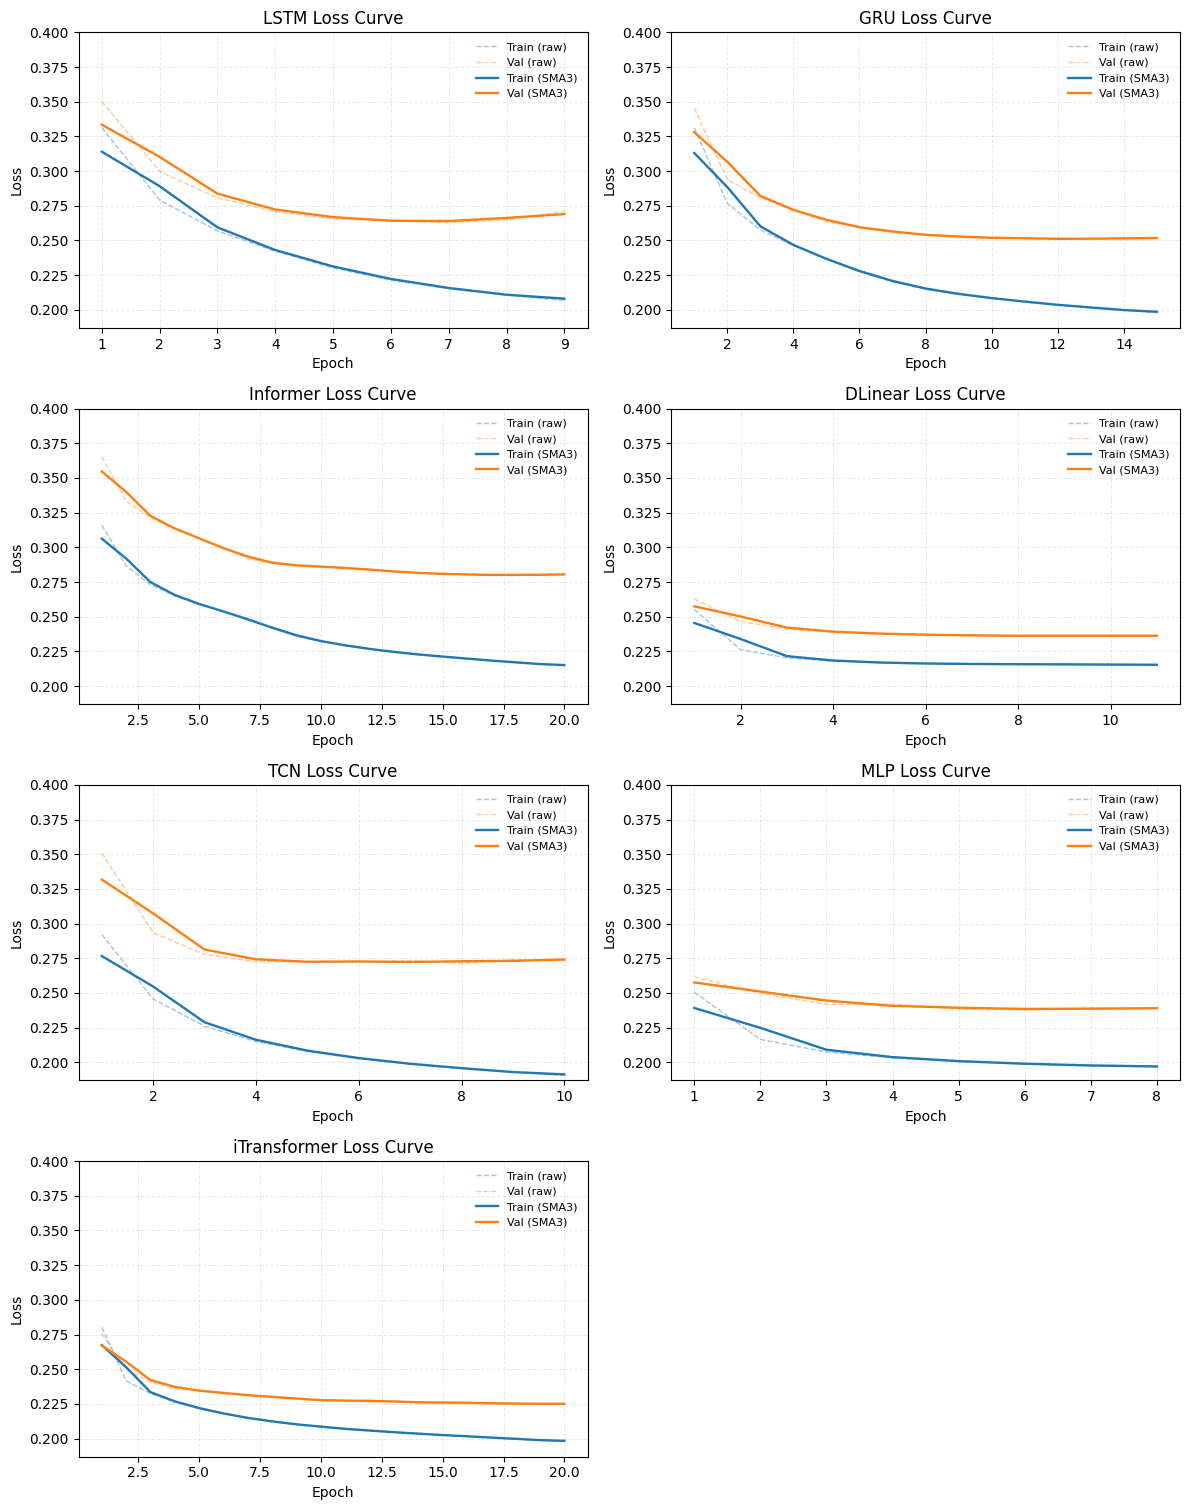

Figure written: outputs/figures/dl_loss_curves_all_models.png
Plot options -> smoothing window: 3, unified_y_axis: True, padding_ratio: 0.02, y_round_step: 0.05, use_manual_ylim: False
Unified y-limits -> [0.1869, 0.4000]


In [30]:
# Visualize training and validation loss curves for all trained DL models, with consistent y-axis scaling for fair comparison.

if 'dl_histories' not in globals() or len(dl_histories) == 0:
    print('DL histories are unavailable. Run one or more per-model DL training cells first.')
else:
    def _sma(arr, window=3):
        """Simple moving average."""
        arr = np.asarray(arr, dtype=np.float32)
        w = int(max(1, window))
        if (w <= 1) or (arr.size < w):
            return arr
        kernel = np.ones(w, dtype=np.float32) / float(w)
        pad_l = w // 2
        pad_r = w - 1 - pad_l
        padded = np.pad(arr, (pad_l, pad_r), mode='edge')
        return np.convolve(padded, kernel, mode='valid')

    def _round_up_to_step(v, step=0.05, eps=1e-6):
        """Rounds up a value to the nearest multiple of step."""
        step = float(max(1e-6, step))
        # Subtract a tiny epsilon to avoid floating-point boundary inflation,
        return float(np.ceil((float(v) - float(eps)) / step) * step)

    n_models = len(dl_histories)
    n_cols = 2
    n_rows = int(np.ceil(n_models / n_cols))

    smooth_w = int(CONFIG.get('loss_plot_smoothing_window', 3))
    y_min_cfg = CONFIG.get('loss_plot_ymin', None)
    y_max_cfg = CONFIG.get('loss_plot_ymax', None)
    y_pad_ratio = float(CONFIG.get('loss_plot_padding_ratio', 0.02))
    y_round_step = float(CONFIG.get('loss_plot_y_round_step', 0.05))
    use_manual_ylim = bool(CONFIG.get('loss_plot_use_manual_ylim', False))

    # Use a unified y-axis across all model subplots for fair visual comparison.
    share_y = True
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 3.8 * n_rows), squeeze=False, sharey=share_y)

    global_vals = []
    global_vals_for_top = []
    for _, hist in dl_histories.items():
        tr_raw = np.asarray(hist.get('train', []), dtype=np.float32)
        va_raw = np.asarray(hist.get('val', []), dtype=np.float32)
        if tr_raw.size and va_raw.size:
            n_ep = min(len(tr_raw), len(va_raw))
            tr_raw = tr_raw[:n_ep]
            va_raw = va_raw[:n_ep]
            global_vals.append(tr_raw)
            global_vals.append(va_raw)
            # Use smoothed curves to determine top bound for cleaner visual framing.
            global_vals_for_top.append(_sma(tr_raw, smooth_w))
            global_vals_for_top.append(_sma(va_raw, smooth_w))

    if len(global_vals) > 0:
        all_vals = np.concatenate(global_vals)
        gmin = float(np.nanmin(all_vals))
        gspan = max(1e-6, float(np.nanmax(all_vals)) - gmin)
        gpad = max(1e-6, y_pad_ratio * gspan)
        global_ymin = gmin - gpad

        top_vals = np.concatenate(global_vals_for_top) if len(global_vals_for_top) > 0 else all_vals
        gmax_top = float(np.nanmax(top_vals))
        global_ymax = _round_up_to_step(gmax_top, y_round_step)
    else:
        global_ymin, global_ymax = 0.0, 1.0

    if use_manual_ylim:
        if y_min_cfg is not None:
            global_ymin = float(y_min_cfg)
        if y_max_cfg is not None:
            global_ymax = float(y_max_cfg)

    if global_ymin >= global_ymax:
        global_ymin = global_ymax - max(1e-3, 0.2 * max(abs(global_ymax), 1.0))

    for i, (name, hist) in enumerate(dl_histories.items()):
        r, c = divmod(i, n_cols)
        ax = axes[r][c]

        tr_raw = np.asarray(hist.get('train', []), dtype=np.float32)
        va_raw = np.asarray(hist.get('val', []), dtype=np.float32)
        if tr_raw.size == 0 or va_raw.size == 0:
            ax.set_title(f'{name} Loss Curve (no data)')
            ax.axis('off')
            continue

        n_ep = min(len(tr_raw), len(va_raw))
        tr_raw = tr_raw[:n_ep]
        va_raw = va_raw[:n_ep]

        tr = _sma(tr_raw, smooth_w)
        va = _sma(va_raw, smooth_w)
        ep = np.arange(1, n_ep + 1)

        ax.plot(ep, tr_raw, color='#1f77b4', alpha=0.42, linewidth=1.0, linestyle='--', label='Train (raw)', zorder=1)
        ax.plot(ep, va_raw, color='#ff7f0e', alpha=0.42, linewidth=1.0, linestyle='--', label='Val (raw)', zorder=1)
        ax.plot(ep, tr, color='#1f77b4', linewidth=1.7, label=f'Train (SMA{smooth_w})', zorder=2)
        ax.plot(ep, va, color='#ff7f0e', linewidth=1.7, label=f'Val (SMA{smooth_w})', zorder=2)

        ax.set_ylim(global_ymin, global_ymax)
        ax.set_title(f'{name} Loss Curve')
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Loss')
        ax.tick_params(axis='y', labelleft=True)
        ax.grid(alpha=0.28, linestyle='--', linewidth=0.7)
        ax.legend(fontsize=8, loc='best', frameon=False)

    for j in range(n_models, n_rows * n_cols):
        r, c = divmod(j, n_cols)
        axes[r][c].axis('off')

    plt.tight_layout()
    plt.savefig(out_path('figures', 'dl_loss_curves_all_models.png'), dpi=150)
    plt.show()
    print('Figure written: outputs/figures/dl_loss_curves_all_models.png')
    print(f'Plot options -> smoothing window: {smooth_w}, unified_y_axis: {share_y}, padding_ratio: {y_pad_ratio}, y_round_step: {y_round_step}, use_manual_ylim: {use_manual_ylim}')
    print(f'Unified y-limits -> [{global_ymin:.4f}, {global_ymax:.4f}]')

DL comparison table (normalized metrics):


,Model,MAE,MSE,RMSE,TrainTimeSec,LatencyMeanMs,LatencyP95Ms,SkillScore_MAE (%)
0,iTransformer,0.350002,0.317831,0.563765,99.245803,2.803548,3.252620,47.350993
1,DLinear,0.357331,0.337913,0.581303,12.525309,0.774067,1.035315,46.248649
2,MLP,0.368379,0.337842,0.581242,10.731435,0.539949,1.121330,44.586786
3,GRU,0.387454,0.354327,0.595254,38.479863,0.664271,0.790765,41.717309
4,LSTM,0.401490,0.375299,0.612617,30.399065,0.771833,1.359975,39.606074
5,TCN,0.408033,0.392880,0.626801,65.452216,1.552933,2.526890,38.621808
6,Informer,0.432855,0.430441,0.656080,608.852008,7.230254,8.846970,34.887927
7,Naive,0.664785,1.213897,1.101770,0.015514,0.005066,0.005305,0.000000


Best DL model by MAE: iTransformer
Per-variable metrics of the best DL model [normalized]:


,Variable,MAE,MSE,RMSE
0,OT,0.137062,0.033129,0.182013
1,LULL,0.248843,0.113657,0.337131
2,MULL,0.291657,0.164230,0.405253
3,HULL,0.327874,0.196122,0.442857
4,LUFL,0.464650,0.462966,0.680416
5,MUFL,0.488015,0.641979,0.801236
6,HUFL,0.491916,0.612735,0.782774


Figure written: outputs/figures/iTransformer_top_20_difficult_variables.png


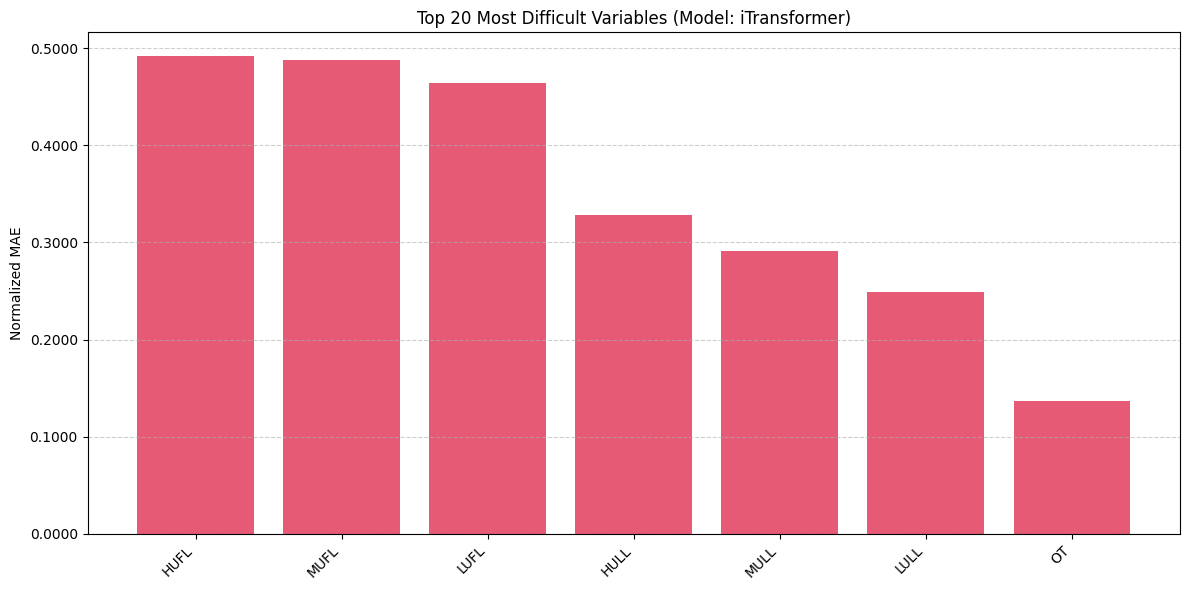

In [32]:
# Compile DL results into a comparison table, identify the best model by MAE, and display per-variable metrics for the best model.

dl_result_df = pd.DataFrame(results)
compare_models = list(active_dl_models) + ['Naive']
dl_result_df = dl_result_df[dl_result_df['Model'].isin(compare_models)].copy()
dl_result_df = dl_result_df.sort_values(['MAE', 'MSE']).reset_index(drop=True)
if 'Naive' in dl_result_df['Model'].values:
    naive_mae = dl_result_df.loc[dl_result_df['Model'] == 'Naive', 'MAE'].values[0]
    dl_result_df['SkillScore_MAE (%)'] = (1 - dl_result_df['MAE'] / naive_mae) * 100

if len(dl_result_df) == 0:
    print('No DL results found.')
else:
    print('DL comparison table (normalized metrics):')
    display(dl_result_df.reindex(columns=['Model', 'MAE', 'MSE', 'RMSE', 'TrainTimeSec', 'LatencyMeanMs', 'LatencyP95Ms', 'SkillScore_MAE (%)']).dropna(axis=1, how='all'))    
    best_dl_model = dl_result_df.iloc[0]['Model']
    print(f'Best DL model by MAE: {best_dl_model}')

    if f"{best_dl_model}_M96" in per_variable_reports:
        print('Per-variable metrics of the best DL model [normalized]:')
        display(per_variable_reports[f"{best_dl_model}_M96"]['normalized'])

        pv_df = per_variable_reports[f"{best_dl_model}_M96"]['normalized']
        top_n = 20
        plot_df = pv_df.sort_values('MAE', ascending=False).head(top_n)

        plt.figure(figsize=(12, 6))
        plt.bar(plot_df['Variable'], plot_df['MAE'], color='crimson', alpha=0.7)
        plt.xticks(rotation=45, ha='right')
        plt.gca().yaxis.set_major_formatter(plt.FormatStrFormatter('%.4f'))
        plt.title(f'Top {top_n} Most Difficult Variables (Model: {best_dl_model})')
        plt.ylabel('Normalized MAE')
        plt.grid(axis='y', linestyle='--', alpha=0.6)
        plt.tight_layout()
        plt.savefig(out_path('figures', f'{best_dl_model}_top_{top_n}_difficult_variables.png'), dpi=150)
        print(f'Figure written: outputs/figures/{best_dl_model}_top_{top_n}_difficult_variables.png')
        plt.show()

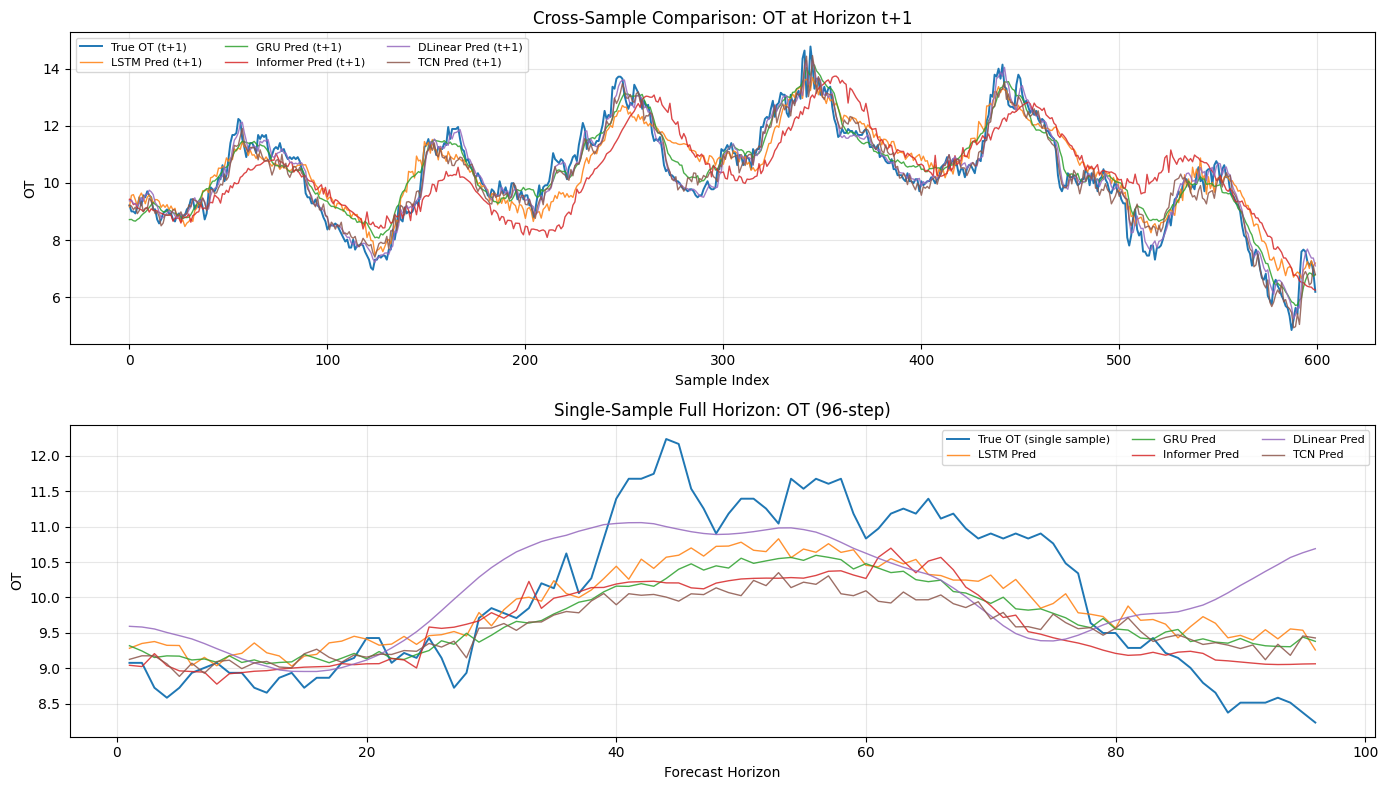

Figure written: outputs/figures/dl_prediction_comparison_ot_h1_and_96step.png


In [33]:
# Visualize the OT variable predictions at horizon t+1 and across the full 96-step horizon for all trained DL models, compared to true values.

if 'dl_outputs' not in globals() or len(dl_outputs) == 0:
    print('DL outputs are unavailable. Run one or more per-model DL training cells first.')
else:
    ot_idx = target_cols.index('OT')
    ot_h1_col = ot_idx
    model_names = list(dl_outputs.keys())
    plot_models = model_names[:min(5, len(model_names))]
    ref_true_inv = dl_outputs[plot_models[0]]['true_inv']

    n_show = min(600, len(ref_true_inv))
    sample_idx = min(12, len(ref_true_inv) - 1)
    h = np.arange(1, pred_len + 1)

    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)

    axes[0].plot(ref_true_inv[:n_show, ot_h1_col], label='True OT (t+1)', linewidth=1.4)
    for name in plot_models:
        axes[0].plot(
            dl_outputs[name]['pred_inv'][:n_show, ot_h1_col],
            label=f'{name} Pred (t+1)',
            linewidth=1.0,
            alpha=0.85
        )
    axes[0].set_title('Cross-Sample Comparison: OT at Horizon t+1')
    axes[0].set_xlabel('Sample Index')
    axes[0].set_ylabel('OT')
    axes[0].grid(alpha=0.3)
    axes[0].legend(ncol=3, fontsize=8)

    true_seq = ref_true_inv[sample_idx].reshape(pred_len, target_dim)[:, ot_idx]
    axes[1].plot(h, true_seq, label='True OT (single sample)', linewidth=1.4)
    for name in plot_models:
        pred_seq = dl_outputs[name]['pred_inv'][sample_idx].reshape(pred_len, target_dim)[:, ot_idx]
        axes[1].plot(h, pred_seq, label=f'{name} Pred', linewidth=1.0, alpha=0.85)
    axes[1].set_title('Single-Sample Full Horizon: OT (96-step)')
    axes[1].set_xlabel('Forecast Horizon')
    axes[1].set_ylabel('OT')
    axes[1].grid(alpha=0.3)
    axes[1].legend(ncol=3, fontsize=8)

    plt.tight_layout()
    plt.savefig(out_path('figures', 'dl_prediction_comparison_ot_h1_and_96step.png'), dpi=150)
    plt.show()
    print('Figure written: outputs/figures/dl_prediction_comparison_ot_h1_and_96step.png')

# 6. Model Comparison and Visualization

This section consolidates model outputs into a unified comparison table and visual trade-off views for accuracy, latency, and training cost.
It generates standardized artifacts used for final selection and reporting.

In [40]:
# Build results DataFrame from all model runs
all_results_df = pd.DataFrame(results)

# Validate required columns exist
required_cols = [
    'Task', 'Model', 'MAE', 'MSE', 'RMSE',
    'TrainTimeSec', 'LatencyMeanMs', 'LatencyP95Ms'
]
missing_cols = [c for c in required_cols if c not in all_results_df.columns]
if missing_cols:
    raise ValueError(f'Missing required columns in results: {missing_cols}')

# Filter to M-96 task and compute latency compliance flag
result_df = all_results_df[all_results_df['Task'] == 'M-96'].reset_index(drop=True)
LATENCY_THRESHOLD_MS = 50.0
result_df['MeetsLatency<50ms'] = result_df['LatencyP95Ms'] < LATENCY_THRESHOLD_MS

# Compute SkillScore_MAE (%) relative to Naive baseline
naive_row = result_df[result_df['Model'] == 'Naive']
if len(naive_row) > 0:
    naive_mae = float(naive_row.iloc[0]['MAE'])
    result_df['SkillScore_MAE (%)'] = (
        (naive_mae - result_df['MAE']) / naive_mae * 100.0
    ).round(2)
else:
    result_df['SkillScore_MAE (%)'] = float('nan')

# ---------------------------------------------------------------------------
# Energy & carbon estimation
# Power assumptions (kW):
#   GPU (CUDA) : 0.25 kW  — conservative single-GPU TDP fraction
#   CPU        : 0.065 kW — typical server CPU under load
# Carbon intensity: 0.475 kgCO2e/kWh (global average)
# Per-model energy = power_kw * (TrainTimeSec / 3600)
# Note: Power/carbon constants are heuristic estimates for relative ranking only, not intended for precise physical accounting.
# ---------------------------------------------------------------------------
run_device = globals().get('device', torch.device('cuda' if torch.cuda.is_available() else 'cpu'))
POWER_KW = 0.25 if run_device.type == 'cuda' else 0.065
CARBON_INTENSITY = 0.475  # kgCO2e per kWh

result_df['EnergyKWh'] = (result_df['TrainTimeSec'] / 3600.0 * POWER_KW).round(8)
result_df['CO2g'] = (result_df['EnergyKWh'] * CARBON_INTENSITY * 1000.0).round(4)

total_energy_kwh = float(result_df['EnergyKWh'].sum())
total_co2_g = float(result_df['CO2g'].sum())


def style_top3(df):
    """Highlight top-3 performers per metric; works on both dark and light backgrounds."""
    low_is_better = [
        'MAE', 'MSE', 'RMSE', 'TrainTimeSec',
        'LatencyMeanMs', 'LatencyP95Ms', 'EnergyKWh', 'CO2g'
    ]
    high_is_better = ['SkillScore_MAE (%)']
    metric_cols = low_is_better + high_is_better

    # Rank 1: deep teal  |  Rank 2: steel blue  |  Rank 3: slate purple
    colors = {1: '#1a7a6e', 2: '#2a6496', 3: '#5b4a8a'}

    def color_col(col):
        """Apply background color to top 3 rows based on column value."""
        style = ['' for _ in col]
        if col.name in metric_cols and len(col) > 0:
            ascending = col.name in low_is_better
            order = np.argsort(col.values if ascending else -col.values)
            for rank, idx in enumerate(order[:min(3, len(col))], start=1):
                style[idx] = (
                    f'background-color: {colors[rank]}; '
                    f'color: #ffffff; font-weight: 700;'
                )
        return style

    fmt = {
        'MAE': '{:.6f}', 'MSE': '{:.6f}', 'RMSE': '{:.6f}',
        'SkillScore_MAE (%)': '{:.2f}%',
        'TrainTimeSec': '{:.3f}', 'LatencyMeanMs': '{:.3f}', 'LatencyP95Ms': '{:.3f}',
        'EnergyKWh': '{:.6f}', 'CO2g': '{:.4f}'
    }
    fmt = {k: v for k, v in fmt.items() if k in df.columns}
    return df.style.apply(color_col, axis=0).format(fmt)


# Sort by MAE and display comparison table
m_df = result_df.sort_values(['MAE', 'MSE']).reset_index(drop=True)

if len(m_df) == 0:
    print('No M-96 results found.')
else:
    print('Final comparison table (M-96, multivariate-to-multivariate):')
    display(style_top3(m_df))

    # Best model summary — safe column selection
    best_row_m = m_df.iloc[0]
    summary_cols = ['Model', 'MAE', 'RMSE', 'LatencyP95Ms', 'MeetsLatency<50ms',
                    'EnergyKWh', 'CO2g']
    if 'SkillScore_MAE (%)' in m_df.columns:
        summary_cols.insert(2, 'SkillScore_MAE (%)')
    print('\nTop-Ranked Model Summary:')
    display(pd.DataFrame([best_row_m[summary_cols]]))

    # Latency compliance report
    compliant = m_df[m_df['MeetsLatency<50ms'] == True]
    non_compliant = m_df[m_df['MeetsLatency<50ms'] == False]
    print(f'\nLatency Compliance Report (threshold: {LATENCY_THRESHOLD_MS} ms P95):')
    print(f'  Compliant models  : {len(compliant)} — {list(compliant["Model"])}')
    print(f'  Non-compliant     : {len(non_compliant)} — {list(non_compliant["Model"])}')

# Summary footer
print(f'\nTotal train time  (M-96): {result_df["TrainTimeSec"].sum():.2f} sec')
print(f'Total energy      (M-96): {total_energy_kwh:.6f} kWh'
      f'  (device={run_device.type}, power={POWER_KW} kW)')
print(f'Total CO2 emitted (M-96): {total_co2_g:.4f} g CO2e'
      f'  (intensity={CARBON_INTENSITY} kgCO2e/kWh)')
print('Note: Energy and carbon estimates are heuristic and intended for relative comparison, not precise accounting.')

# Persist metric tables
result_df.to_csv(out_path('tables', 'final_metrics_m96.csv'), index=False)
all_results_df.to_csv(out_path('tables', 'final_metrics_table_all_tasks.csv'), index=False)
print('Metric tables written: outputs/tables/final_metrics_m96.csv'
      ' and outputs/tables/final_metrics_table_all_tasks.csv')


Final comparison table (M-96, multivariate-to-multivariate):


,Task,Model,MAE,MSE,RMSE,TrainTimeSec,LatencyMeanMs,LatencyP95Ms,Explainability,MeetsLatency<50ms,SkillScore_MAE (%),EnergyKWh,CO2g
0,M-96,iTransformer,0.350002,0.317831,0.563765,99.246,2.804,3.253,Model-dependent (post-hoc),True,47.35%,0.006892,3.2737
1,M-96,DLinear,0.357331,0.337913,0.581303,12.525,0.774,1.035,Model-dependent (post-hoc),True,46.25%,0.000870,0.4132
2,M-96,MLP,0.368379,0.337842,0.581242,10.731,0.540,1.121,Model-dependent (post-hoc),True,44.59%,0.000745,0.3540
3,M-96,GRU,0.387454,0.354327,0.595254,38.480,0.664,0.791,Model-dependent (post-hoc),True,41.72%,0.002672,1.2693
4,M-96,LSTM,0.401490,0.375299,0.612617,30.399,0.772,1.360,Model-dependent (post-hoc),True,39.61%,0.002111,1.0027
5,M-96,TCN,0.408033,0.392880,0.626801,65.452,1.553,2.527,Model-dependent (post-hoc),True,38.62%,0.004545,2.1590
6,M-96,Informer,0.432855,0.430441,0.656080,608.852,7.230,8.847,Model-dependent (post-hoc),True,34.89%,0.042281,20.0837
7,M-96,Ridge,0.447693,0.437603,0.661516,0.937,0.176,0.250,High (linear coefficients),True,32.66%,0.000065,0.0309
8,M-96,KNN,0.653379,0.760602,0.872125,0.039,114.112,138.866,Low (Instance-based),False,1.72%,0.000003,0.0013
9,M-96,Naive,0.664785,1.213897,1.101770,0.016,0.005,0.005,High (Last-step repeat),True,0.00%,0.000001,0.0005



Top-Ranked Model Summary:


,Model,MAE,SkillScore_MAE (%),RMSE,LatencyP95Ms,MeetsLatency<50ms,EnergyKWh,CO2g
0,iTransformer,0.350002,47.35,0.563765,3.25262,True,0.006892,3.2737



Latency Compliance Report (threshold: 50.0 ms P95):
  Compliant models  : 9 — ['iTransformer', 'DLinear', 'MLP', 'GRU', 'LSTM', 'TCN', 'Informer', 'Ridge', 'Naive']
  Non-compliant     : 1 — ['KNN']

Total train time  (M-96): 866.68 sec
Total energy      (M-96): 0.060186 kWh  (device=cuda, power=0.25 kW)
Total CO2 emitted (M-96): 28.5883 g CO2e  (intensity=0.475 kgCO2e/kWh)
Note: Energy and carbon estimates are heuristic and intended for relative comparison, not precise accounting.
Metric tables written: outputs/tables/final_metrics_m96.csv and outputs/tables/final_metrics_table_all_tasks.csv


C:\Users\Administrator\AppData\Local\Temp\ipykernel_2780\355630033.py:159: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


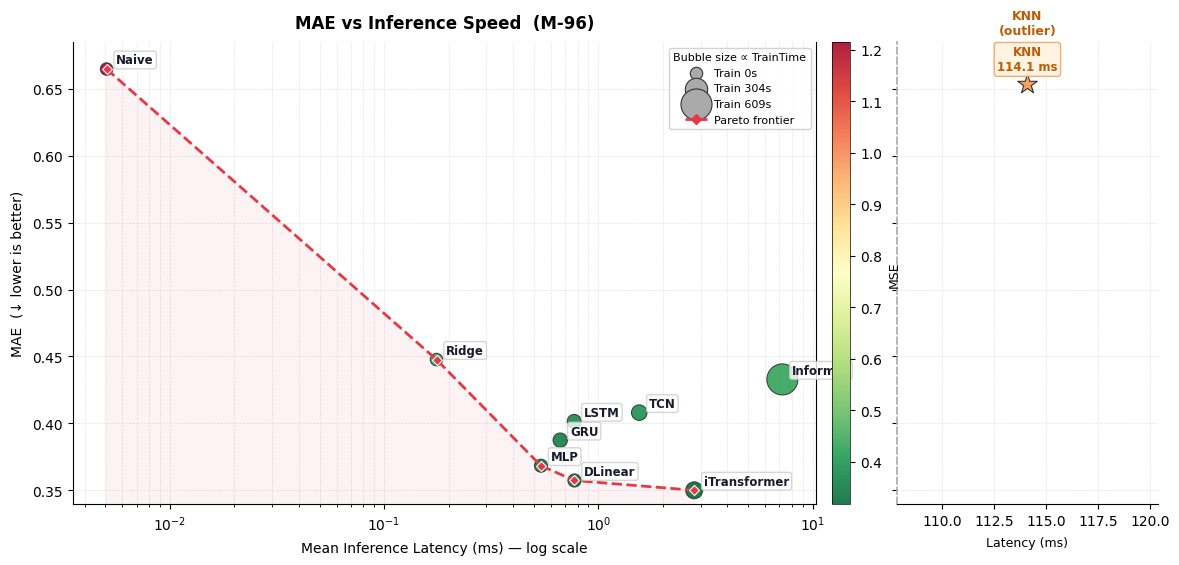

Figure written: outputs/figures/mae_vs_latencymean_tradeoff_m96.png
log_x=True | pareto_points=5 | knn_panel=True


In [45]:
# MAE vs Inference Speed Trade-off (M-96)
# Bubble size encodes training time; color encodes MSE; Pareto frontier marks optimal models.

if 'm_df' not in globals() or len(m_df) == 0:
    print('m_df is unavailable. Run the final comparison cell first.')
else:
    trade_df = m_df.dropna(subset=['MAE', 'LatencyMeanMs']).copy()

    # Separate KNN as a high-latency outlier to avoid axis compression
    knn_mask  = trade_df['Model'].astype(str).str.upper() == 'KNN'
    main_df   = trade_df[~knn_mask].reset_index(drop=True)
    knn_df    = trade_df[knn_mask].reset_index(drop=True)

    if len(main_df) == 0:
        print('No plottable rows after excluding KNN.')
    else:
        use_log_x = bool(CONFIG.get('tradeoff_use_log_x', True))

        if len(knn_df) > 0:
            fig, (ax_main, ax_knn) = plt.subplots(
                1, 2, figsize=(14, 6),
                gridspec_kw={'width_ratios': [3, 1], 'wspace': 0.08}
            )
        else:
            fig, ax_main = plt.subplots(figsize=(11, 6))
            ax_knn = None

        fig.patch.set_facecolor('white')

        # Bubble size: min-max normalised TrainTimeSec → [80, 500]
        t = np.asarray(main_df['TrainTimeSec'], dtype=float)
        t_range = max(t.max() - t.min(), 1e-6)
        sizes = 80 + 420 * (t - t.min()) / t_range

        # Colour: MSE (lower = cooler colour)
        c_vals = main_df['MSE'].values if 'MSE' in main_df.columns else main_df['MAE'].values
        cmap   = plt.cm.RdYlGn_r          # red = high MSE, green = low MSE

        sc = ax_main.scatter(
            main_df['LatencyMeanMs'], main_df['MAE'],
            s=sizes, c=c_vals, cmap=cmap,
            alpha=0.88, edgecolors='#333333', linewidths=0.8,
            zorder=3
        )

        # Pareto frontier (lower-left dominance)
        pf = main_df.sort_values('LatencyMeanMs').reset_index(drop=True)
        px, py, best = [], [], np.inf
        for _, r in pf.iterrows():
            if float(r['MAE']) < best:
                px.append(float(r['LatencyMeanMs']))
                py.append(float(r['MAE']))
                best = float(r['MAE'])

        if len(px) >= 2:
            ax_main.plot(px, py,
                         color='#E63946', lw=2.0, ls='--',
                         marker='D', ms=5,
                         mfc='#E63946', mec='white', mew=0.8,
                         zorder=4, label='Pareto frontier')
            ax_main.fill_between(px, py, alpha=0.06, color='#E63946', zorder=2)

        # Model labels
        for _, r in main_df.iterrows():
            ax_main.annotate(
                str(r['Model']),
                xy=(float(r['LatencyMeanMs']), float(r['MAE'])),
                xytext=(7, 4), textcoords='offset points',
                fontsize=8.5, fontweight='semibold', color='#1a1a2e',
                bbox=dict(boxstyle='round,pad=0.2', fc='white',
                          ec='#cccccc', alpha=0.80),
                zorder=5
            )

        # Axes formatting
        if use_log_x:
            ax_main.set_xscale('log')

        ax_main.set_xlabel(
            'Mean Inference Latency (ms)' + (' — log scale' if use_log_x else ''),
            fontsize=10, labelpad=6
        )
        ax_main.set_ylabel('MAE  (↓ lower is better)', fontsize=10, labelpad=6)
        ax_main.set_title('MAE vs Inference Speed  (M-96)',
                          fontsize=12, fontweight='bold', pad=10)
        ax_main.grid(True, which='both', ls='--', lw=0.5,
                     color='#dddddd', alpha=0.8)
        ax_main.set_axisbelow(True)
        ax_main.spines[['top', 'right']].set_visible(False)

        # Colour bar 
        cbar = fig.colorbar(sc, ax=ax_main, pad=0.02, fraction=0.03, aspect=25)
        cbar.set_label('MSE', fontsize=9)
        cbar.outline.set_linewidth(0.5)

        # Bubble-size legend
        t_lo = float(main_df['TrainTimeSec'].min())
        t_hi = float(main_df['TrainTimeSec'].max())
        t_md = (t_lo + t_hi) / 2
        legend_items = [
            plt.scatter([], [], s=80,  c='#aaaaaa', ec='#333333', lw=0.8,
                        label=f'Train {t_lo:.0f}s'),
            plt.scatter([], [], s=260, c='#aaaaaa', ec='#333333', lw=0.8,
                        label=f'Train {t_md:.0f}s'),
            plt.scatter([], [], s=500, c='#aaaaaa', ec='#333333', lw=0.8,
                        label=f'Train {t_hi:.0f}s'),
        ]
        pareto_line = plt.Line2D([0], [0], color='#E63946', lw=2,
                                 ls='--', marker='D', ms=5,
                                 label='Pareto frontier')
        ax_main.legend(
            handles=legend_items + [pareto_line],
            title='Bubble size ∝ TrainTime',
            title_fontsize=8, fontsize=8,
            loc='upper right', framealpha=0.85,
            edgecolor='#cccccc', handletextpad=0.6
        )

        # KNN panel (right subplot)
        if ax_knn is not None and len(knn_df) > 0:
            for _, r in knn_df.iterrows():
                ax_knn.scatter(
                    [float(r['LatencyMeanMs'])], [float(r['MAE'])],
                    s=220, marker='*', color='#F4A261',
                    edgecolors='#333333', lw=0.8, zorder=3
                )
                ax_knn.annotate(
                    f"KNN\n{float(r['LatencyMeanMs']):.1f} ms",
                    xy=(float(r['LatencyMeanMs']), float(r['MAE'])),
                    xytext=(0, 10), textcoords='offset points',
                    ha='center', fontsize=8.5, fontweight='bold',
                    color='#c05c00',
                    bbox=dict(boxstyle='round,pad=0.25', fc='#fff3e0',
                              ec='#F4A261', alpha=0.9),
                    zorder=5
                )

            ax_knn.set_xlabel('Latency (ms)', fontsize=9, labelpad=6)
            ax_knn.set_title('KNN\n(outlier)', fontsize=9,
                             fontweight='bold', color='#c05c00')
            ax_knn.grid(True, ls='--', lw=0.5, color='#dddddd', alpha=0.8)
            ax_knn.set_axisbelow(True)
            ax_knn.spines[['top', 'right']].set_visible(False)
            ax_knn.yaxis.set_tick_params(labelleft=False)

            # Shared y-axis range for visual consistency
            y_lo = min(main_df['MAE'].min(), knn_df['MAE'].min()) * 0.97
            y_hi = max(main_df['MAE'].max(), knn_df['MAE'].max()) * 1.03
            ax_main.set_ylim(y_lo, y_hi)
            ax_knn.set_ylim(y_lo, y_hi)

            # Broken-axis indicator
            for spine in ['left', 'right']:
                ax_main.spines[spine].set_visible(True)
            ax_knn.spines['left'].set_linestyle((0, (4, 2)))
            ax_knn.spines['left'].set_linewidth(1.2)
            ax_knn.spines['left'].set_color('#aaaaaa')

        plt.tight_layout()
        plt.savefig(
            out_path('figures', 'mae_vs_latencymean_tradeoff_m96.png'),
            dpi=150, bbox_inches='tight', facecolor='white'
        )
        plt.show()
        print('Figure written: outputs/figures/mae_vs_latencymean_tradeoff_m96.png')
        print(f'log_x={use_log_x} | pareto_points={len(px)} | knn_panel={len(knn_df)>0}')
